# Different faces, seeds, and visibility levels

The updated 729-recipe model includes dots, arches, and oval pupils, with category
associations learned from training. Both figure-generating cells are rerun for 27 cases.
Each category has three distinct held-out recipes, chosen reproducibly without
screening the outcomes. For each recipe/seed, the same random block mask pattern
is thresholded at 15%, 35%, and 65% requested visibility. Thus the visible regions
are nested, and the underlying flip pattern stays fixed within each recipe.
Actual visibility is shown in each figure and recorded in the CSV.

Training split/seed, learned priors, vector codebook, and 5% flip probability are
fixed. Both figure types use full-candidate inference with VSA evidence. The prior
comparison uses strength 1. The cue comparison retains the original cell's no-cue
strength 1 and correct/wrong cue strength 3. Wrong cues cycle cow→cat→human→cow.
Category names describe the synthetic sampling distributions. Individual recipes
can mix traits from different categories.

The original notebook and its existing figures are preserved. New figures and
`metrics.csv` are saved beside this notebook. Each case below prints its recipe.


In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
ROOT = Path.cwd()
while not (ROOT / "closure_model.py").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Run from within BayesContourProcessing")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from closure_model import *
from vsa_inference import PixelVSA, FactorVSA, posterior, entropy
OUT_ROOT = ROOT / "outputs" / "seed_visibility_runs_2026-11-16"
OUT_ROOT.mkdir(exist_ok=True)


In [2]:
SEED = 7
IMAGE_SIZE = 40
VSA_DIM = 512
MESSAGE_DIM = 64
FLIP_PROBABILITY = .05
N_TRAIN_PER_CLASS = 250
EXEMPLAR_PRECISION = 2.5
PRIOR_STRENGTH = 1.
CUE_STRENGTH = 3.
DEMO_MASK = "blocks"
RUN_SEEDS = (17, 37, 67)
RUN_VISIBILITIES = (.15, .35, .65)

library = make_library(size=IMAGE_SIZE, seed=SEED)
training_ids, training_labels = sample_training(library, N_TRAIN_PER_CLASS, seed=SEED+4)
bank = fit_priors(library, training_ids, training_labels, category_learning="counts", exemplar_precision=EXEMPLAR_PRECISION)
encoder = PixelVSA(IMAGE_SIZE, dim=VSA_DIM, seed=SEED+10)
factor_vsa = FactorVSA(CARDINALITIES, dim=MESSAGE_DIM, seed=SEED+20)
assert set(training_ids).isdisjoint(set(library.test_ids))


In [3]:
demo_source = 'demo_id = CASE_STATE_ID\ntruth = library.images[demo_id]\nrng = np.random.default_rng(DEMO_SEED)\nif DEMO_MASK == "top":\n    mask = np.broadcast_to(np.arange(IMAGE_SIZE)[:, None] < round(IMAGE_SIZE*DEMO_VISIBILITY),\n                           truth.shape).copy()\nelif DEMO_MASK == "blocks":\n    mask = block_mask(IMAGE_SIZE, DEMO_VISIBILITY, rng)\nelse:\n    raise ValueError("DEMO_MASK must be top or blocks")\nobserved = observe(truth, mask, FLIP_PROBABILITY, rng)\n# Only the observed pixels and the mask enter the evidence function.\ndemo_scores = {backend: encoder.evidence_scores(library.images, observed, mask,\n                        FLIP_PROBABILITY, backend) for backend in ("pixels", "vsa")}\ndemo_q = {name: posterior(demo_scores["vsa"], bank.logpriors[name], PRIOR_STRENGTH)\n          for name in PRIOR_NAMES}\ndemo_predictions = {name: prediction(q, library.images) for name, q in demo_q.items()}\n\nfig, axes = plt.subplots(2, 6, figsize=(14, 5))\nshow_completion(axes[0, 0], truth, "Hidden truth\\nevaluation only")\nshow_observation(axes[0, 1], observed, mask, f"Input: {mask.mean():.0%} visible")\nshow_completion(axes[1, 0], observed, "Copy fragments\\nno inferred strokes")\naxes[1, 1].axis("off")\naxes[1, 1].text(.05, .5, "Top: posterior mean\\nBottom: MAP sketch\\n\\nNo category cue supplied.",\n                transform=axes[1, 1].transAxes, va="center")\nfor col, name in enumerate(PRIOR_NAMES, start=2):\n    show_completion(axes[0, col], demo_predictions[name], PRIOR_LABELS[name])\n    q = demo_q[name]\n    show_completion(axes[1, col], library.images[np.argmax(q)], f"MAP p={q.max():.6f}\\nOther mass={q.sum()-q.max():.2e}")\nfig.suptitle("Completion as prior structure changes | VSA image evidence", fontsize=14)\nfig.tight_layout()\nfig.savefig(OUT / "completion_demo.png", dpi=160, bbox_inches="tight")\nplt.show()\n\nprint(f"{\'Condition\':27s} {\'hidden Brier\':>13s} {\'hidden recall\':>14s} {\'invented/FPR\':>13s} {\'visible error\':>14s}")\nfor name, pred in [("Copy fragments", observed)] + [(PRIOR_LABELS[n], demo_predictions[n]) for n in PRIOR_NAMES]:\n    metrics = completion_metrics(pred, truth, observed, mask)\n    print(f"{name:27s} {metrics[\'hidden_brier\']:13.4f} {metrics[\'hidden_recall\']:14.3f} "\n          f"{metrics[\'hidden_false_positive\']:13.3f} {metrics[\'visible_error\']:14.3f}")'
cue_source = 'correct_cue = DEMO_CATEGORY\nwrong_cue = (DEMO_CATEGORY + 1) % len(CLASS_NAMES)\ncue_conditions = [("No cue", bank.logpriors["category"], PRIOR_STRENGTH),\n                  ("Correct cue", bank.class_logp[correct_cue], CUE_STRENGTH),\n                  ("Wrong cue", bank.class_logp[wrong_cue], CUE_STRENGTH)]\nfig, axes = plt.subplots(1, 5, figsize=(12, 2.7))\nshow_completion(axes[0], truth, "Original hidden truth")\nshow_observation(axes[1], observed, mask)\nfor ax, (label, lp, strength) in zip(axes[2:], cue_conditions):\n    q = posterior(demo_scores["vsa"], lp, strength)\n    show_completion(ax, prediction(q, library.images), label)\nfig.tight_layout(); fig.savefig(OUT / "cue_control.png", dpi=160, bbox_inches="tight"); plt.show()\n\nprint("Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass")\nfor label, lp, strength in cue_conditions:\n    q = posterior(demo_scores["vsa"], lp, strength)\n    winner = int(np.argmax(q))\n    eye_spacing = FACTOR_VALUES[2][library.states[winner, 2]]\n    eye_shape = FACTOR_VALUES[5][library.states[winner, 5]]\n    other_mass = q[np.arange(len(q)) != winner].sum()\n    print(f"{label:12s} | {q[demo_id]:.8f} | {q[winner]:.8f} | {eye_spacing} / {eye_shape} | {other_mass:.3e}")\n    print("  MAP recipe:", describe_state(library.states[winner]))\n\n'

## cow-like · seed 17 · requested visibility 15%

Recipe: {'head shape': 'tall', 'ear shape': 'long', 'eye spacing': 'wide', 'nose shape': 'muzzle', 'layout': 'aligned', 'eye shape': 'dots'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.1040          0.000         0.000          0.000
Uniform vocabulary                 0.0038          0.986         0.003          0.049
Layout prior                       0.0038          0.986         0.003          0.049
Latent categories                  0.0019          0.986         0.000          0.049
Training exemplars                 0.0037          0.986         0.003          0.049
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.37093795 | 0.37093795 | wide / dots | 6.291e-01
  MAP recipe: {'head shape': 'tall', 'ear shape': 'long', 'eye spacing': 'wide', 'nose shape': 'muzzle', 'layout': 'aligned', 'eye shape': 'dots'}
Correct cue  | 0.97211703 | 0.97211703 | wi

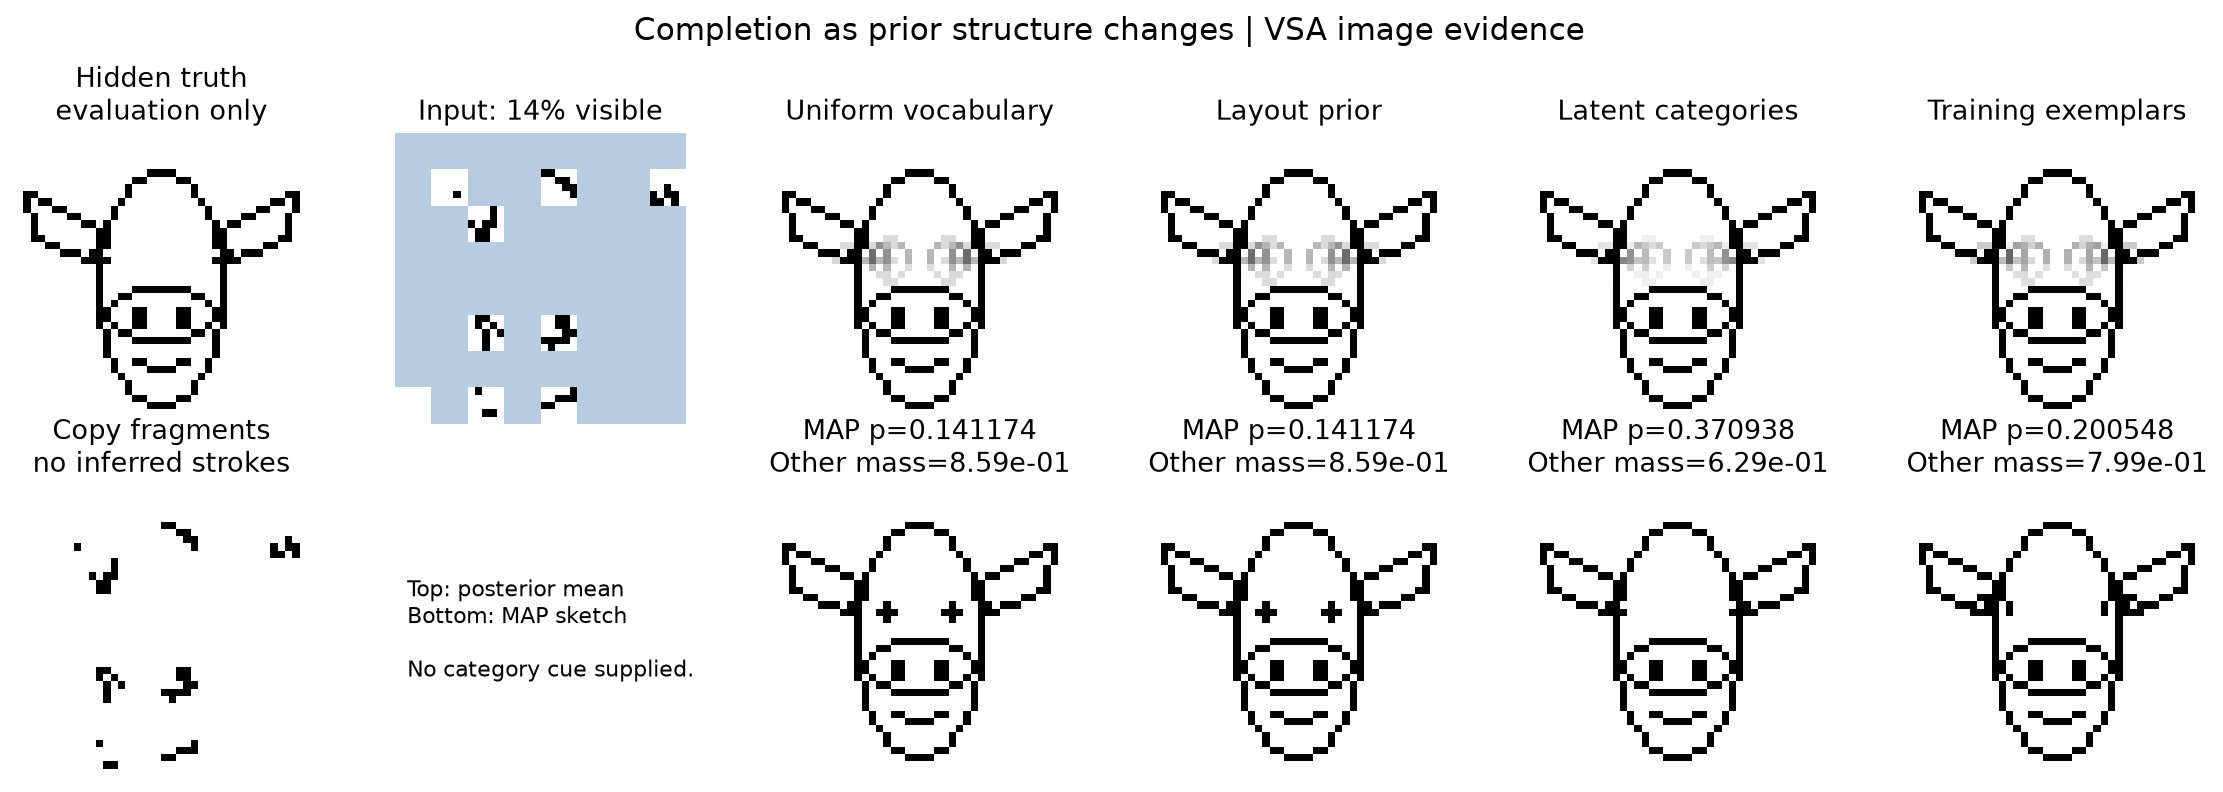

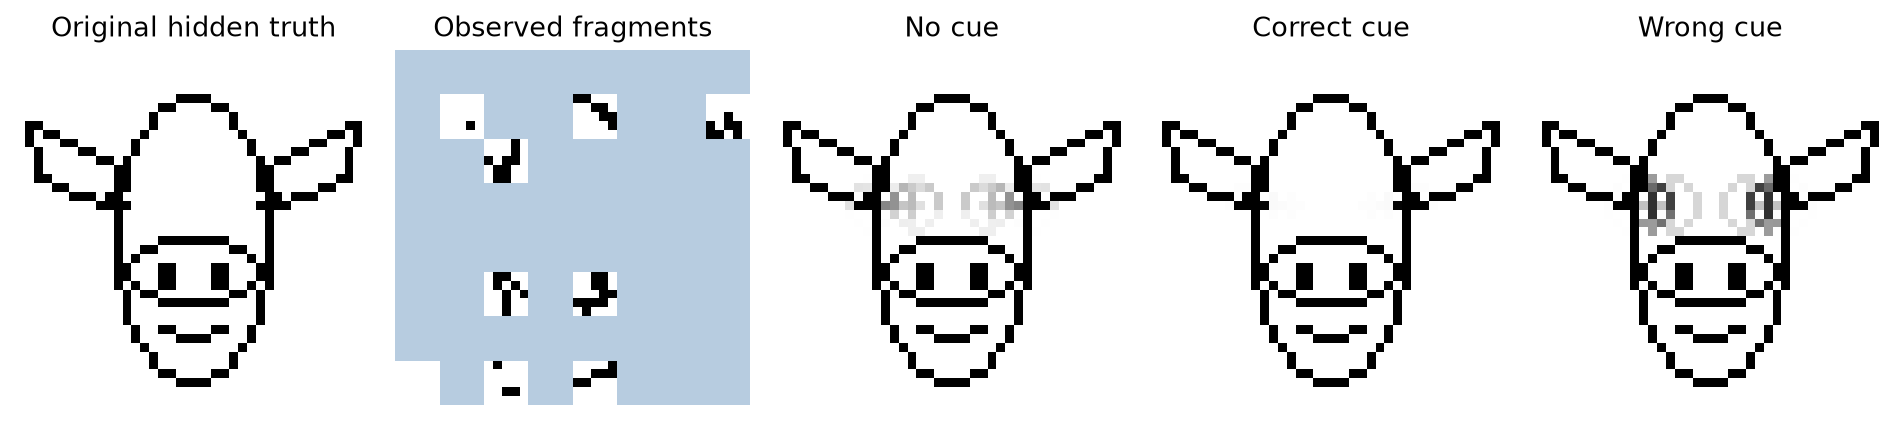

In [4]:
DEMO_CATEGORY = 0
DEMO_SEED = 17
DEMO_VISIBILITY = 0.15
CASE_STATE_ID = 720
OUT = OUT_ROOT / 'cow-like_seed17_visible15'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cow-like · seed 17 · requested visibility 35%

Recipe: {'head shape': 'tall', 'ear shape': 'long', 'eye spacing': 'wide', 'nose shape': 'muzzle', 'layout': 'aligned', 'eye shape': 'dots'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.1149          0.000         0.000          0.000
Uniform vocabulary                 0.0046          0.982         0.007          0.036
Layout prior                       0.0046          0.982         0.007          0.036
Latent categories                  0.0020          1.000         0.000          0.036
Training exemplars                 0.0026          0.982         0.007          0.036
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.40740848 | 0.47468893 | medium / arches | 5.253e-01
  MAP recipe: {'head shape': 'tall', 'ear shape': 'long', 'eye spacing': 'medium', 'nose shape': 'muzzle', 'layout': 'aligned', 'eye shape': 'arches'}
Correct cue  | 0.98983563 | 0.98983

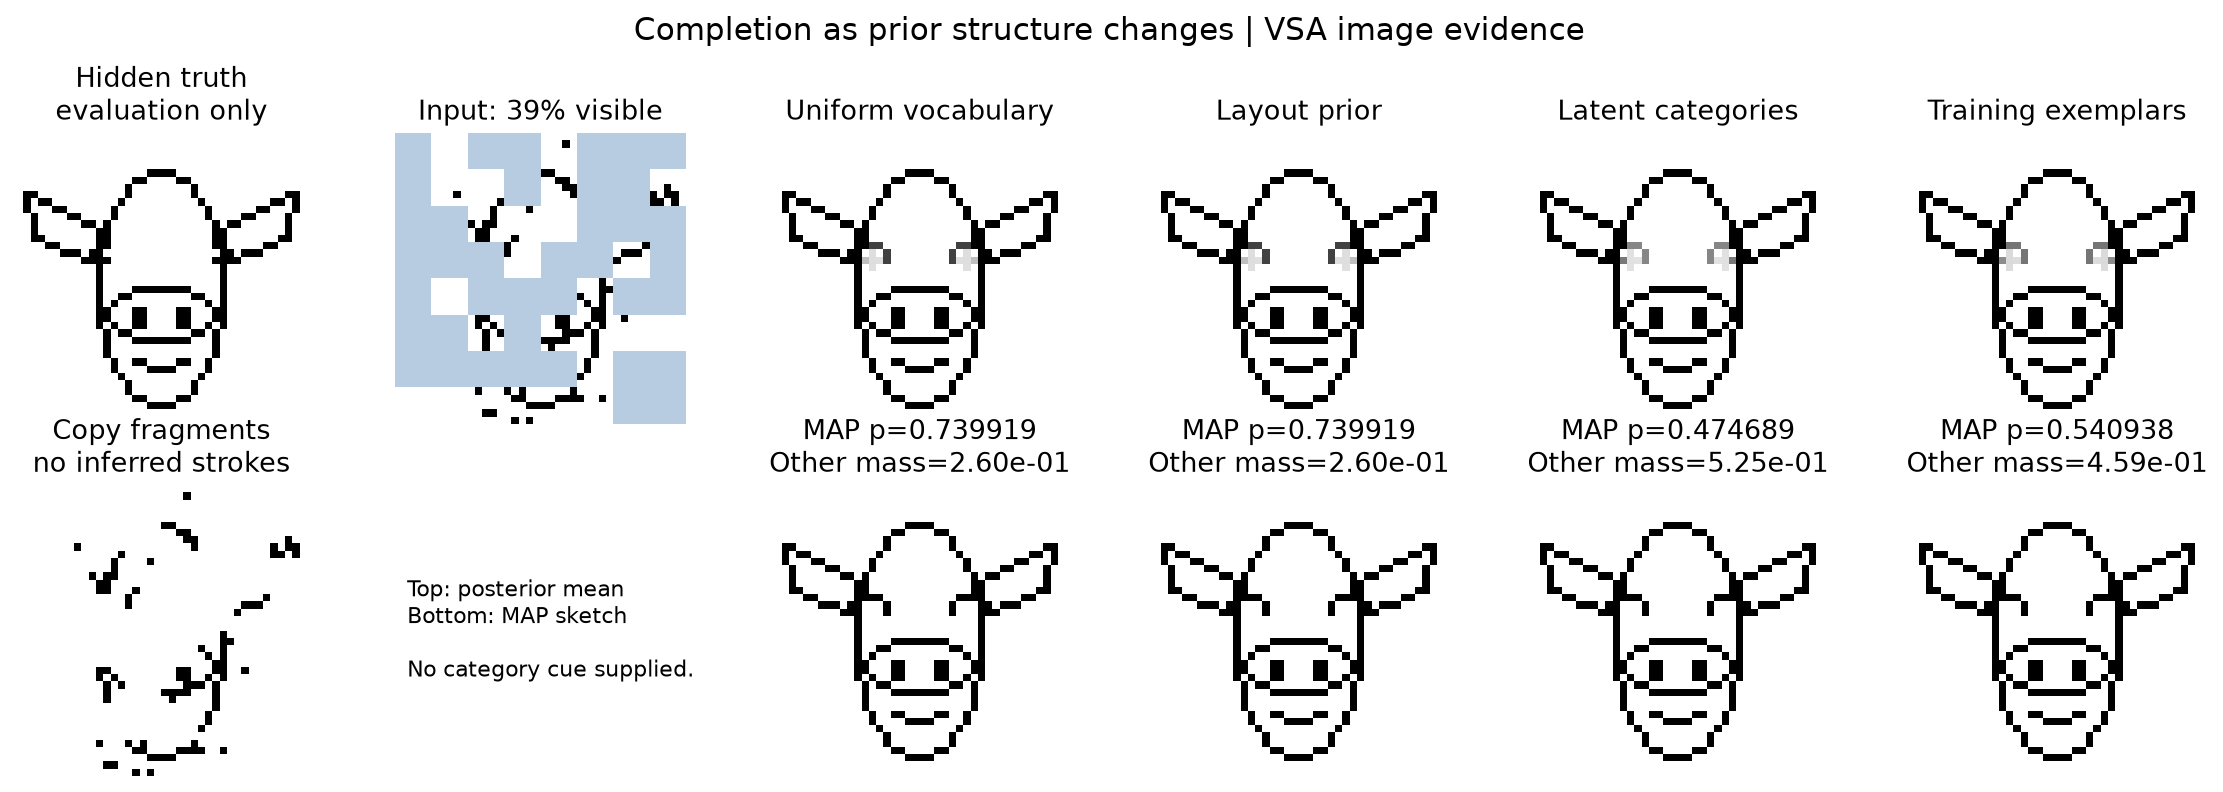

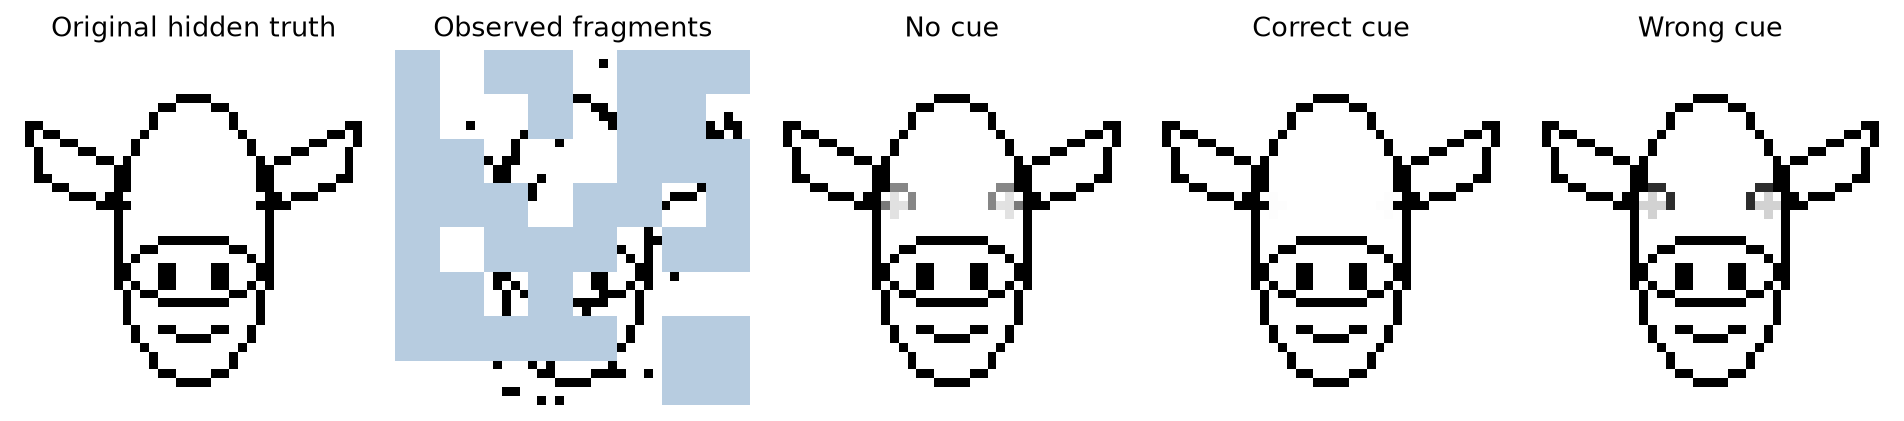

In [5]:
DEMO_CATEGORY = 0
DEMO_SEED = 17
DEMO_VISIBILITY = 0.35
CASE_STATE_ID = 720
OUT = OUT_ROOT / 'cow-like_seed17_visible35'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cow-like · seed 17 · requested visibility 65%

Recipe: {'head shape': 'tall', 'ear shape': 'long', 'eye spacing': 'wide', 'nose shape': 'muzzle', 'layout': 'aligned', 'eye shape': 'dots'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.1571          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.043
Layout prior                       0.0000          1.000         0.000          0.043
Latent categories                  0.0000          1.000         0.000          0.043
Training exemplars                 0.0000          1.000         0.000          0.043
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.99998365 | 0.99998365 | wide / dots | 1.635e-05
  MAP recipe: {'head shape': 'tall', 'ear shape': 'long', 'eye spacing': 'wide', 'nose shape': 'muzzle', 'layout': 'aligned', 'eye shape': 'dots'}
Correct cue  | 0.99999945 | 0.99999945 | wi

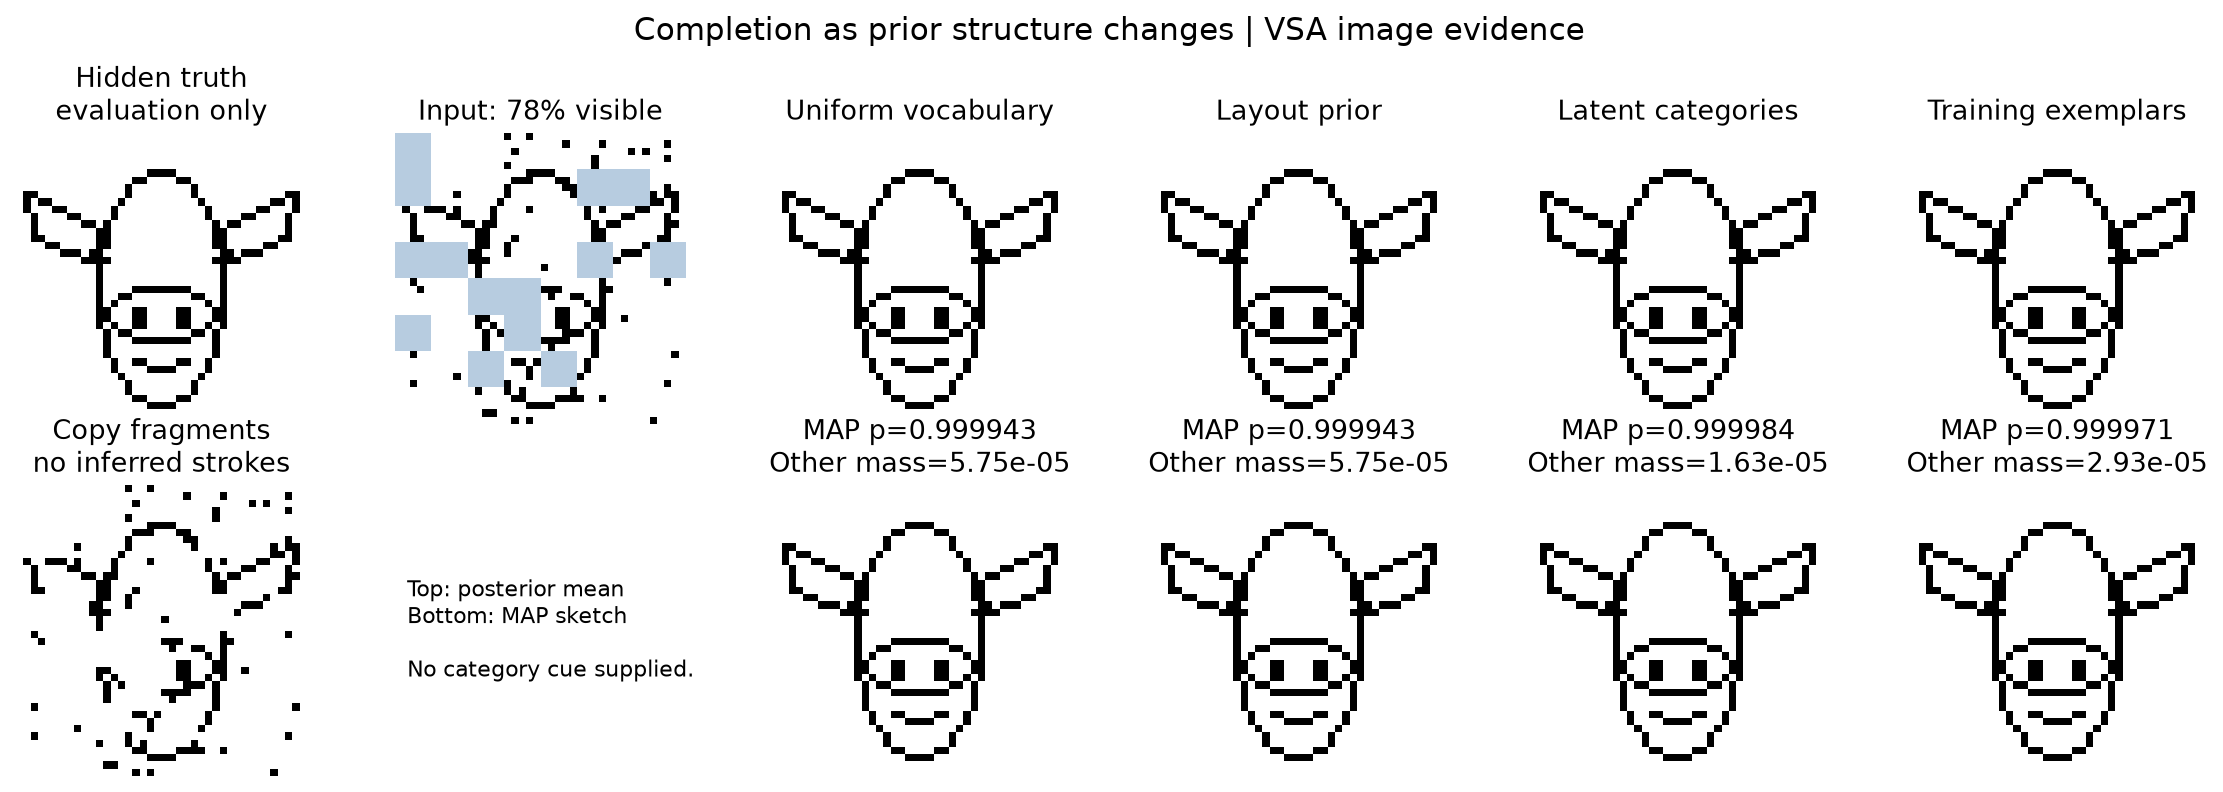

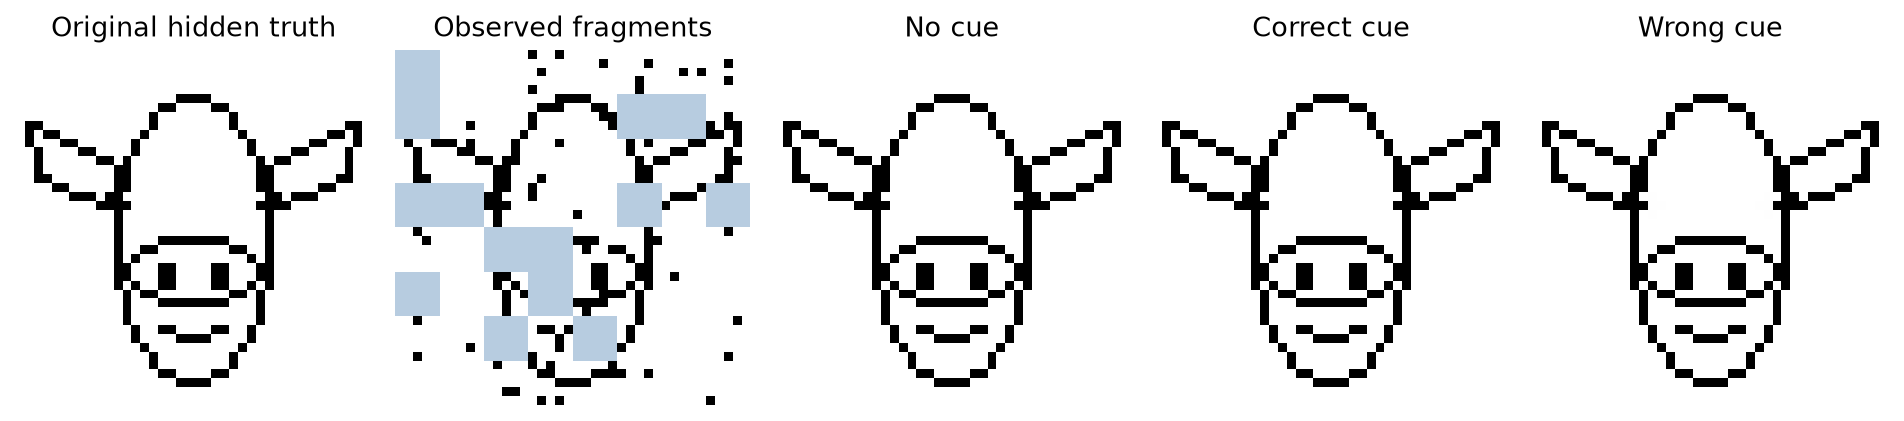

In [6]:
DEMO_CATEGORY = 0
DEMO_SEED = 17
DEMO_VISIBILITY = 0.65
CASE_STATE_ID = 720
OUT = OUT_ROOT / 'cow-like_seed17_visible65'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cow-like · seed 37 · requested visibility 15%

Recipe: {'head shape': 'wide', 'ear shape': 'long', 'eye spacing': 'wide', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'dots'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.0944          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.049
Layout prior                       0.0000          1.000         0.000          0.049
Latent categories                  0.0000          1.000         0.000          0.049
Training exemplars                 0.0000          1.000         0.000          0.049
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.99996947 | 0.99996947 | wide / dots | 3.053e-05
  MAP recipe: {'head shape': 'wide', 'ear shape': 'long', 'eye spacing': 'wide', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'dots'}
Correct cue  | 0.99997296 | 0.99997296 | wide

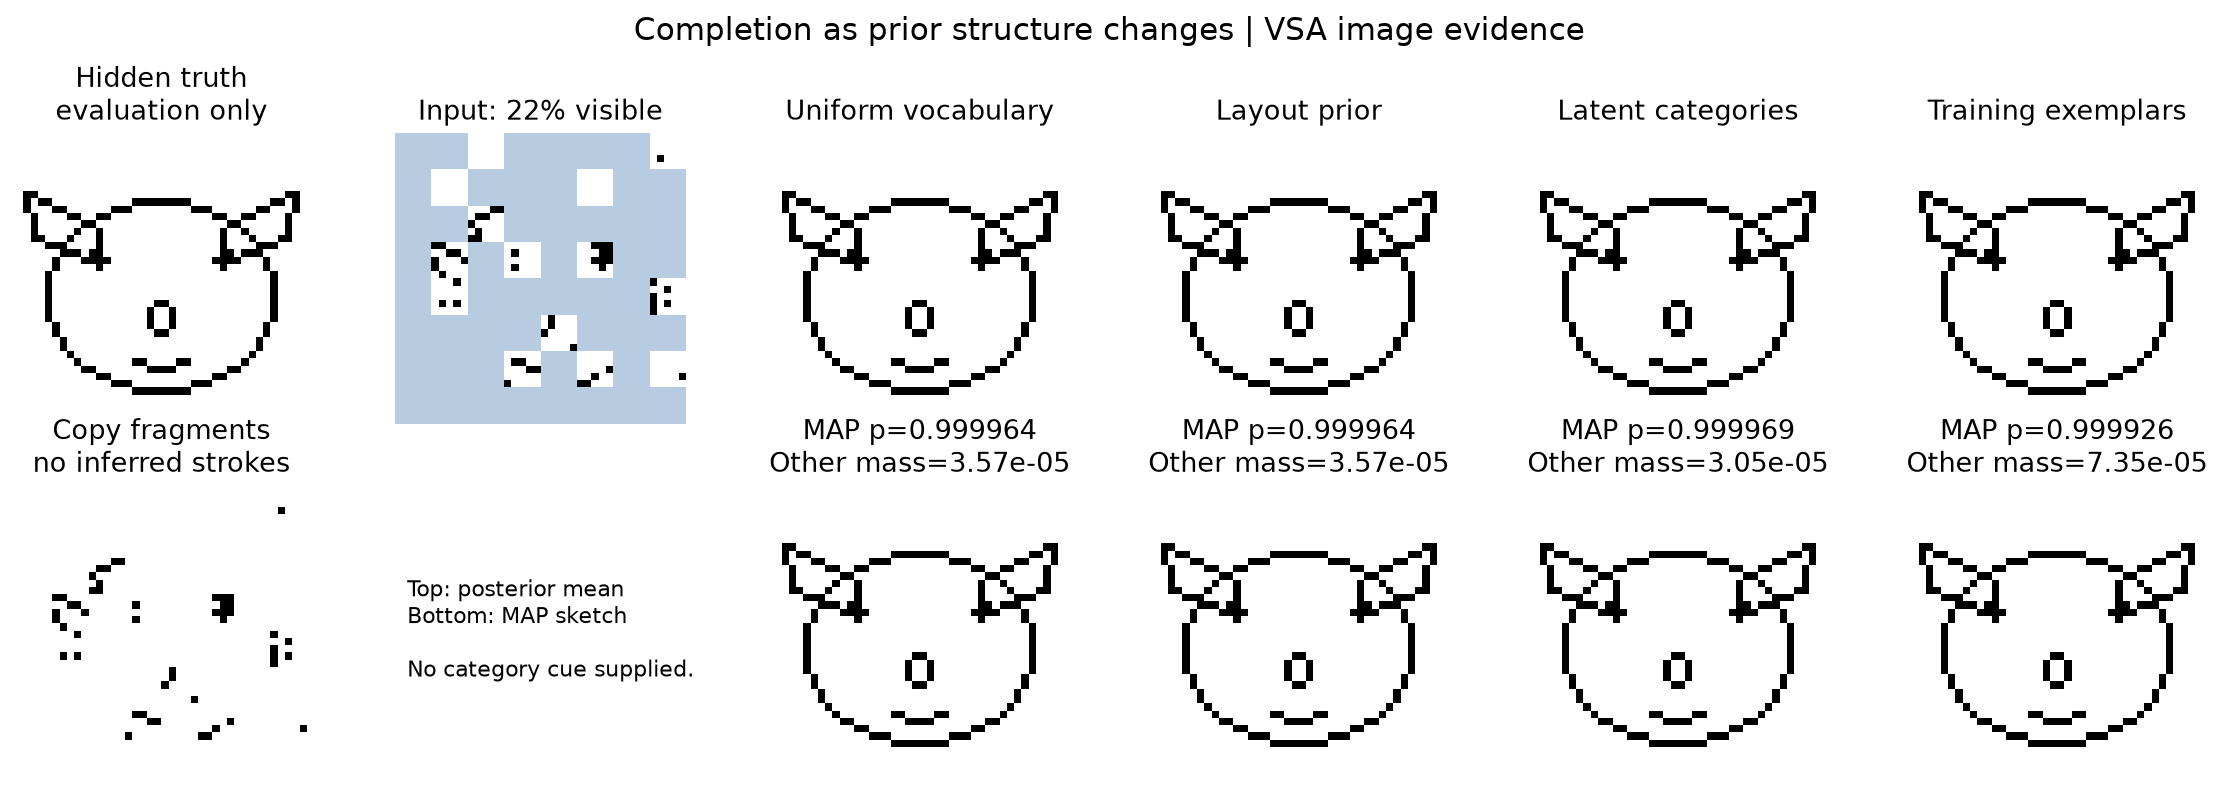

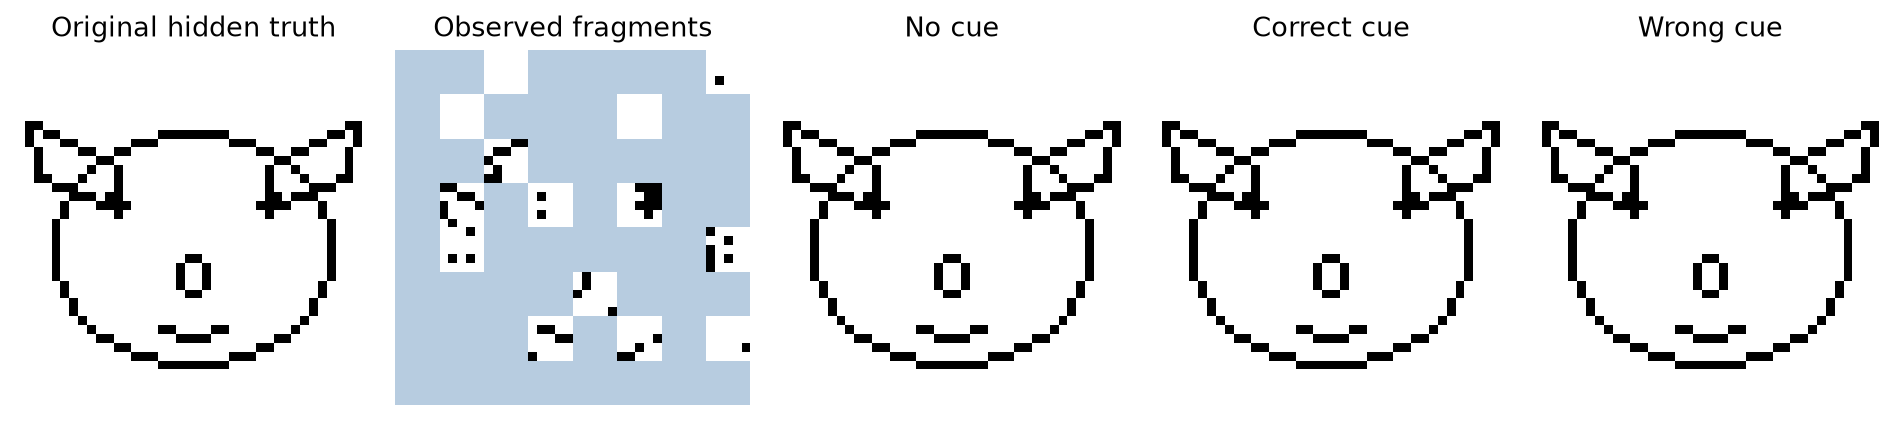

In [7]:
DEMO_CATEGORY = 0
DEMO_SEED = 37
DEMO_VISIBILITY = 0.15
CASE_STATE_ID = 468
OUT = OUT_ROOT / 'cow-like_seed37_visible15'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cow-like · seed 37 · requested visibility 35%

Recipe: {'head shape': 'wide', 'ear shape': 'long', 'eye spacing': 'wide', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'dots'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.0865          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.041
Layout prior                       0.0000          1.000         0.000          0.041
Latent categories                  0.0000          1.000         0.000          0.041
Training exemplars                 0.0000          1.000         0.000          0.041
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 1.00000000 | 1.00000000 | wide / dots | 4.389e-13
  MAP recipe: {'head shape': 'wide', 'ear shape': 'long', 'eye spacing': 'wide', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'dots'}
Correct cue  | 1.00000000 | 1.00000000 | wide

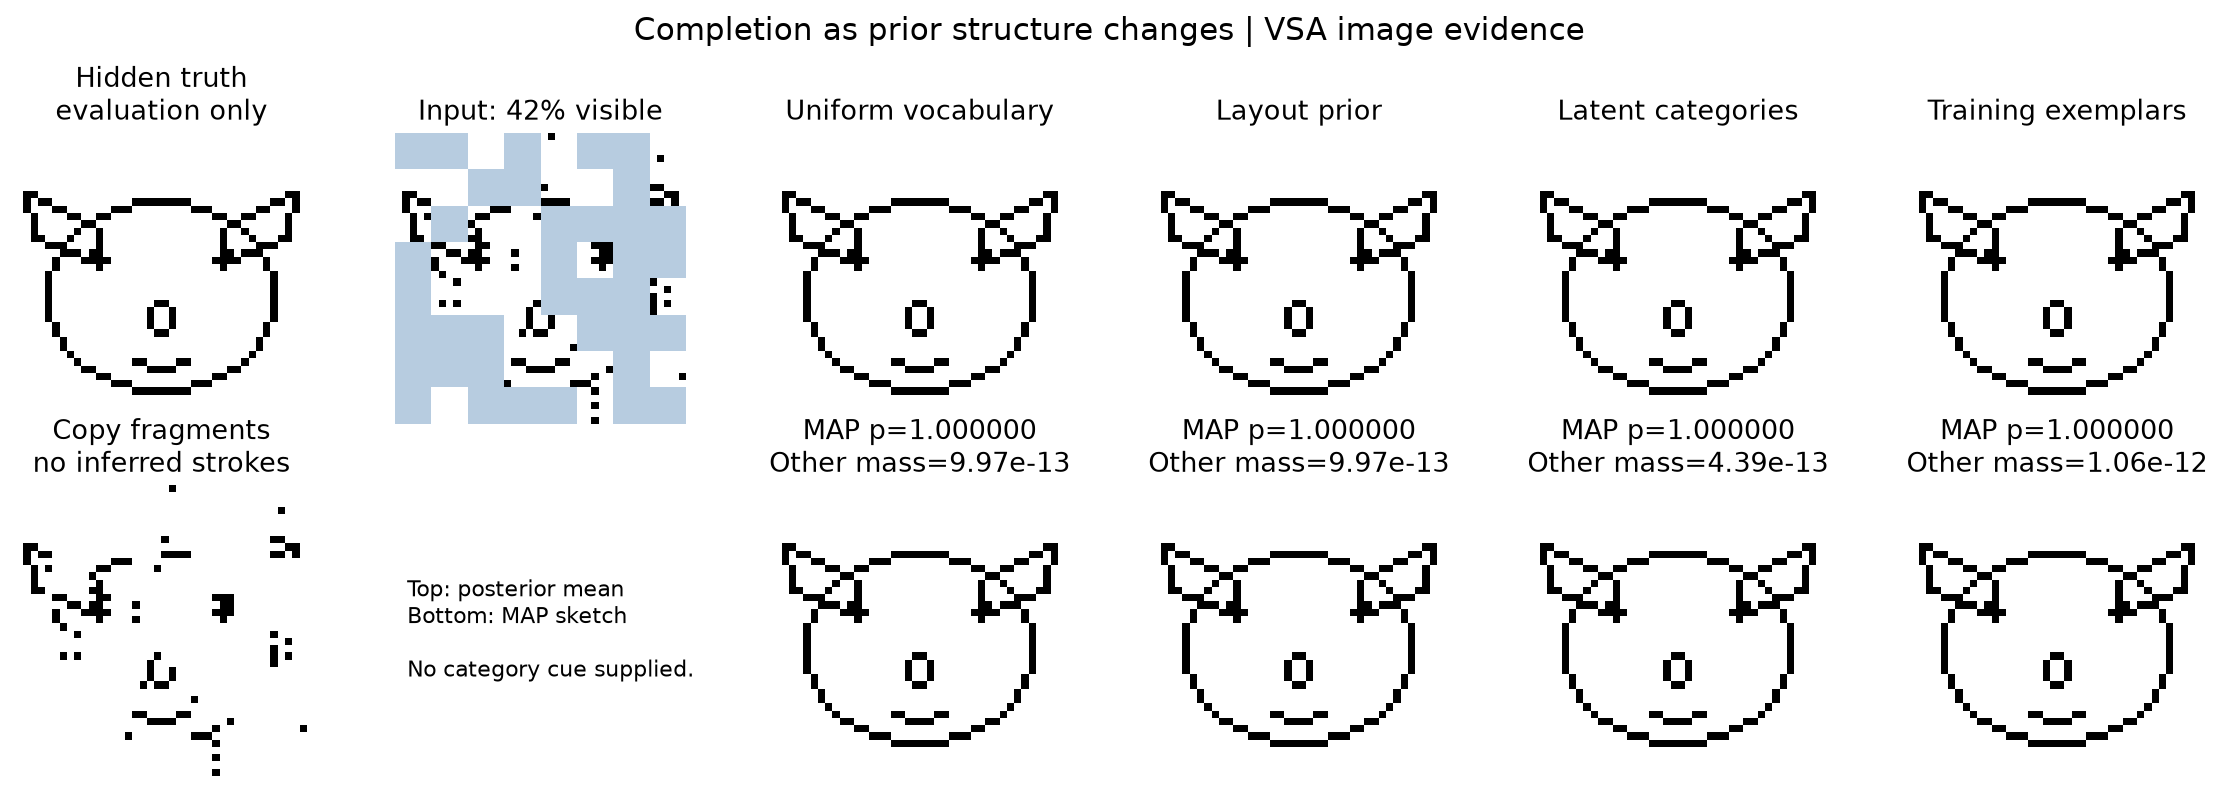

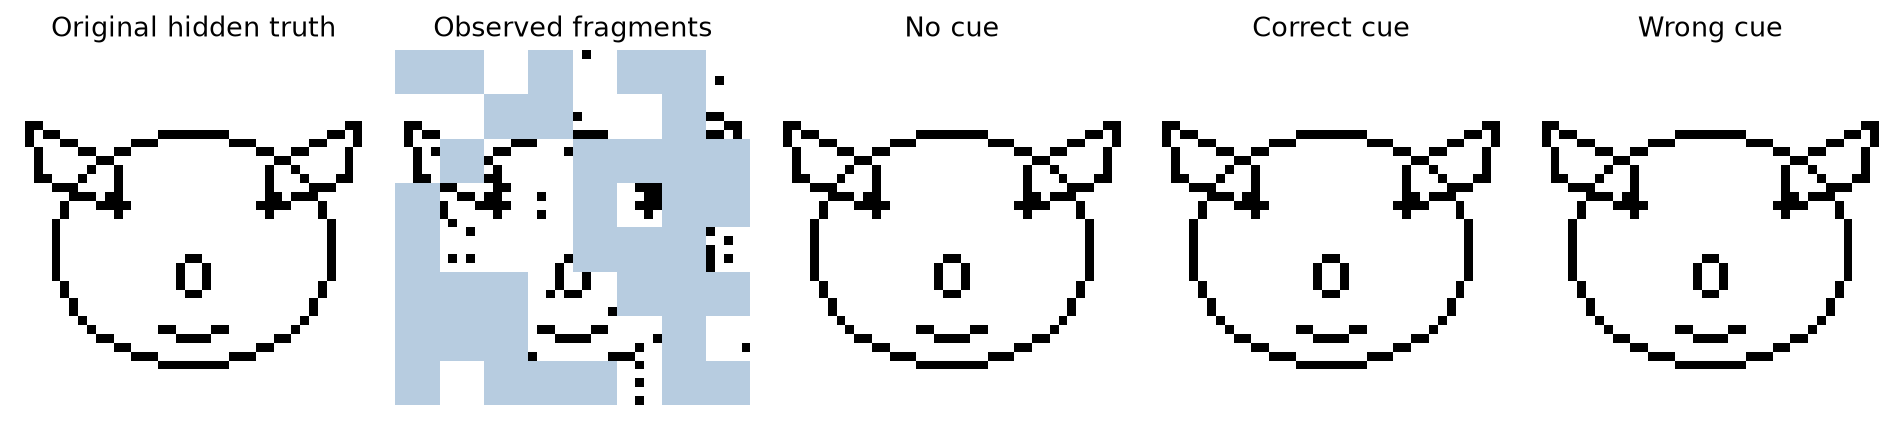

In [8]:
DEMO_CATEGORY = 0
DEMO_SEED = 37
DEMO_VISIBILITY = 0.35
CASE_STATE_ID = 468
OUT = OUT_ROOT / 'cow-like_seed37_visible35'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cow-like · seed 37 · requested visibility 65%

Recipe: {'head shape': 'wide', 'ear shape': 'long', 'eye spacing': 'wide', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'dots'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.0764          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.048
Layout prior                       0.0000          1.000         0.000          0.048
Latent categories                  0.0000          1.000         0.000          0.048
Training exemplars                 0.0000          1.000         0.000          0.048
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 1.00000000 | 1.00000000 | wide / dots | 1.763e-14
  MAP recipe: {'head shape': 'wide', 'ear shape': 'long', 'eye spacing': 'wide', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'dots'}
Correct cue  | 1.00000000 | 1.00000000 | wide

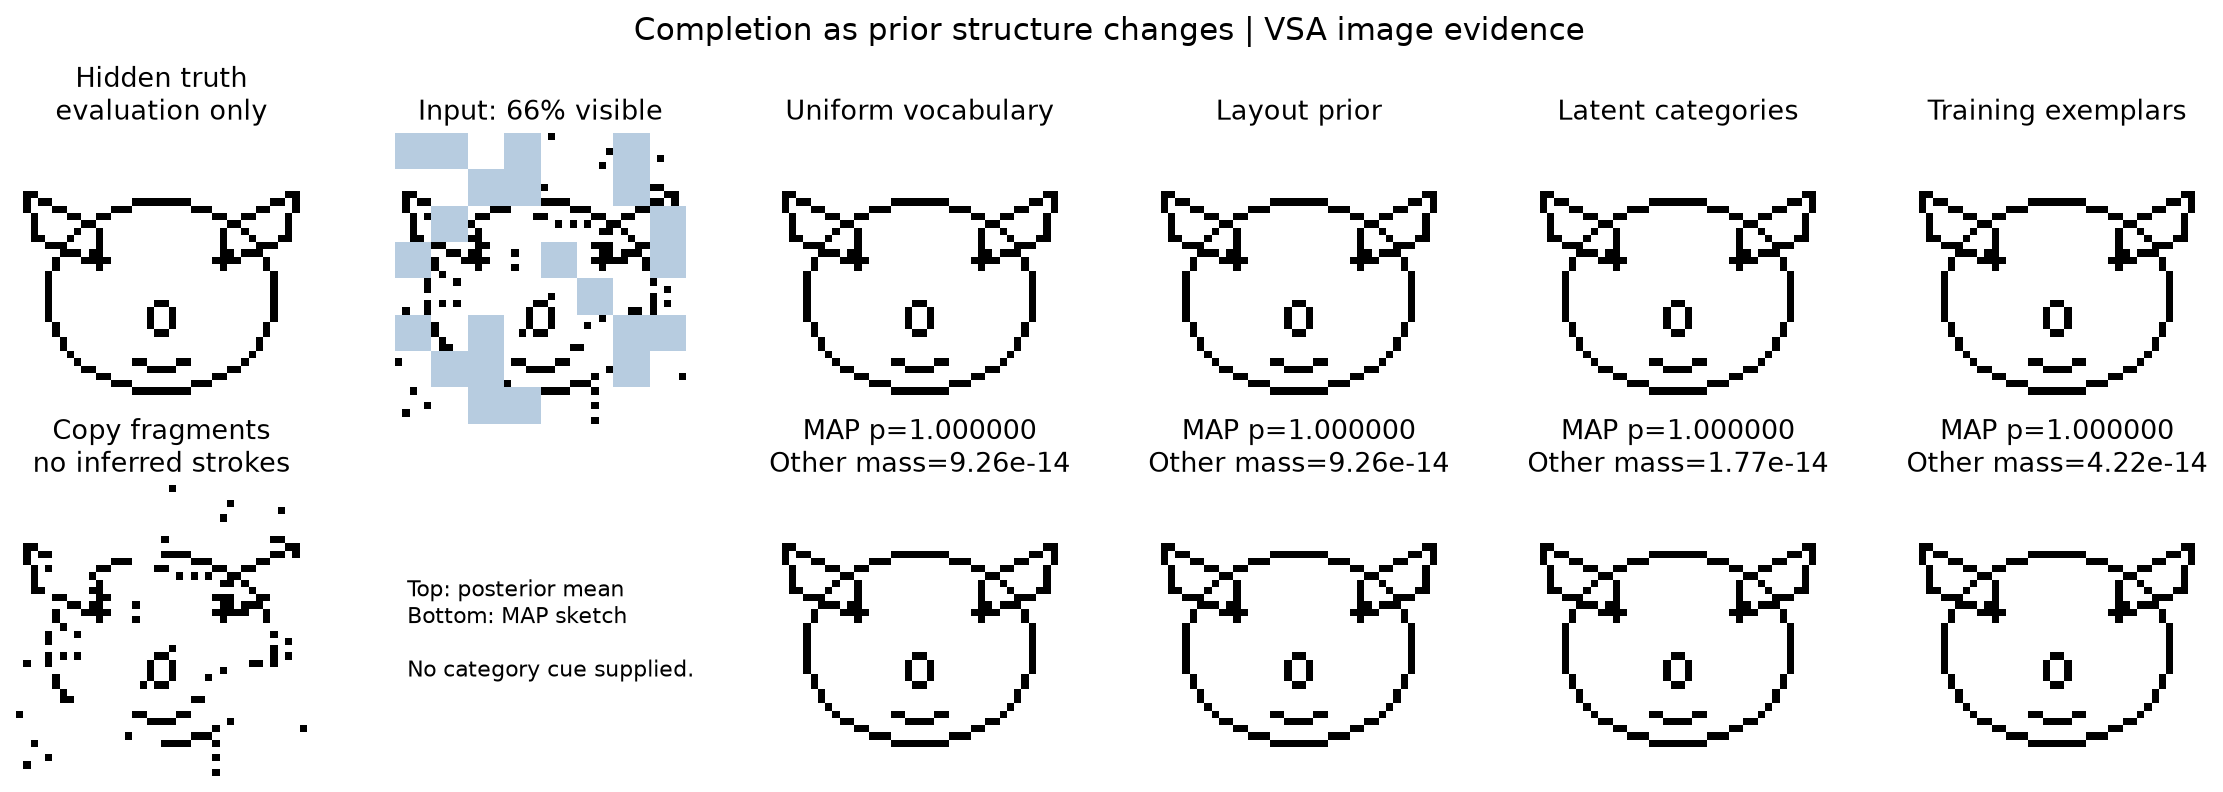

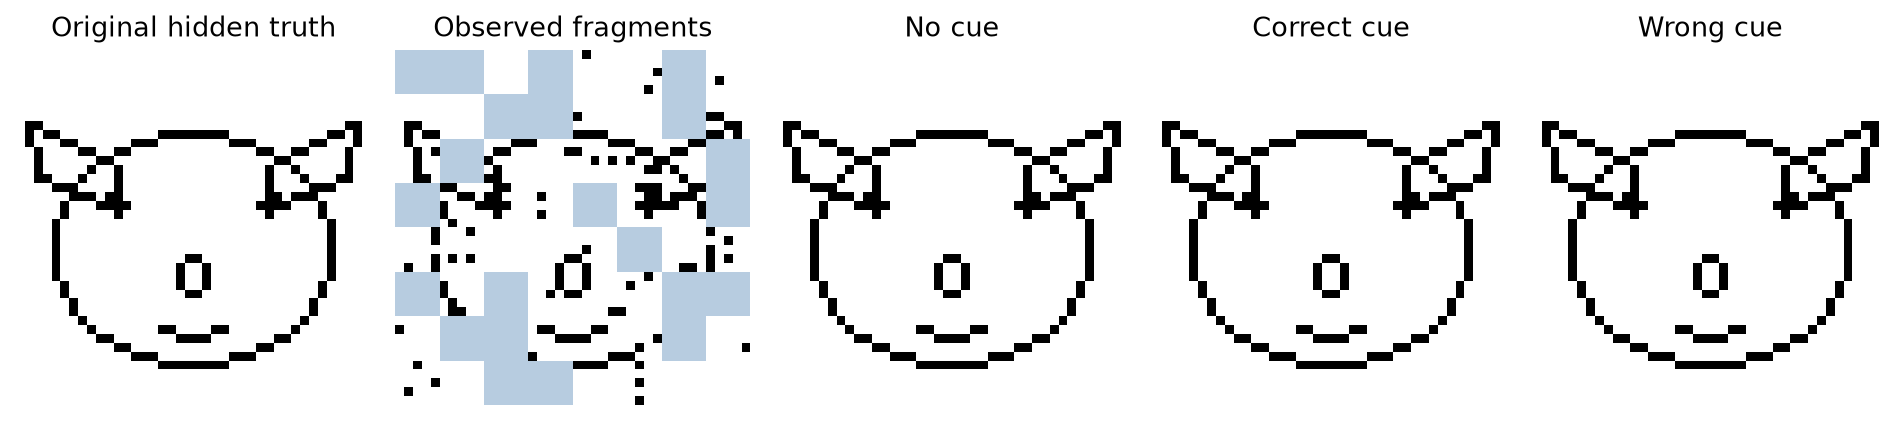

In [9]:
DEMO_CATEGORY = 0
DEMO_SEED = 37
DEMO_VISIBILITY = 0.65
CASE_STATE_ID = 468
OUT = OUT_ROOT / 'cow-like_seed37_visible65'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cow-like · seed 67 · requested visibility 15%

Recipe: {'head shape': 'wide', 'ear shape': 'pointed', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'dots'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.0919          0.000         0.000          0.000
Uniform vocabulary                 0.0063          0.968         0.000          0.036
Layout prior                       0.0063          0.968         0.000          0.036
Latent categories                  0.0105          0.968         0.000          0.036
Training exemplars                 0.0075          0.968         0.000          0.036
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.31267647 | 0.48571137 | narrow / dots | 5.143e-01
  MAP recipe: {'head shape': 'wide', 'ear shape': 'pointed', 'eye spacing': 'narrow', 'nose shape': 'muzzle', 'layout': 'aligned', 'eye shape': 'dots'}
Correct cue  | 0.00840905 | 0.98

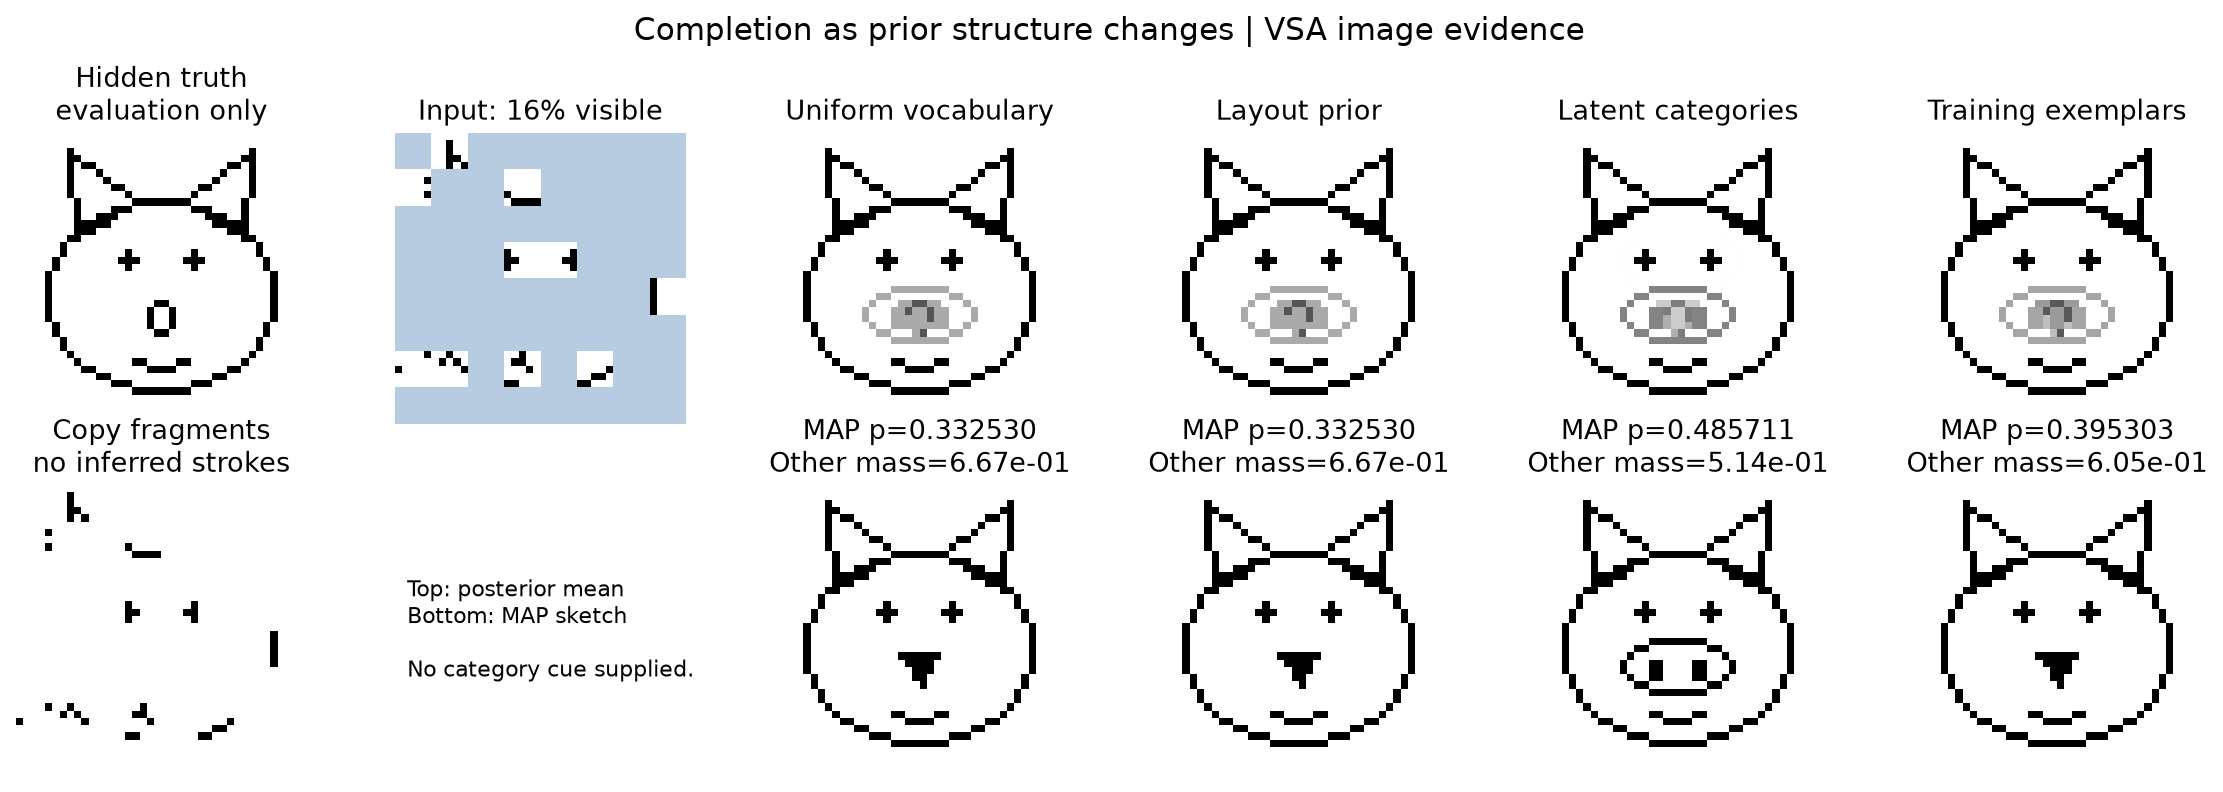

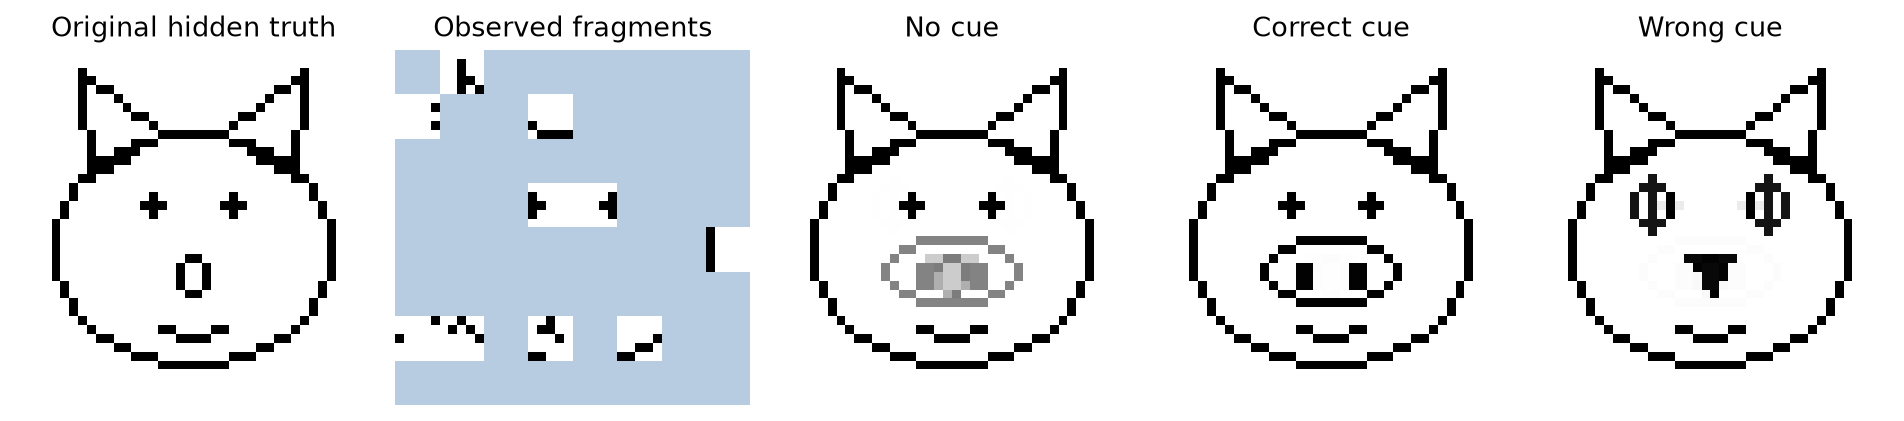

In [10]:
DEMO_CATEGORY = 0
DEMO_SEED = 67
DEMO_VISIBILITY = 0.15
CASE_STATE_ID = 333
OUT = OUT_ROOT / 'cow-like_seed67_visible15'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cow-like · seed 67 · requested visibility 35%

Recipe: {'head shape': 'wide', 'ear shape': 'pointed', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'dots'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.0776          0.000         0.000          0.000
Uniform vocabulary                 0.0042          0.938         0.000          0.041
Layout prior                       0.0042          0.938         0.000          0.041
Latent categories                  0.0025          1.000         0.000          0.041
Training exemplars                 0.0064          0.938         0.013          0.041
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.61374739 | 0.61374739 | narrow / dots | 3.863e-01
  MAP recipe: {'head shape': 'wide', 'ear shape': 'pointed', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'dots'}
Correct cue  | 0.53535259 | 0.535

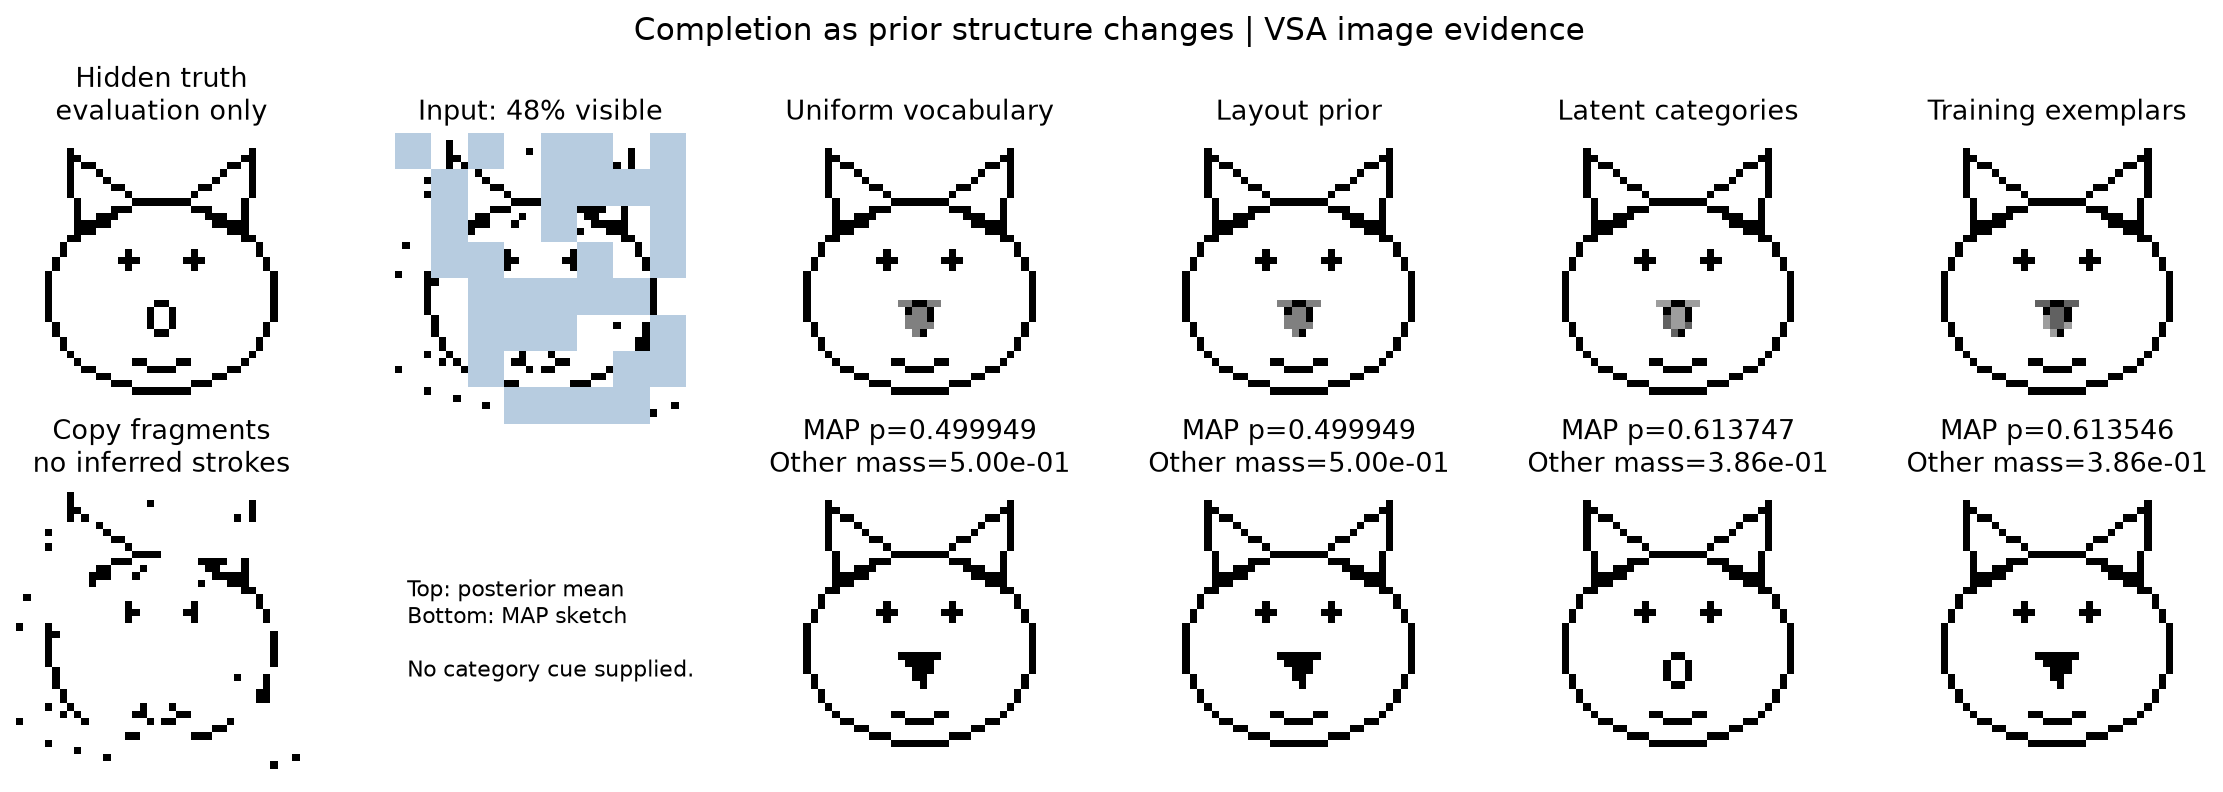

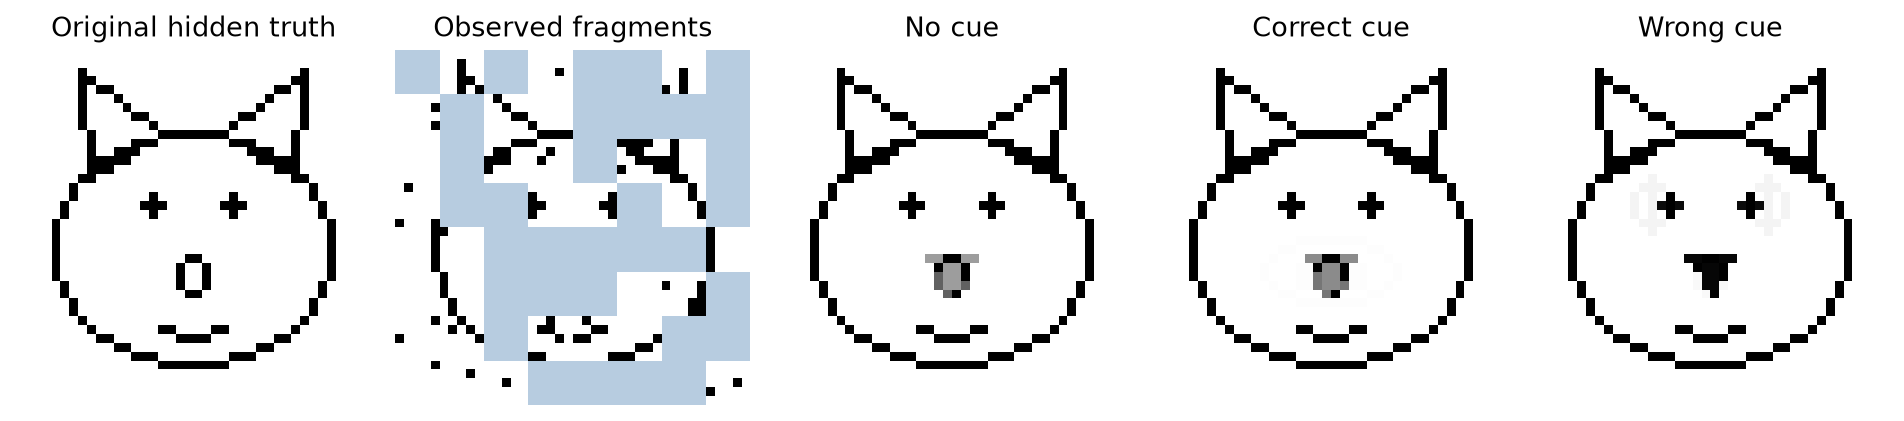

In [11]:
DEMO_CATEGORY = 0
DEMO_SEED = 67
DEMO_VISIBILITY = 0.35
CASE_STATE_ID = 333
OUT = OUT_ROOT / 'cow-like_seed67_visible35'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cow-like · seed 67 · requested visibility 65%

Recipe: {'head shape': 'wide', 'ear shape': 'pointed', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'dots'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.0753          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.041
Layout prior                       0.0000          1.000         0.000          0.041
Latent categories                  0.0000          1.000         0.000          0.041
Training exemplars                 0.0000          1.000         0.000          0.041
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 1.00000000 | 1.00000000 | narrow / dots | 1.892e-09
  MAP recipe: {'head shape': 'wide', 'ear shape': 'pointed', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'dots'}
Correct cue  | 1.00000000 | 1.000

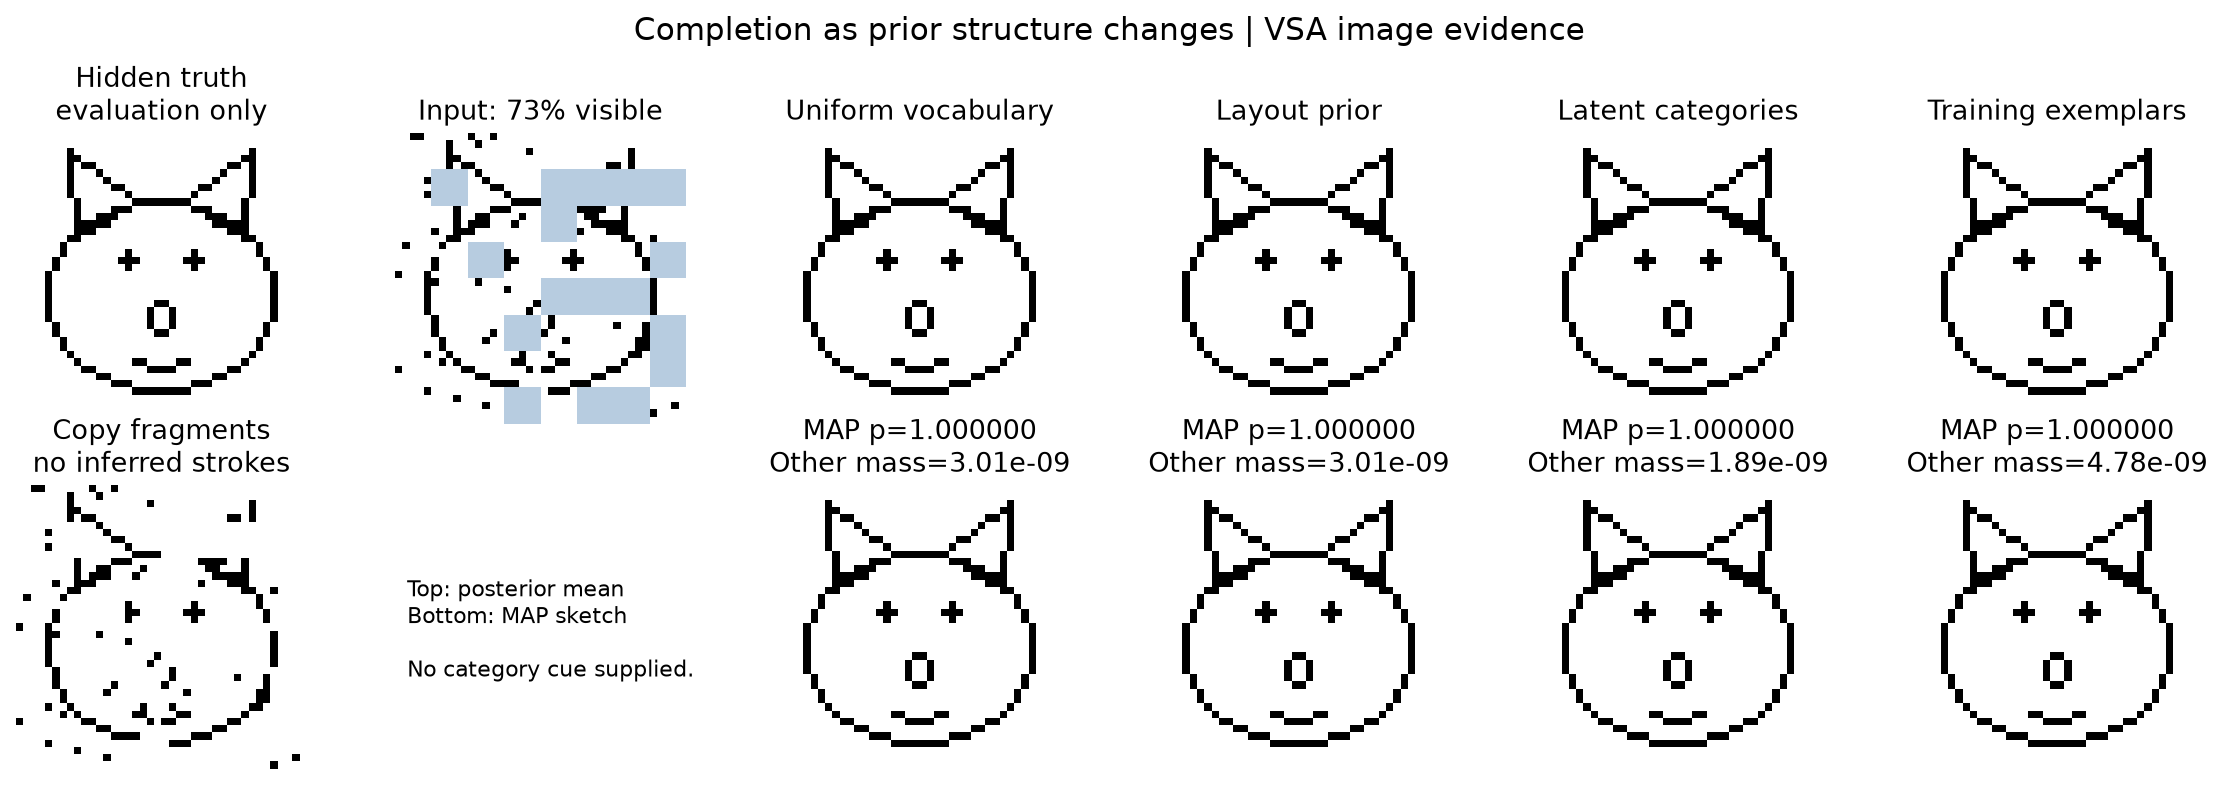

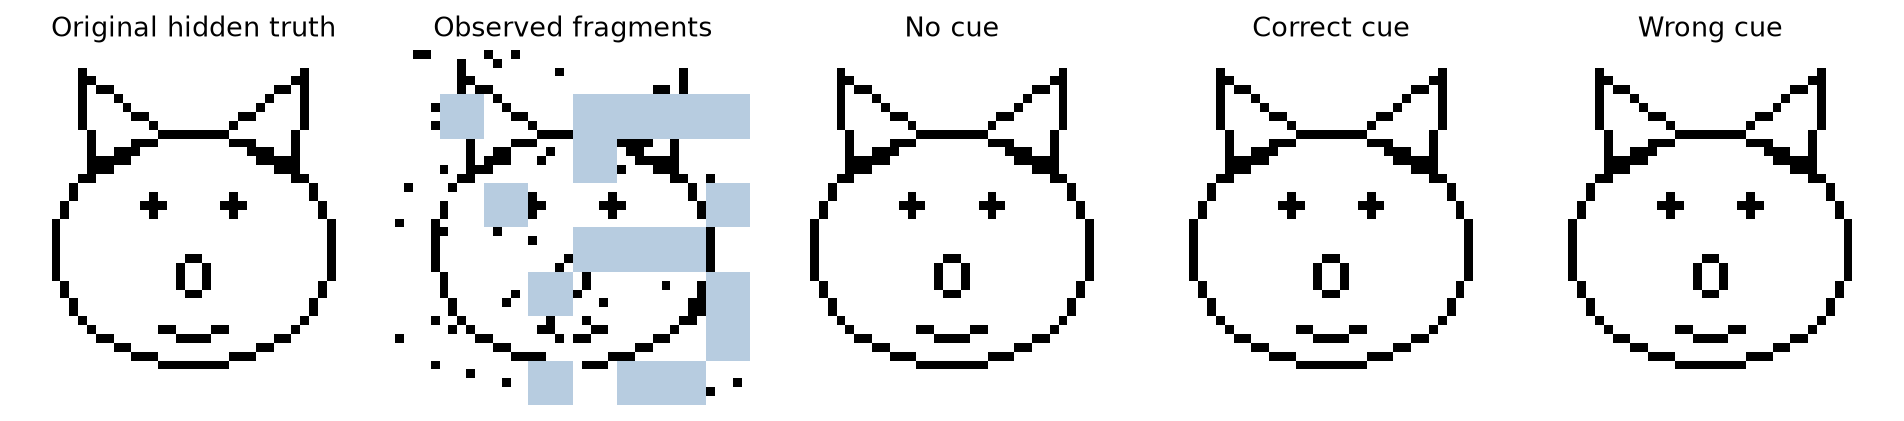

In [12]:
DEMO_CATEGORY = 0
DEMO_SEED = 67
DEMO_VISIBILITY = 0.65
CASE_STATE_ID = 333
OUT = OUT_ROOT / 'cow-like_seed67_visible65'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cat-like · seed 17 · requested visibility 15%

Recipe: {'head shape': 'wide', 'ear shape': 'long', 'eye spacing': 'narrow', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'oval pupils'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.1236          0.000         0.000          0.000
Uniform vocabulary                 0.0158          0.800         0.000          0.049
Layout prior                       0.0158          0.800         0.000          0.049
Latent categories                  0.0233          0.776         0.007          0.049
Training exemplars                 0.0225          0.776         0.005          0.049
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.05154446 | 0.49208992 | wide / dots | 5.079e-01
  MAP recipe: {'head shape': 'wide', 'ear shape': 'long', 'eye spacing': 'wide', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'dots'}
Correct cue  | 0.15852759 | 0.

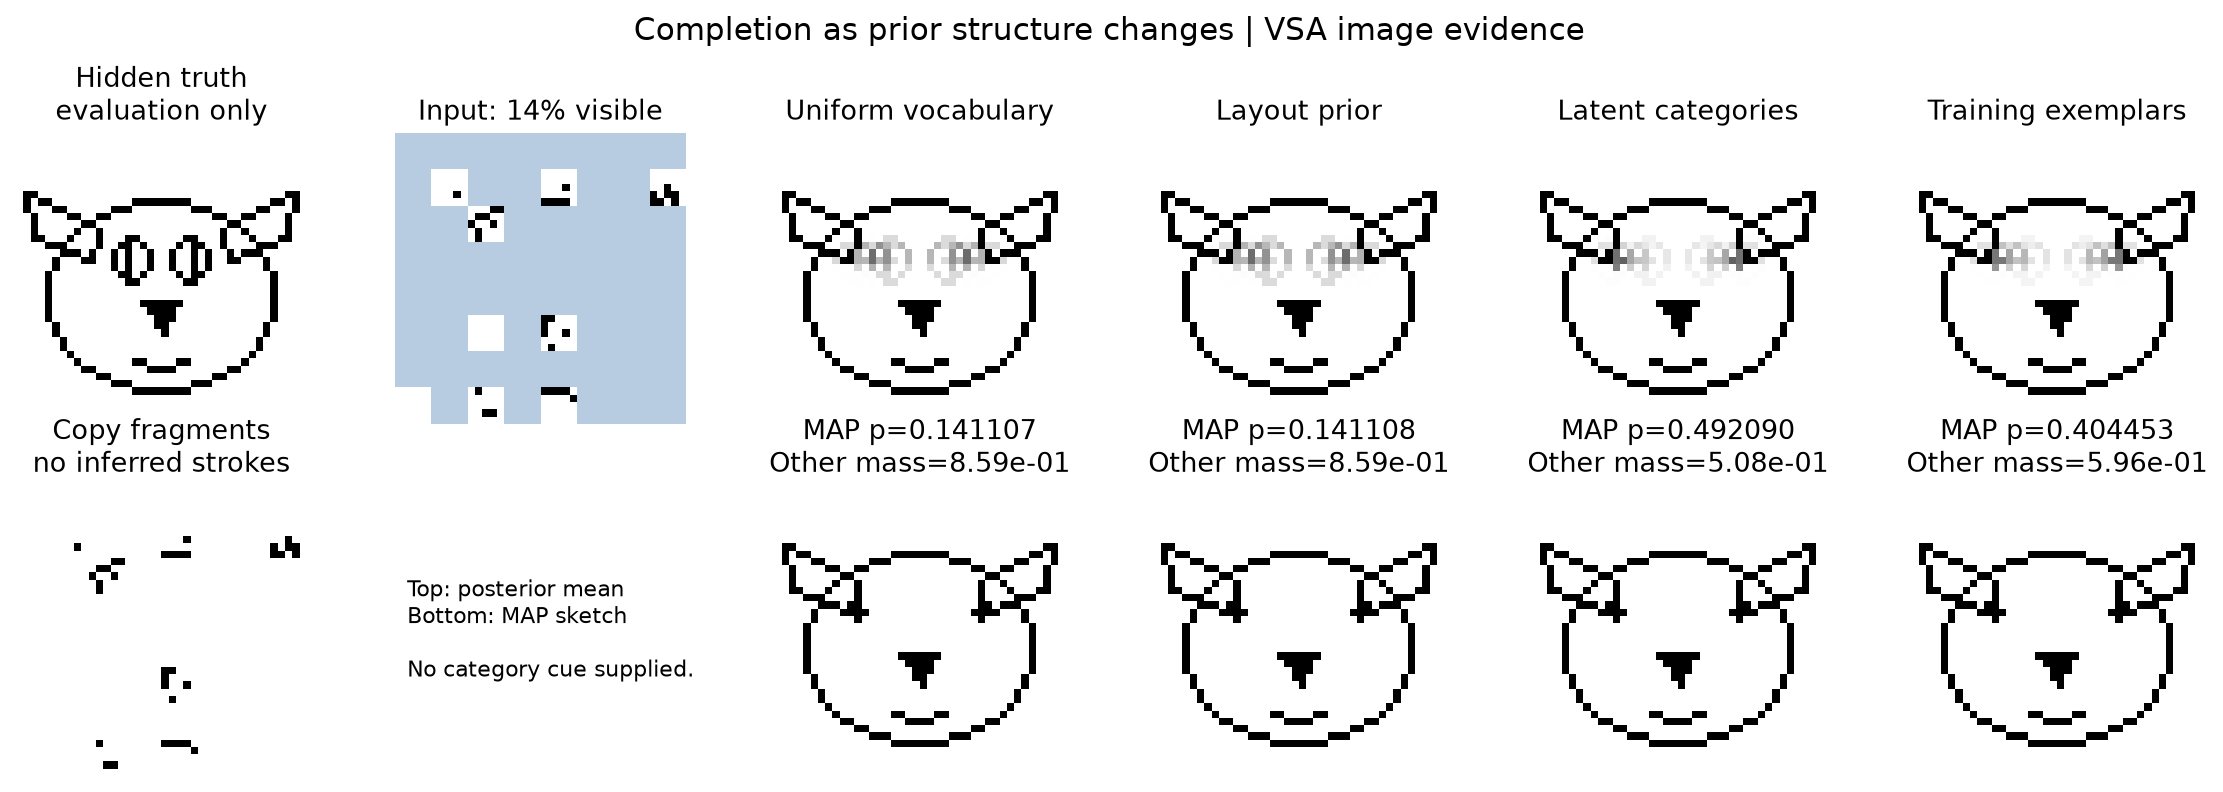

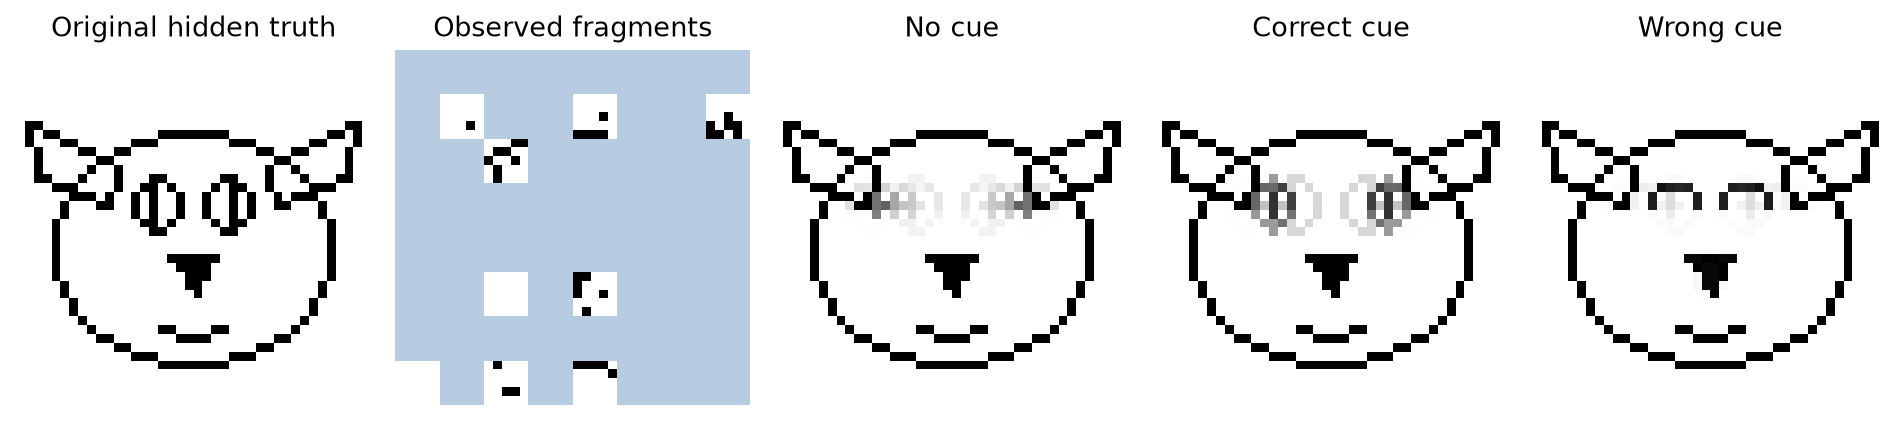

In [13]:
DEMO_CATEGORY = 1
DEMO_SEED = 17
DEMO_VISIBILITY = 0.15
CASE_STATE_ID = 407
OUT = OUT_ROOT / 'cat-like_seed17_visible15'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cat-like · seed 17 · requested visibility 35%

Recipe: {'head shape': 'wide', 'ear shape': 'long', 'eye spacing': 'narrow', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'oval pupils'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.1354          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.037
Layout prior                       0.0000          1.000         0.000          0.037
Latent categories                  0.0000          1.000         0.000          0.037
Training exemplars                 0.0000          1.000         0.000          0.037
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.99962013 | 0.99962013 | narrow / oval pupils | 3.799e-04
  MAP recipe: {'head shape': 'wide', 'ear shape': 'long', 'eye spacing': 'narrow', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'oval pupils'}
Correct cue 

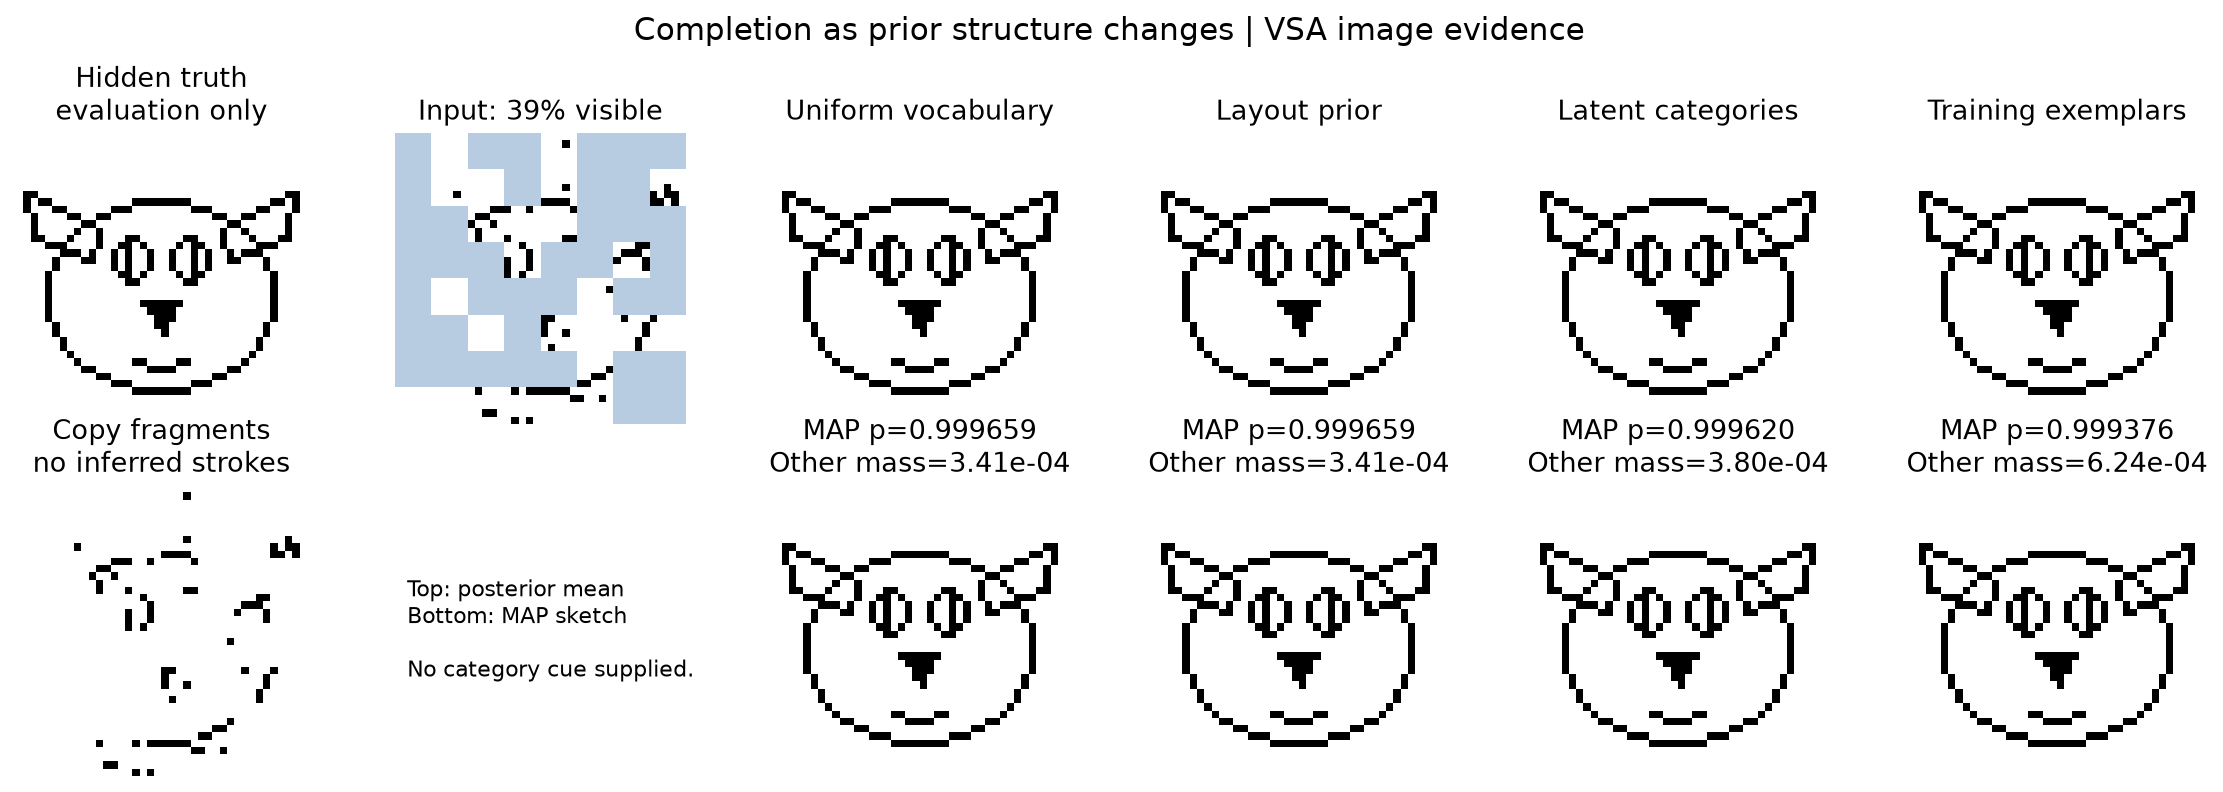

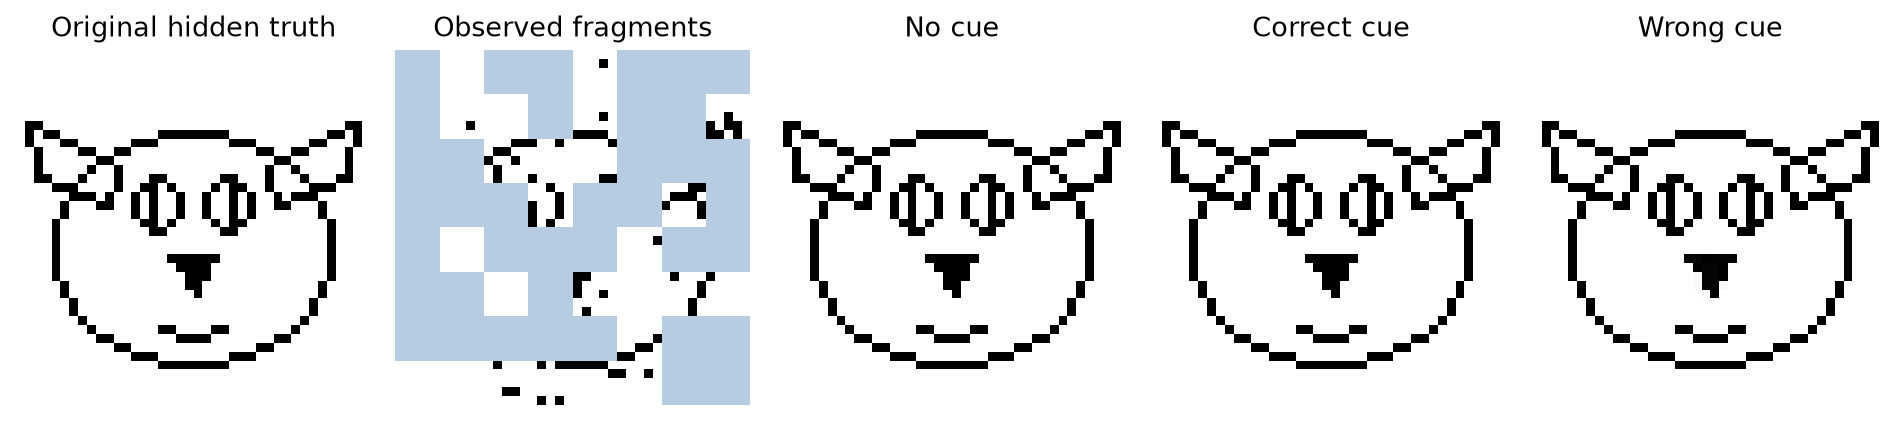

In [14]:
DEMO_CATEGORY = 1
DEMO_SEED = 17
DEMO_VISIBILITY = 0.35
CASE_STATE_ID = 407
OUT = OUT_ROOT / 'cat-like_seed17_visible35'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cat-like · seed 17 · requested visibility 65%

Recipe: {'head shape': 'wide', 'ear shape': 'long', 'eye spacing': 'narrow', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'oval pupils'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.1286          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.043
Layout prior                       0.0000          1.000         0.000          0.043
Latent categories                  0.0000          1.000         0.000          0.043
Training exemplars                 0.0000          1.000         0.000          0.043
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.99999448 | 0.99999448 | narrow / oval pupils | 5.515e-06
  MAP recipe: {'head shape': 'wide', 'ear shape': 'long', 'eye spacing': 'narrow', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'oval pupils'}
Correct cue 

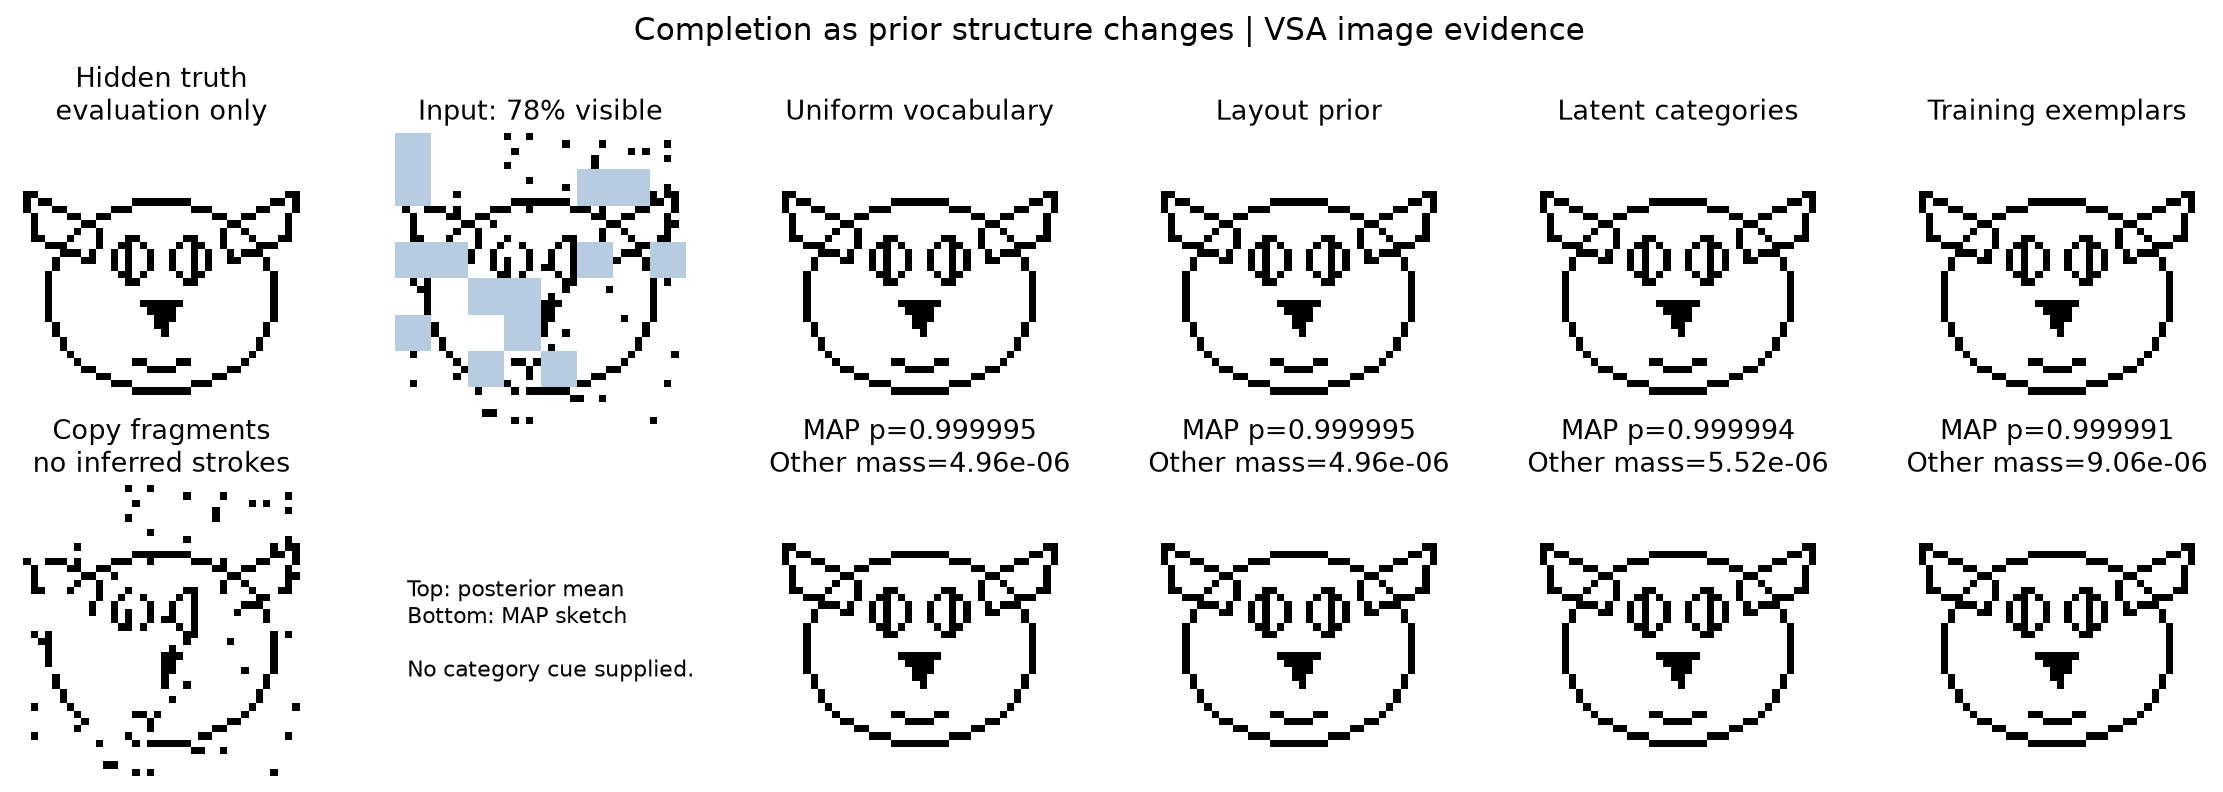

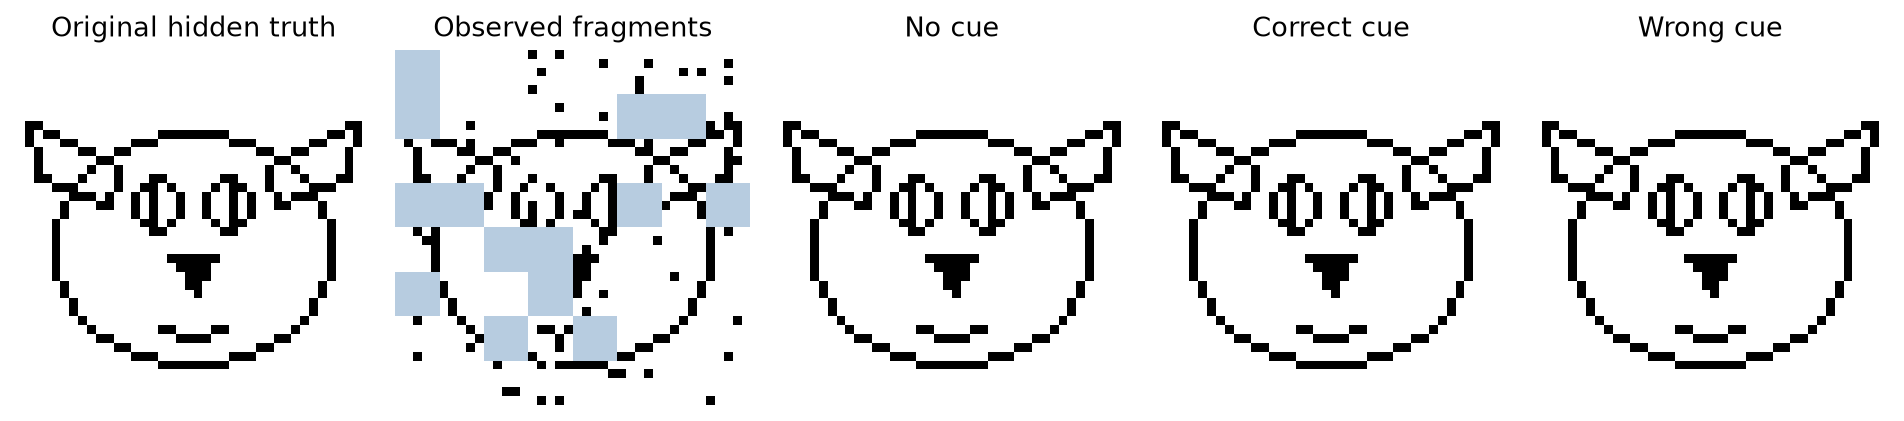

In [15]:
DEMO_CATEGORY = 1
DEMO_SEED = 17
DEMO_VISIBILITY = 0.65
CASE_STATE_ID = 407
OUT = OUT_ROOT / 'cat-like_seed17_visible65'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cat-like · seed 37 · requested visibility 15%

Recipe: {'head shape': 'round', 'ear shape': 'pointed', 'eye spacing': 'medium', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'oval pupils'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.1008          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.049
Layout prior                       0.0000          1.000         0.000          0.049
Latent categories                  0.0000          1.000         0.000          0.049
Training exemplars                 0.0000          1.000         0.000          0.049
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.99880727 | 0.99880727 | medium / oval pupils | 1.193e-03
  MAP recipe: {'head shape': 'round', 'ear shape': 'pointed', 'eye spacing': 'medium', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'oval pupils'}
Corr

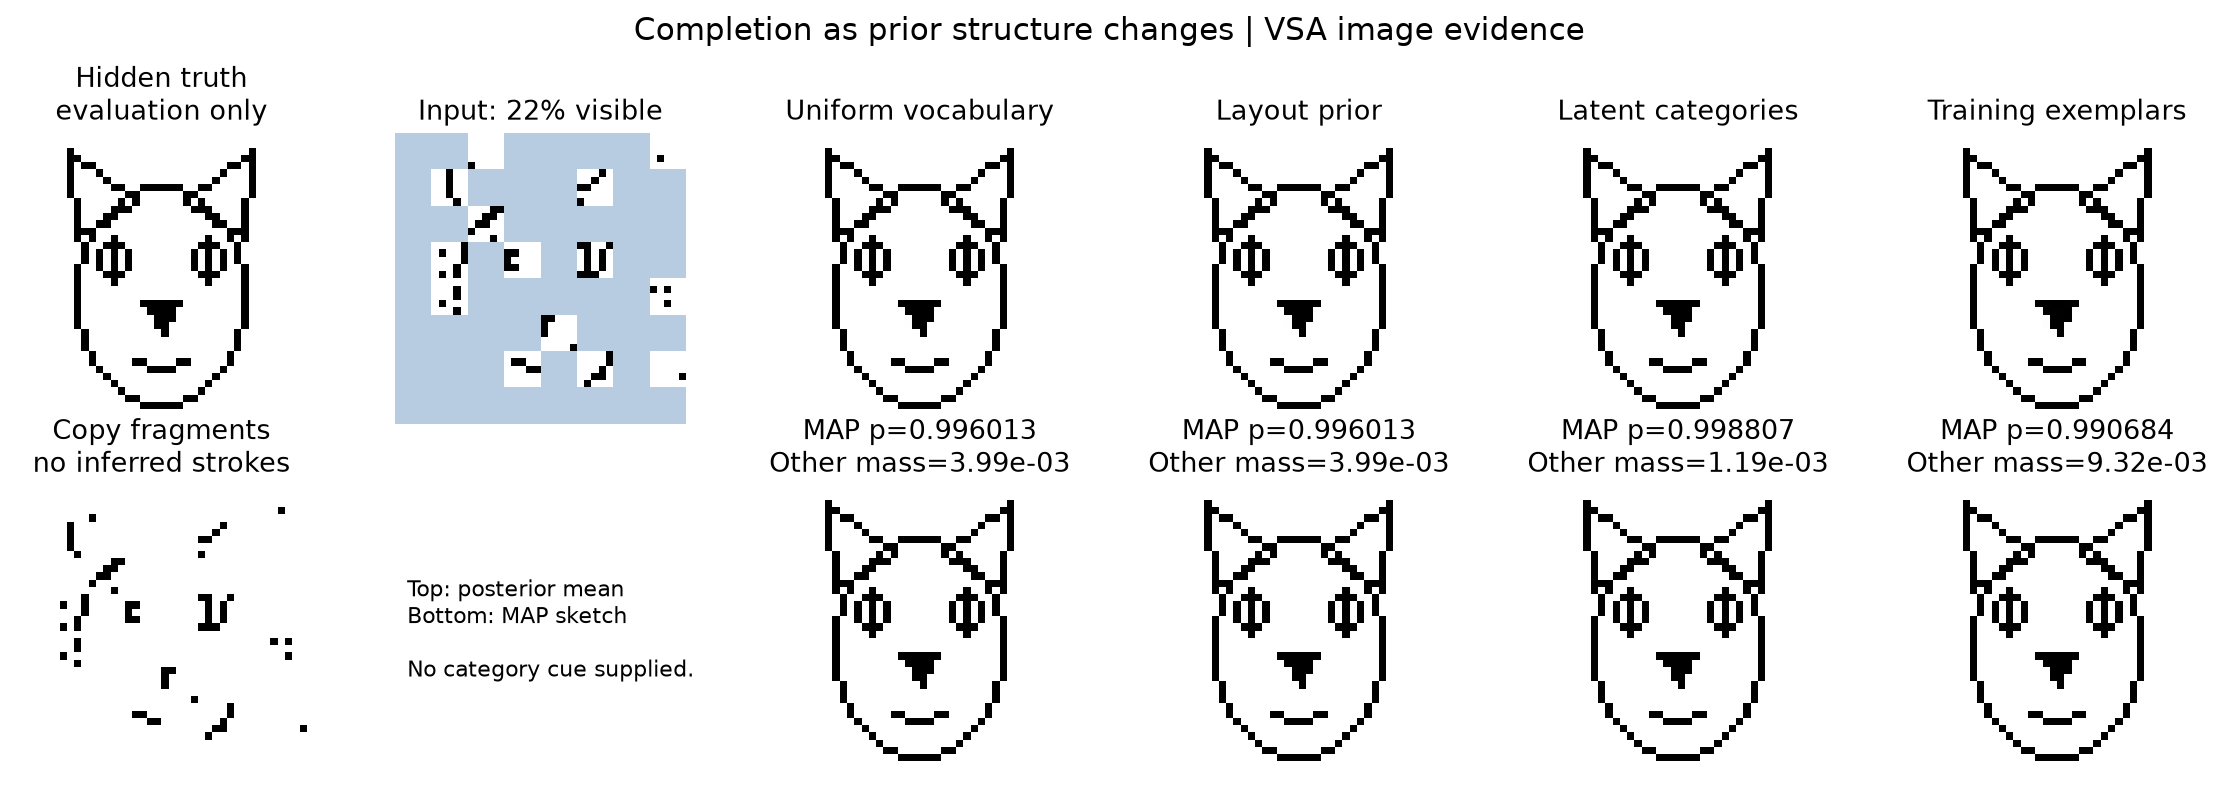

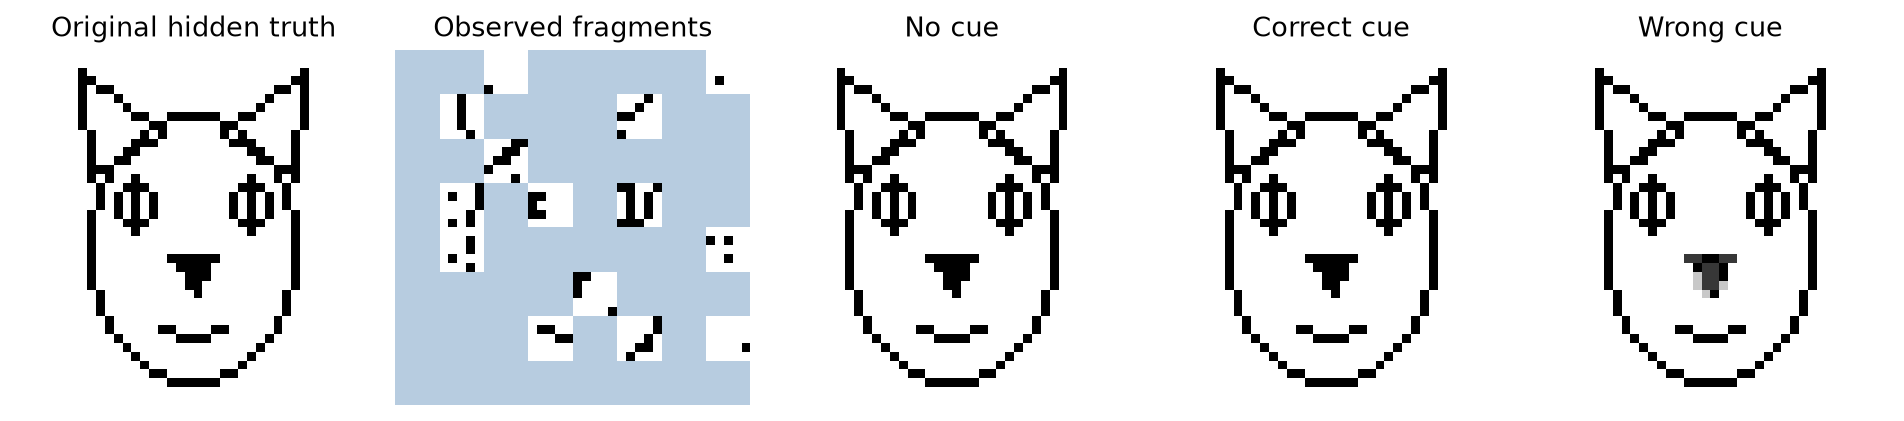

In [16]:
DEMO_CATEGORY = 1
DEMO_SEED = 37
DEMO_VISIBILITY = 0.15
CASE_STATE_ID = 110
OUT = OUT_ROOT / 'cat-like_seed37_visible15'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cat-like · seed 37 · requested visibility 35%

Recipe: {'head shape': 'round', 'ear shape': 'pointed', 'eye spacing': 'medium', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'oval pupils'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.1016          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.041
Layout prior                       0.0000          1.000         0.000          0.041
Latent categories                  0.0000          1.000         0.000          0.041
Training exemplars                 0.0000          1.000         0.000          0.041
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 1.00000000 | 1.00000000 | medium / oval pupils | 1.106e-10
  MAP recipe: {'head shape': 'round', 'ear shape': 'pointed', 'eye spacing': 'medium', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'oval pupils'}
Corr

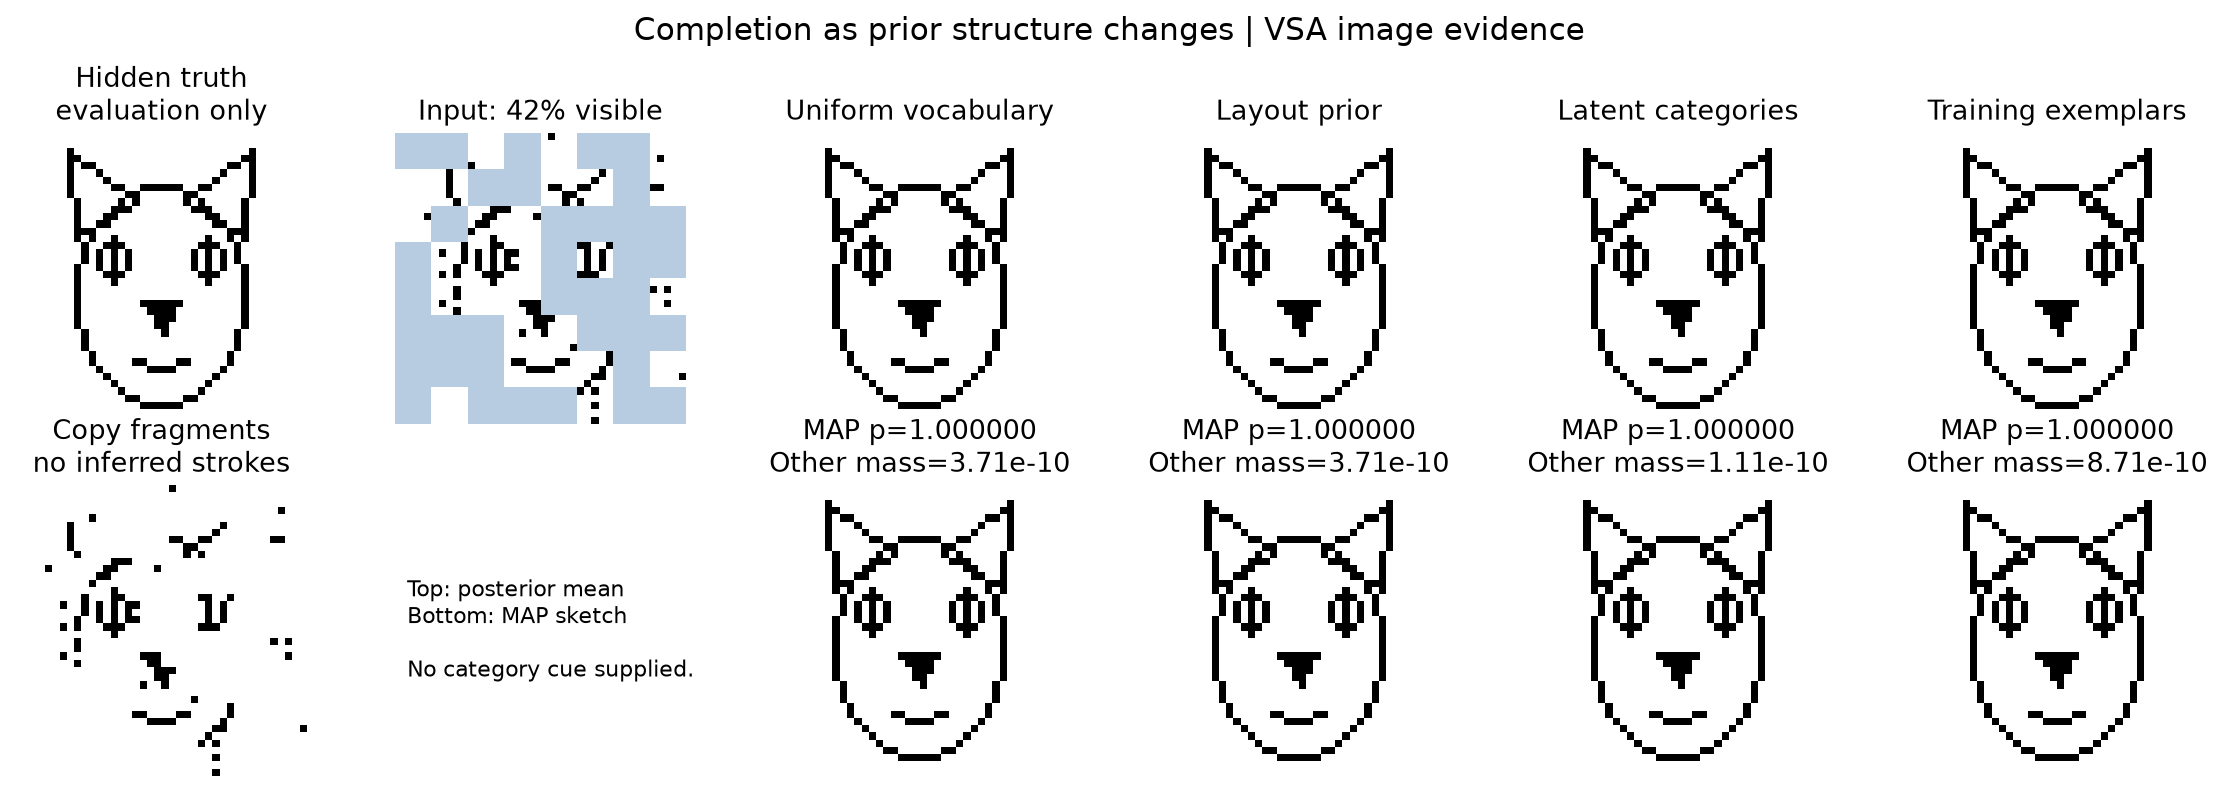

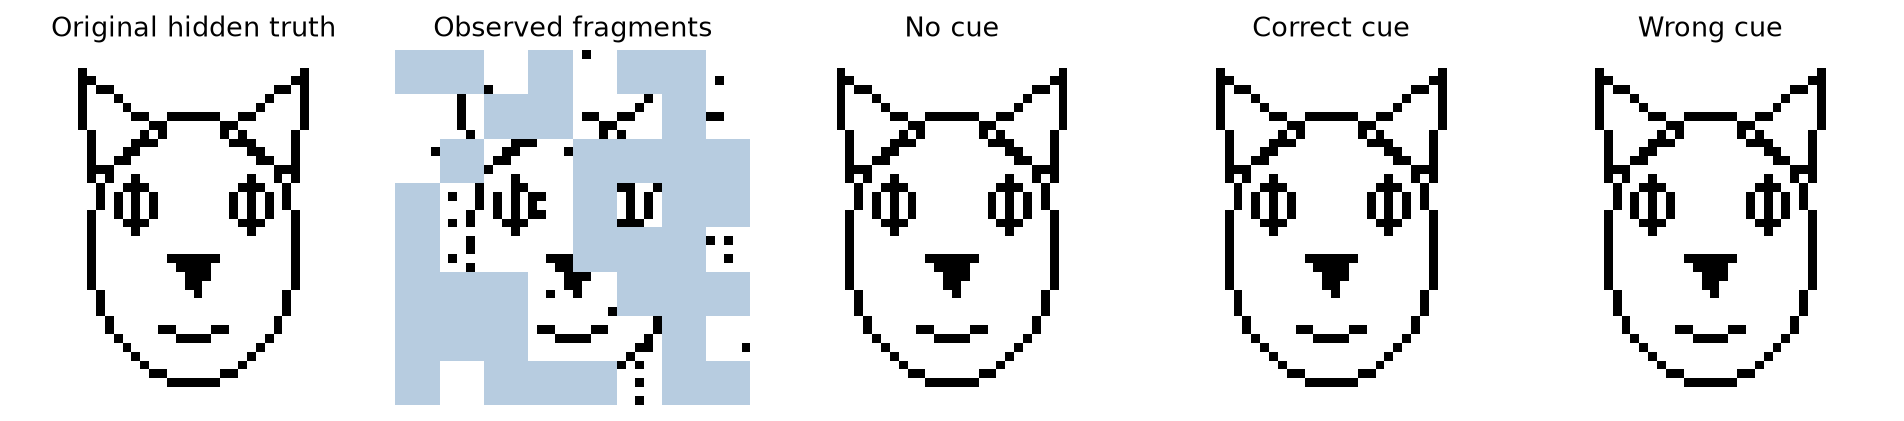

In [17]:
DEMO_CATEGORY = 1
DEMO_SEED = 37
DEMO_VISIBILITY = 0.35
CASE_STATE_ID = 110
OUT = OUT_ROOT / 'cat-like_seed37_visible35'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cat-like · seed 37 · requested visibility 65%

Recipe: {'head shape': 'round', 'ear shape': 'pointed', 'eye spacing': 'medium', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'oval pupils'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.0945          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.048
Layout prior                       0.0000          1.000         0.000          0.048
Latent categories                  0.0000          1.000         0.000          0.048
Training exemplars                 0.0000          1.000         0.000          0.048
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 1.00000000 | 1.00000000 | medium / oval pupils | 5.574e-13
  MAP recipe: {'head shape': 'round', 'ear shape': 'pointed', 'eye spacing': 'medium', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'oval pupils'}
Corr

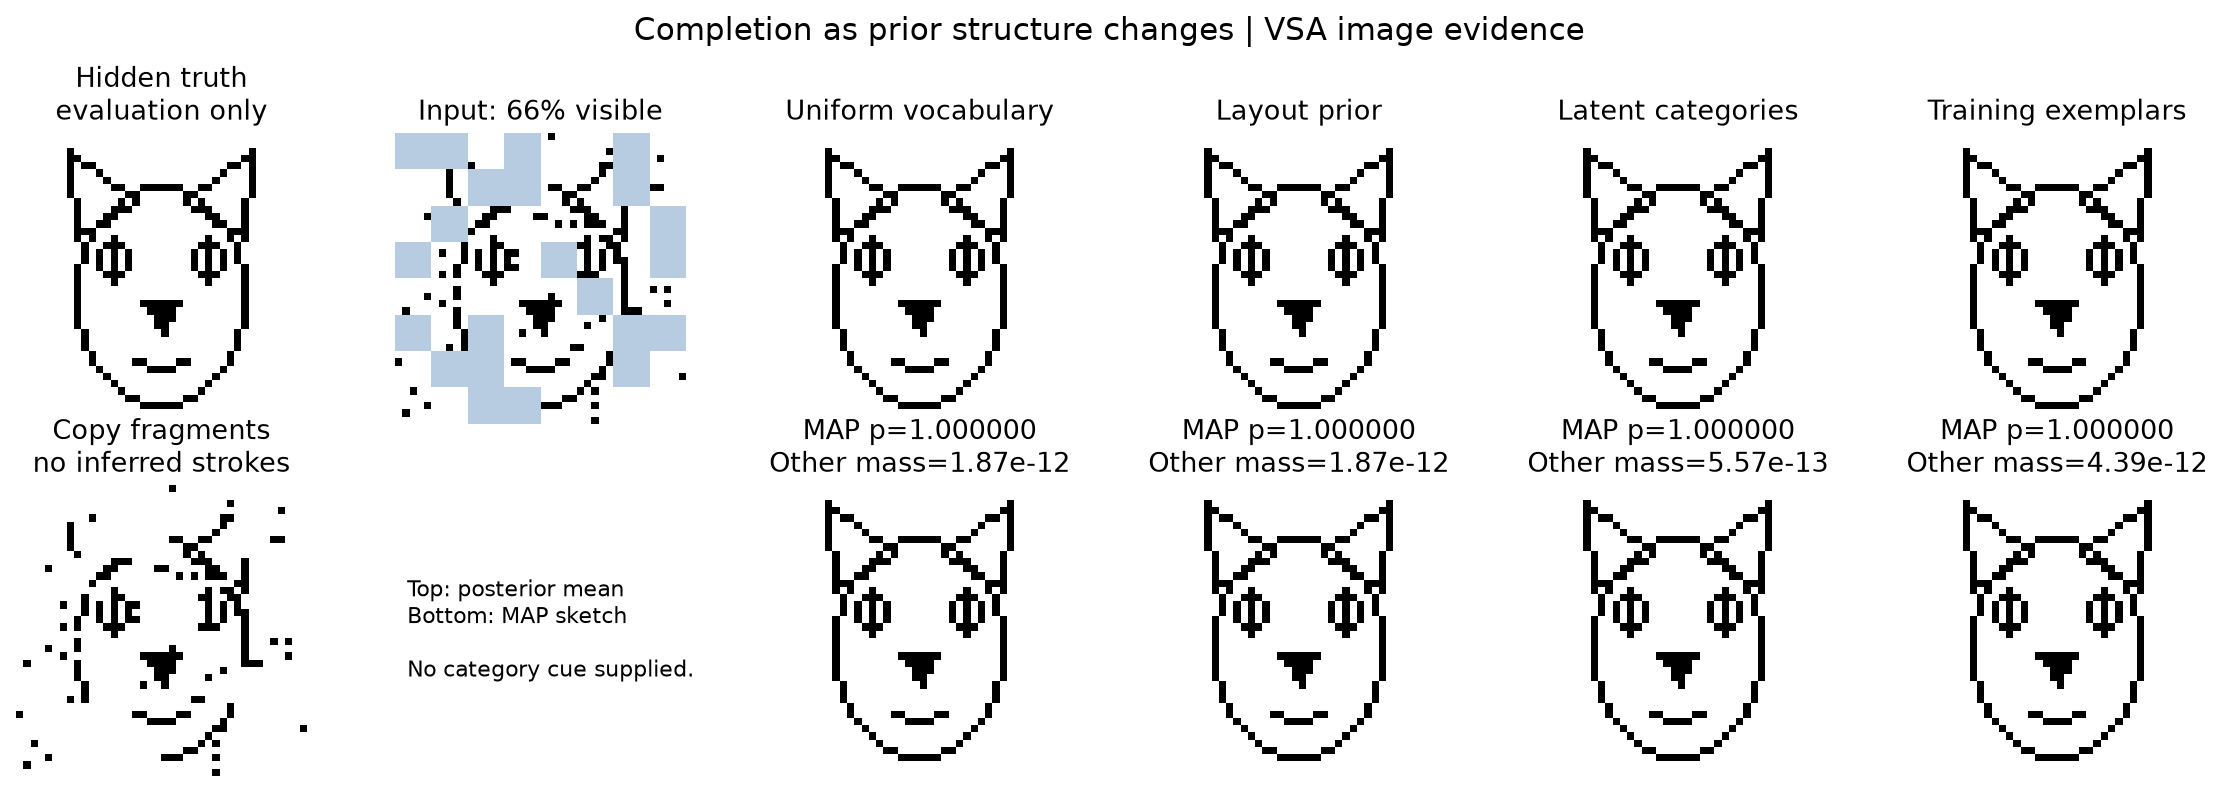

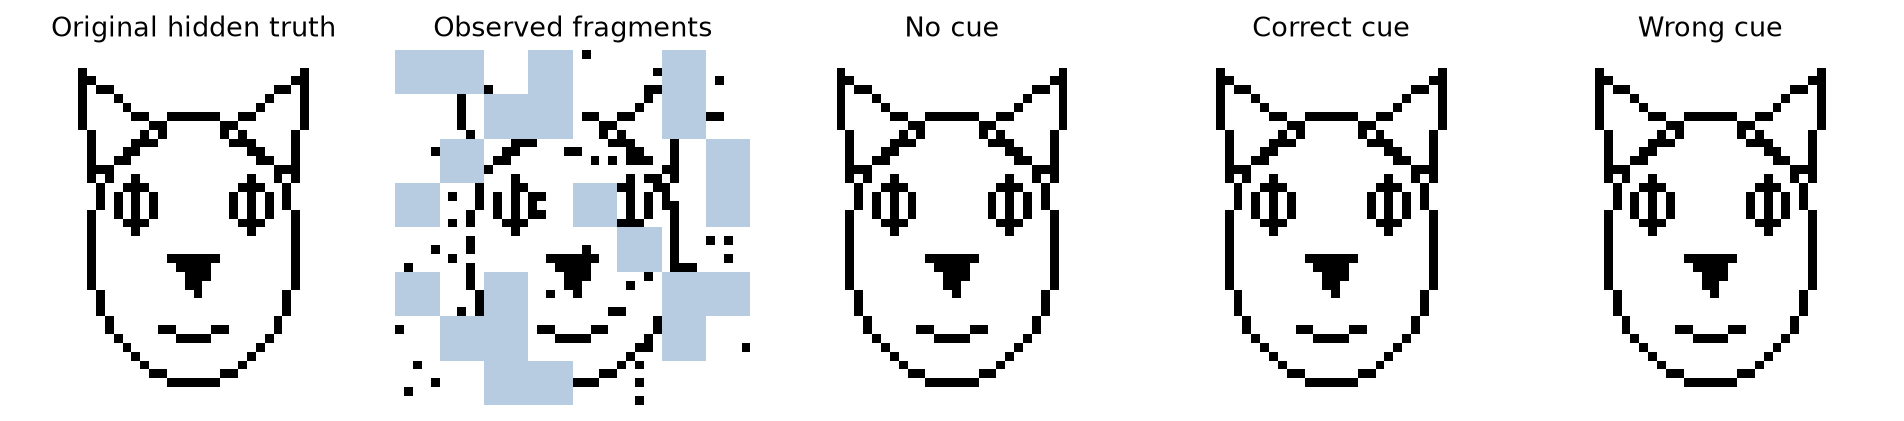

In [18]:
DEMO_CATEGORY = 1
DEMO_SEED = 37
DEMO_VISIBILITY = 0.65
CASE_STATE_ID = 110
OUT = OUT_ROOT / 'cat-like_seed37_visible65'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cat-like · seed 67 · requested visibility 15%

Recipe: {'head shape': 'tall', 'ear shape': 'pointed', 'eye spacing': 'medium', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'dots'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.1030          0.000         0.000          0.000
Uniform vocabulary                 0.0117          0.885         0.000          0.036
Layout prior                       0.0117          0.885         0.000          0.036
Latent categories                  0.0096          0.914         0.000          0.036
Training exemplars                 0.0108          0.899         0.007          0.036
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.13865251 | 0.13865251 | medium / dots | 8.613e-01
  MAP recipe: {'head shape': 'tall', 'ear shape': 'pointed', 'eye spacing': 'medium', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'dots'}
Correct cue  | 0.60599730 |

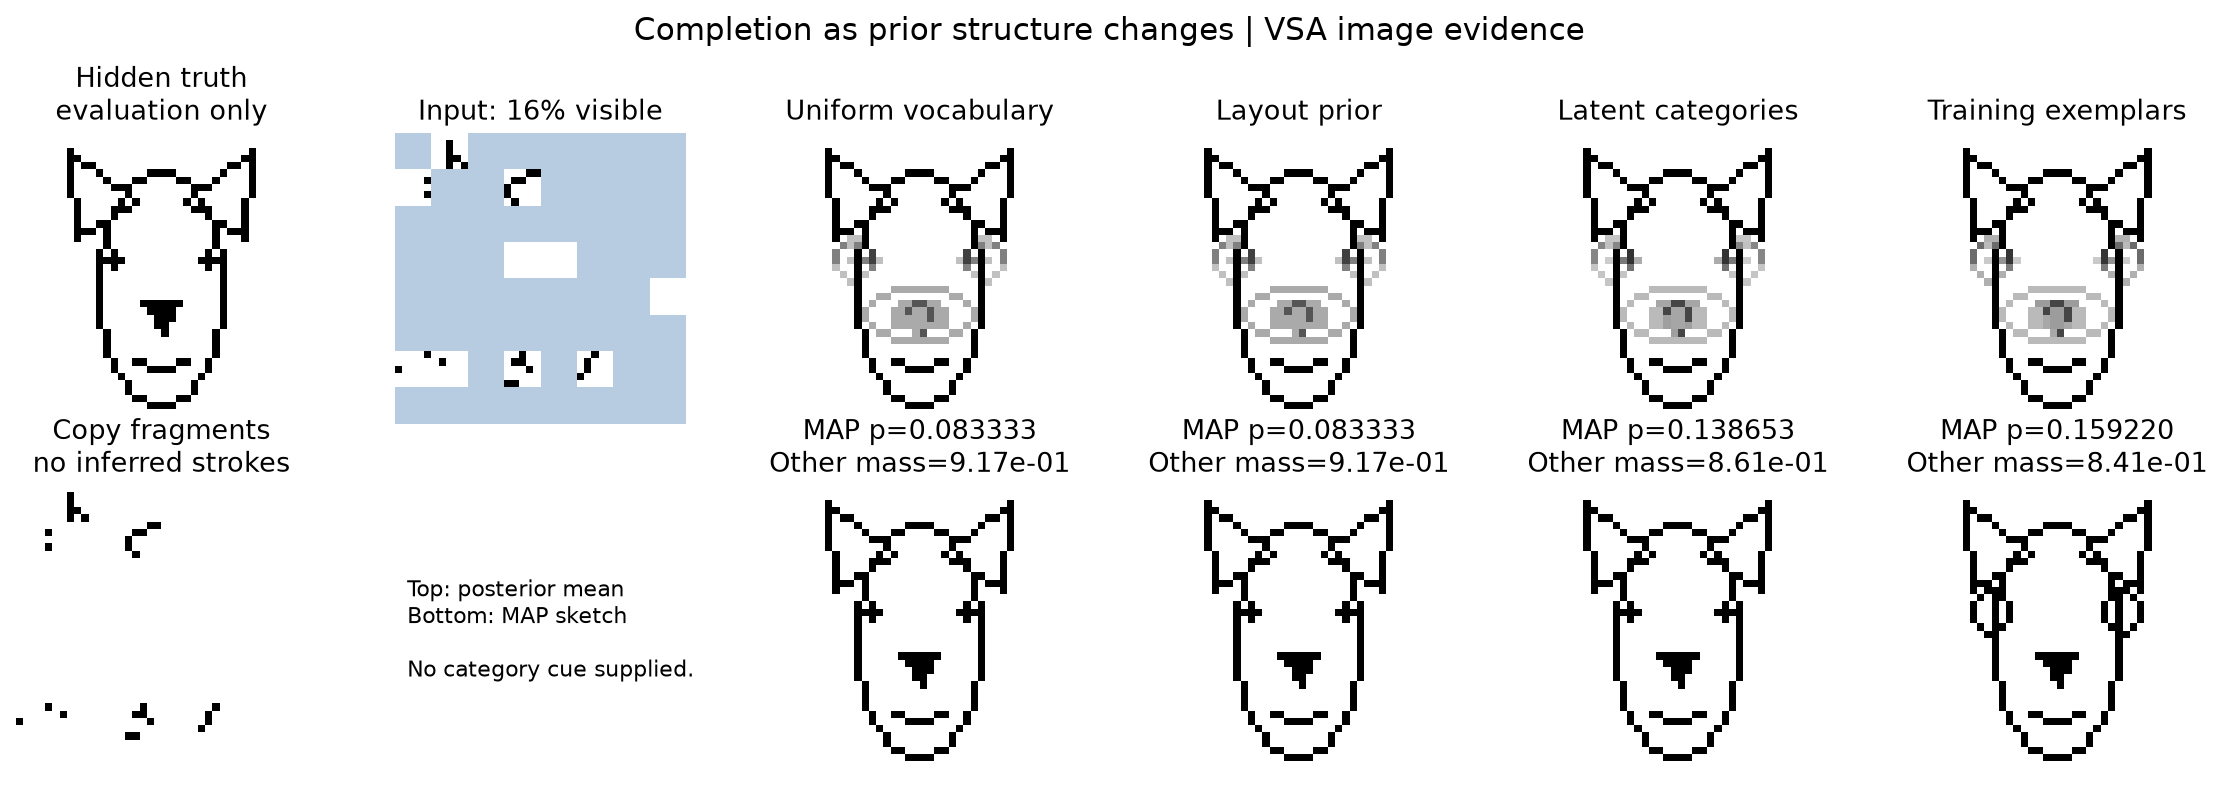

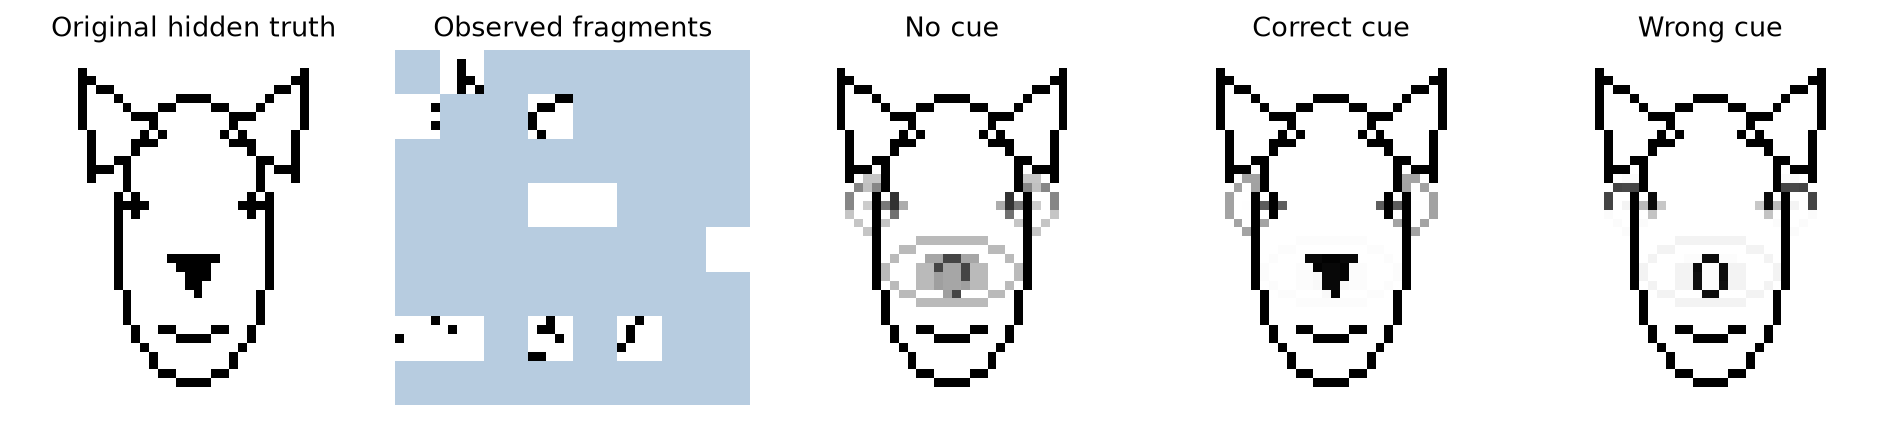

In [19]:
DEMO_CATEGORY = 1
DEMO_SEED = 67
DEMO_VISIBILITY = 0.15
CASE_STATE_ID = 594
OUT = OUT_ROOT / 'cat-like_seed67_visible15'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cat-like · seed 67 · requested visibility 35%

Recipe: {'head shape': 'tall', 'ear shape': 'pointed', 'eye spacing': 'medium', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'dots'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.1164          0.000         0.000          0.000
Uniform vocabulary                 0.0073          0.854         0.000          0.041
Layout prior                       0.0073          0.854         0.000          0.041
Latent categories                  0.0053          1.000         0.000          0.041
Training exemplars                 0.0063          1.000         0.000          0.041
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.37376822 | 0.37376822 | medium / dots | 6.262e-01
  MAP recipe: {'head shape': 'tall', 'ear shape': 'pointed', 'eye spacing': 'medium', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'dots'}
Correct cue  | 0.96605353 |

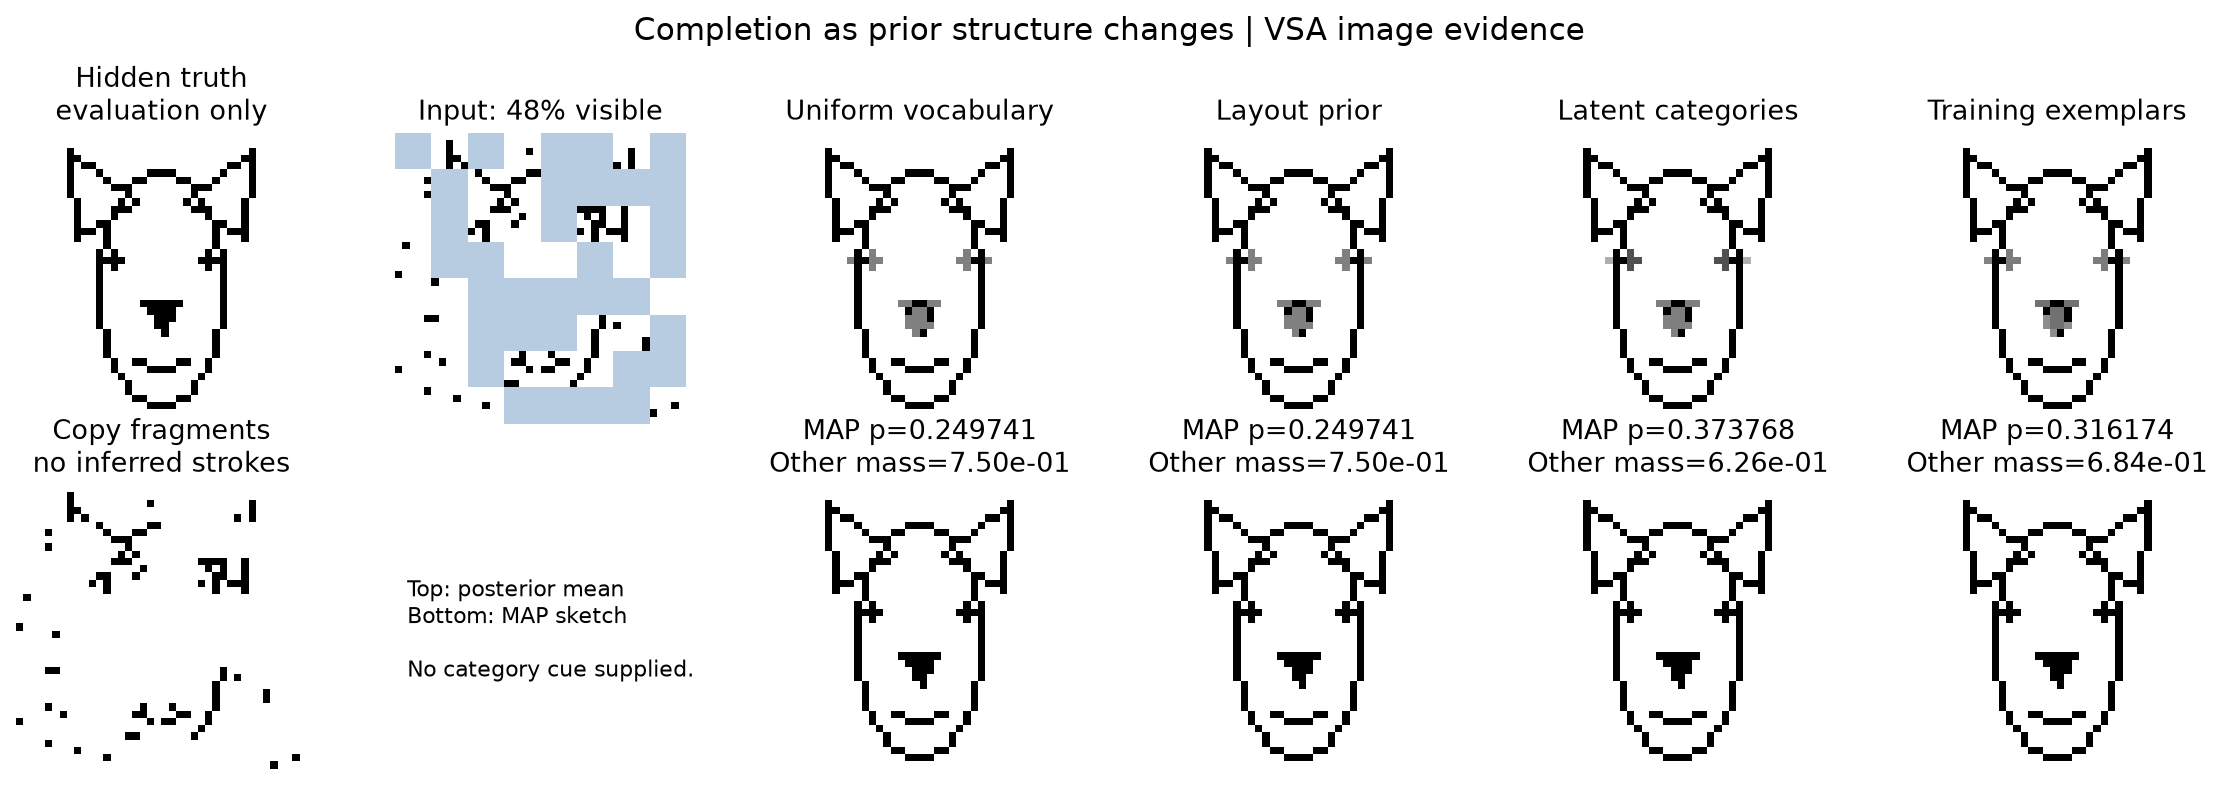

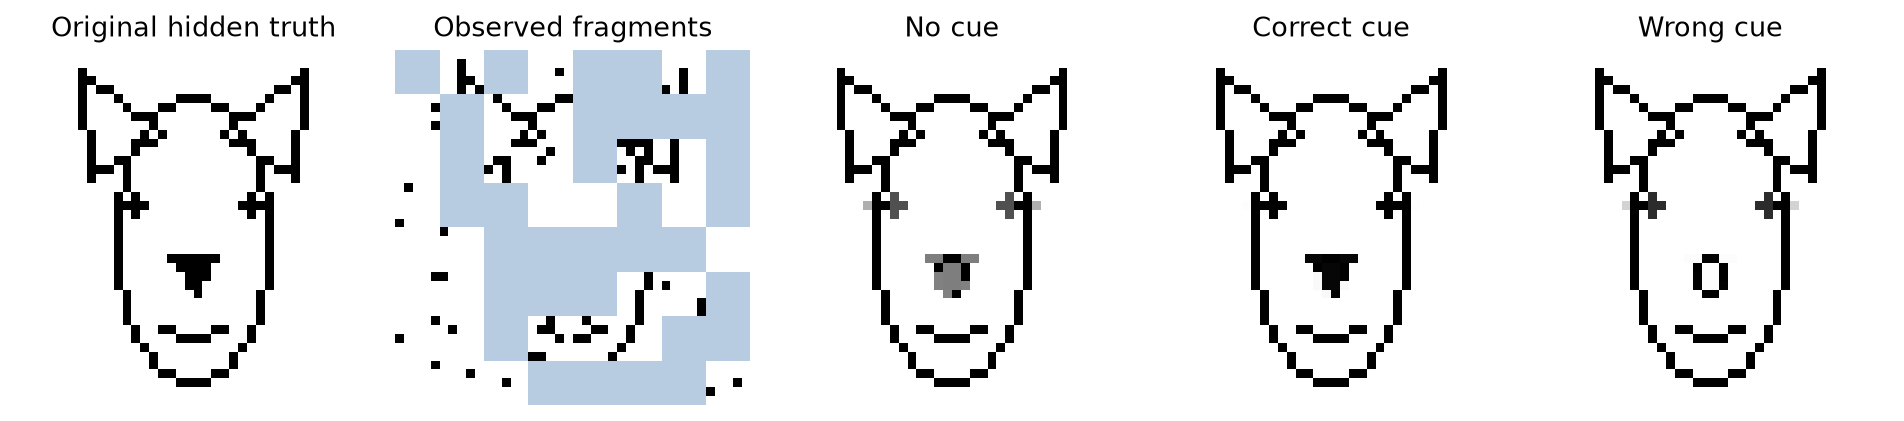

In [20]:
DEMO_CATEGORY = 1
DEMO_SEED = 67
DEMO_VISIBILITY = 0.35
CASE_STATE_ID = 594
OUT = OUT_ROOT / 'cat-like_seed67_visible35'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## cat-like · seed 67 · requested visibility 65%

Recipe: {'head shape': 'tall', 'ear shape': 'pointed', 'eye spacing': 'medium', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'dots'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.1176          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.041
Layout prior                       0.0000          1.000         0.000          0.041
Latent categories                  0.0000          1.000         0.000          0.041
Training exemplars                 0.0000          1.000         0.000          0.041
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.99999807 | 0.99999807 | medium / dots | 1.927e-06
  MAP recipe: {'head shape': 'tall', 'ear shape': 'pointed', 'eye spacing': 'medium', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'dots'}
Correct cue  | 0.99999994 |

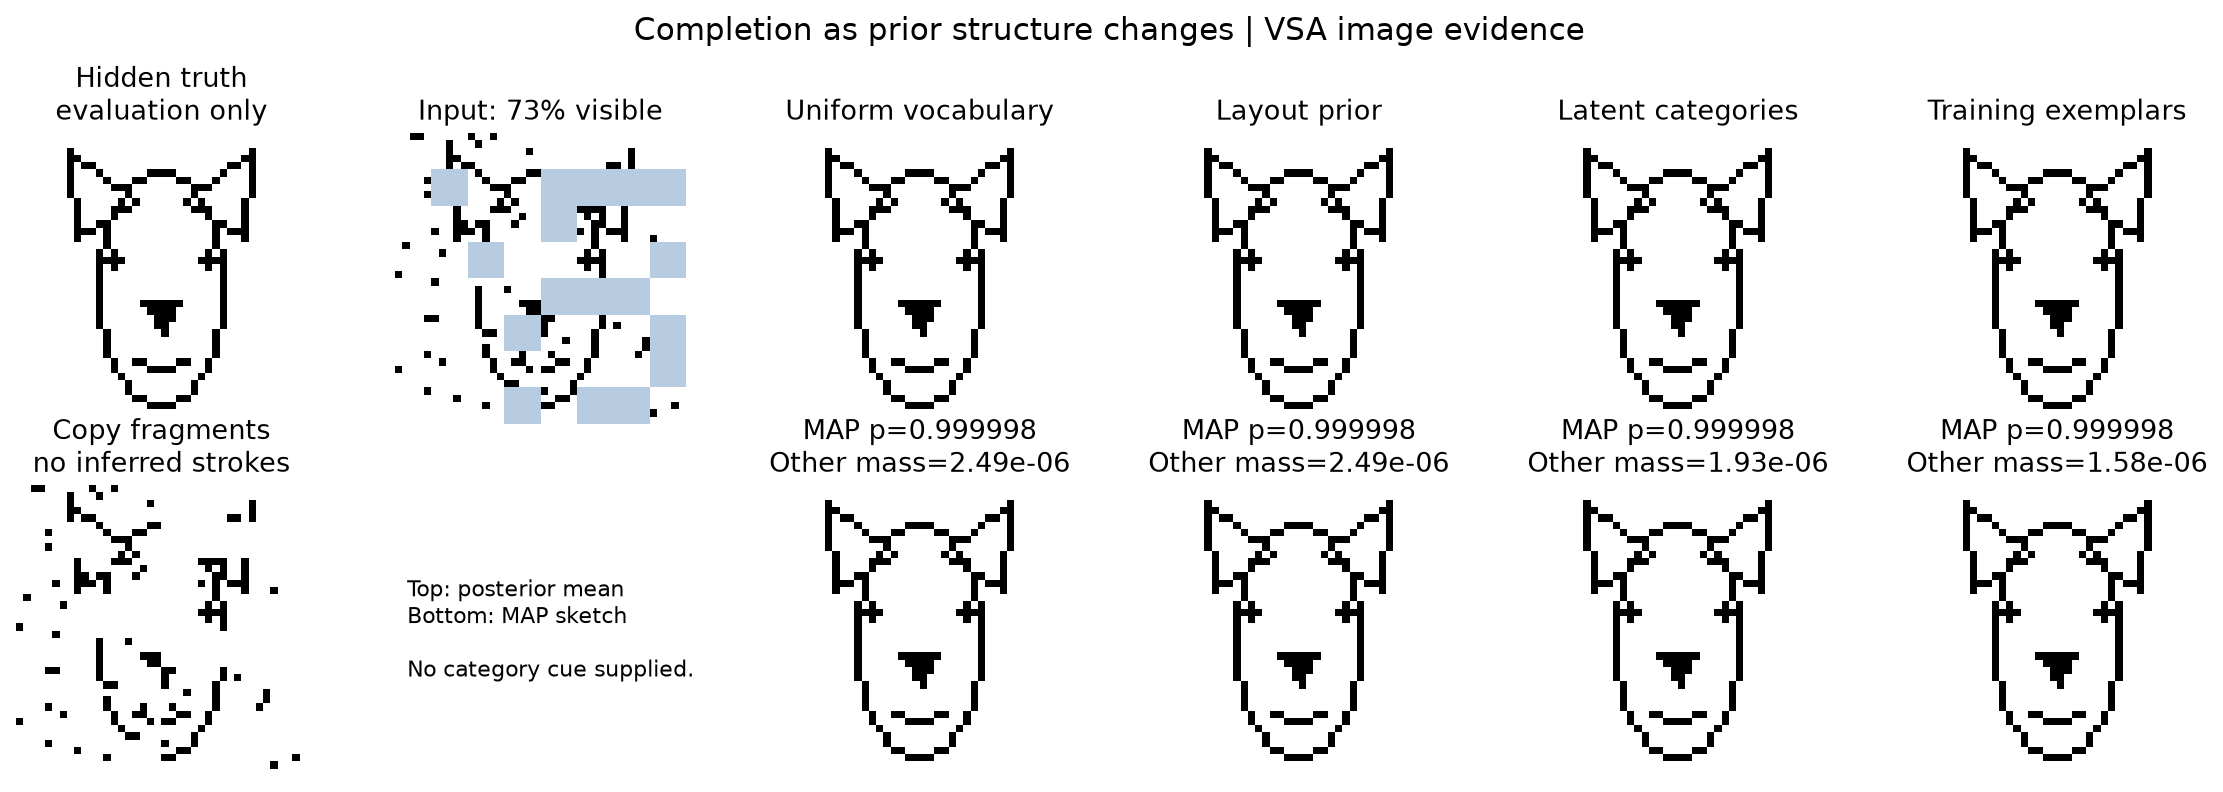

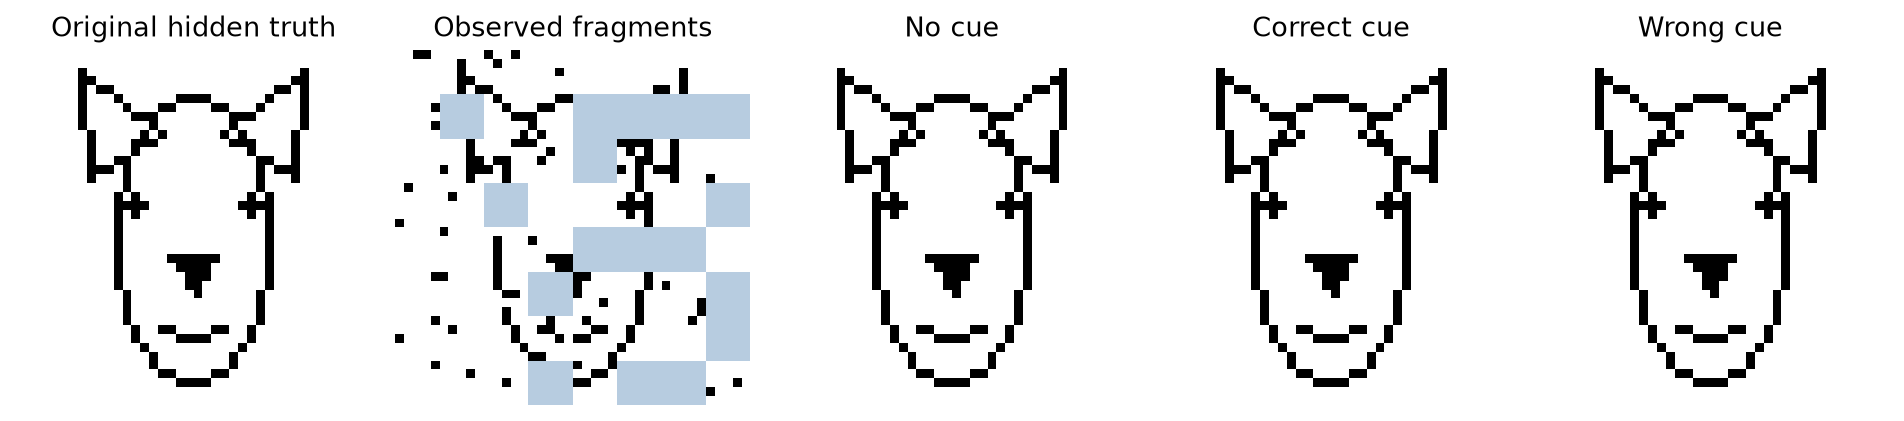

In [21]:
DEMO_CATEGORY = 1
DEMO_SEED = 67
DEMO_VISIBILITY = 0.65
CASE_STATE_ID = 594
OUT = OUT_ROOT / 'cat-like_seed67_visible65'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## human-like · seed 17 · requested visibility 15%

Recipe: {'head shape': 'tall', 'ear shape': 'long', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'arches'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.0960          0.000         0.000          0.000
Uniform vocabulary                 0.0065          0.909         0.000          0.049
Layout prior                       0.0065          0.909         0.000          0.049
Latent categories                  0.0042          0.924         0.000          0.049
Training exemplars                 0.0065          0.879         0.003          0.049
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.32536248 | 0.32536248 | narrow / arches | 6.746e-01
  MAP recipe: {'head shape': 'tall', 'ear shape': 'long', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'arches'}
Correct cue  | 0.85076672 | 0.850

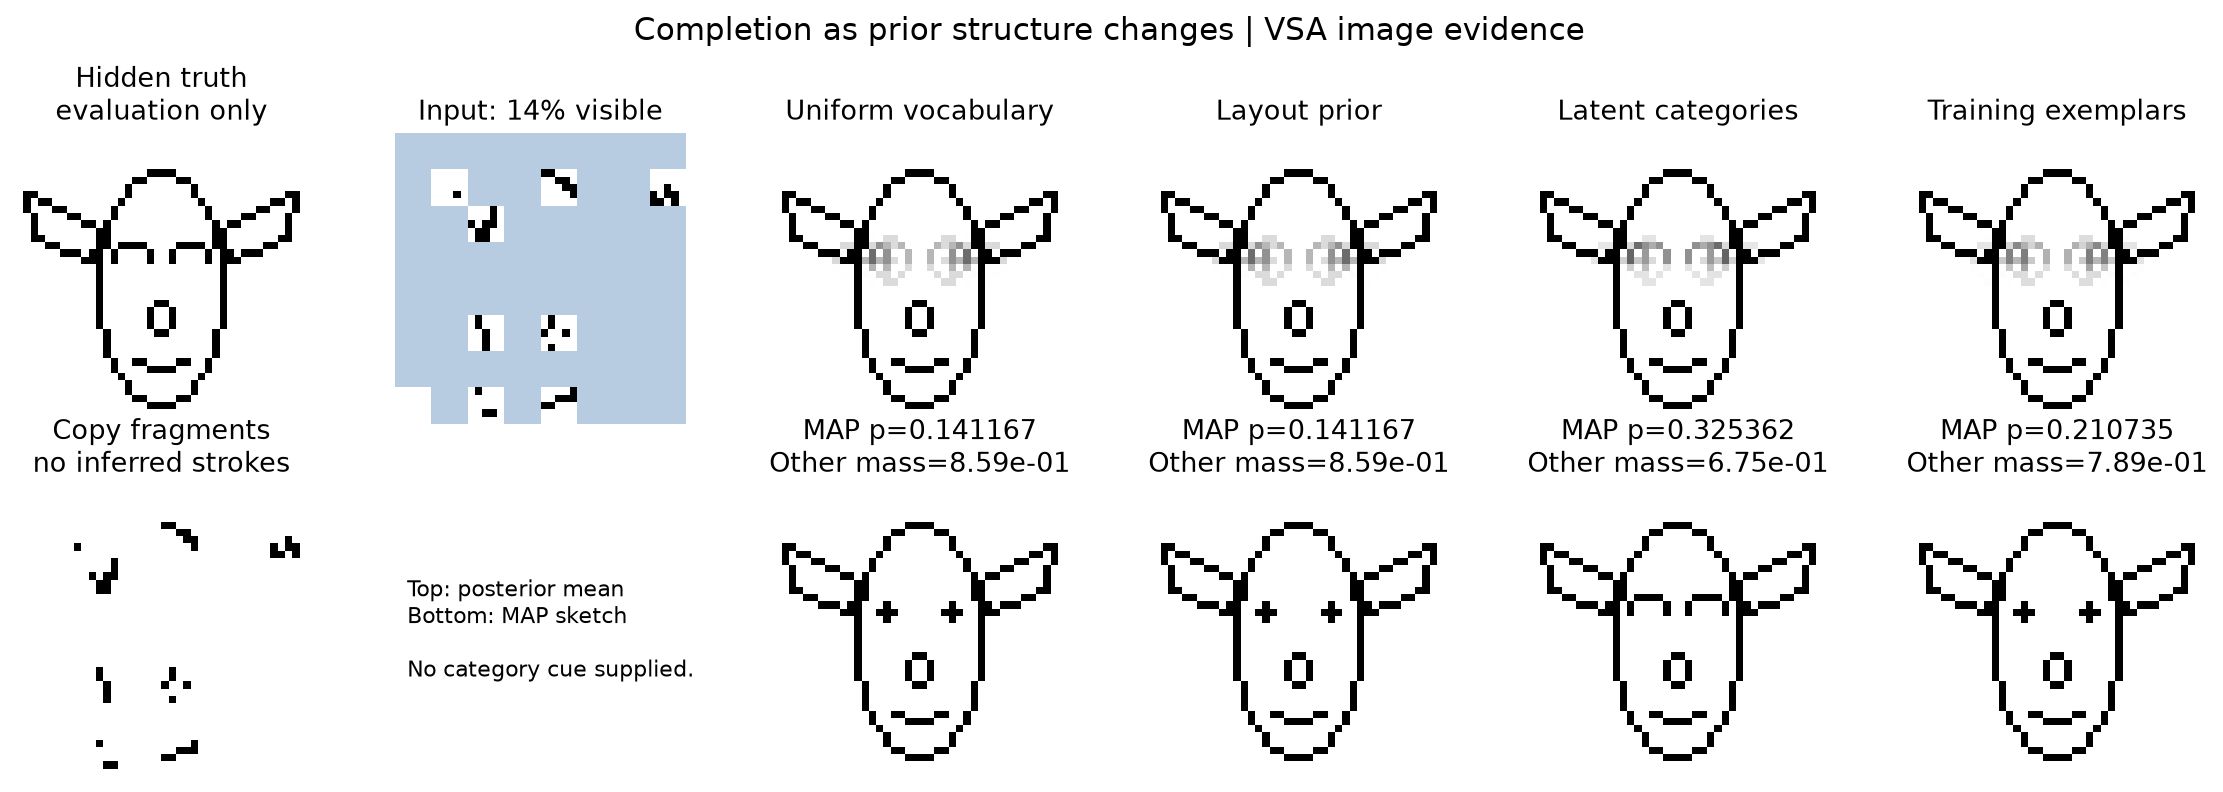

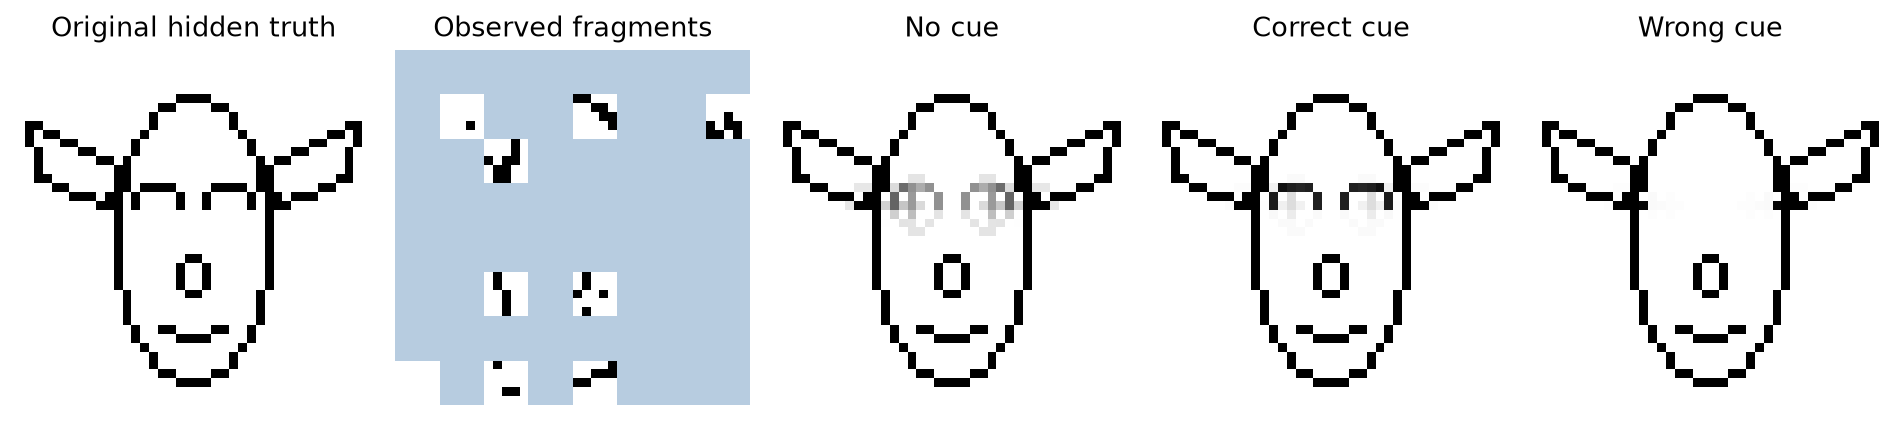

In [22]:
DEMO_CATEGORY = 2
DEMO_SEED = 17
DEMO_VISIBILITY = 0.15
CASE_STATE_ID = 658
OUT = OUT_ROOT / 'human-like_seed17_visible15'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## human-like · seed 17 · requested visibility 35%

Recipe: {'head shape': 'tall', 'ear shape': 'long', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'arches'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.1046          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.037
Layout prior                       0.0000          1.000         0.000          0.037
Latent categories                  0.0000          1.000         0.000          0.037
Training exemplars                 0.0000          1.000         0.000          0.037
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.99739161 | 0.99739161 | narrow / arches | 2.608e-03
  MAP recipe: {'head shape': 'tall', 'ear shape': 'long', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'arches'}
Correct cue  | 0.99966000 | 0.999

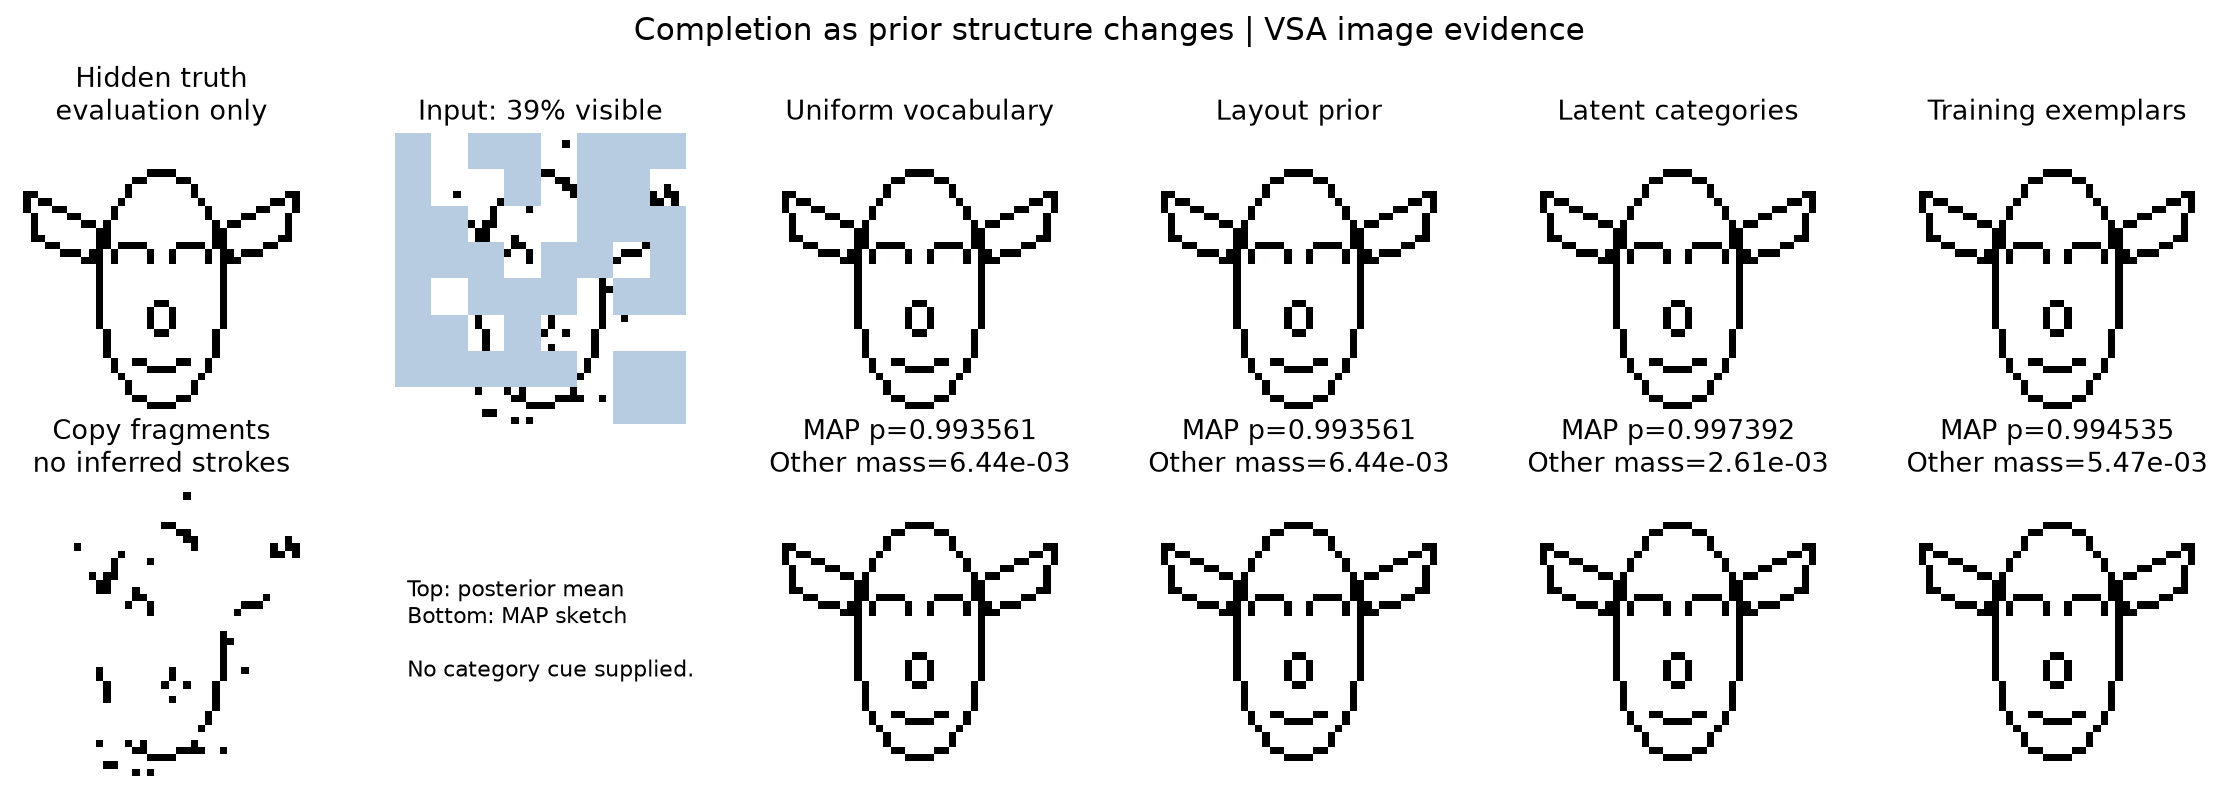

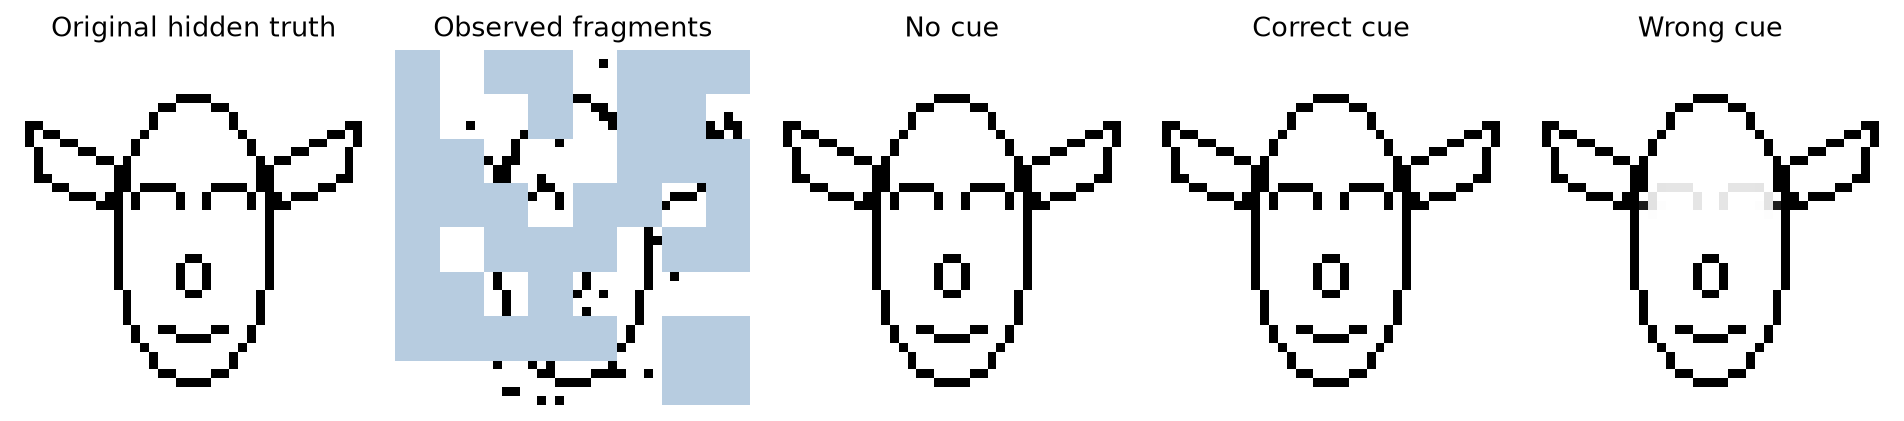

In [23]:
DEMO_CATEGORY = 2
DEMO_SEED = 17
DEMO_VISIBILITY = 0.35
CASE_STATE_ID = 658
OUT = OUT_ROOT / 'human-like_seed17_visible35'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## human-like · seed 17 · requested visibility 65%

Recipe: {'head shape': 'tall', 'ear shape': 'long', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'arches'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.1229          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.043
Layout prior                       0.0000          1.000         0.000          0.043
Latent categories                  0.0000          1.000         0.000          0.043
Training exemplars                 0.0000          1.000         0.000          0.043
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 1.00000000 | 1.00000000 | narrow / arches | 1.727e-11
  MAP recipe: {'head shape': 'tall', 'ear shape': 'long', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'arches'}
Correct cue  | 1.00000000 | 1.000

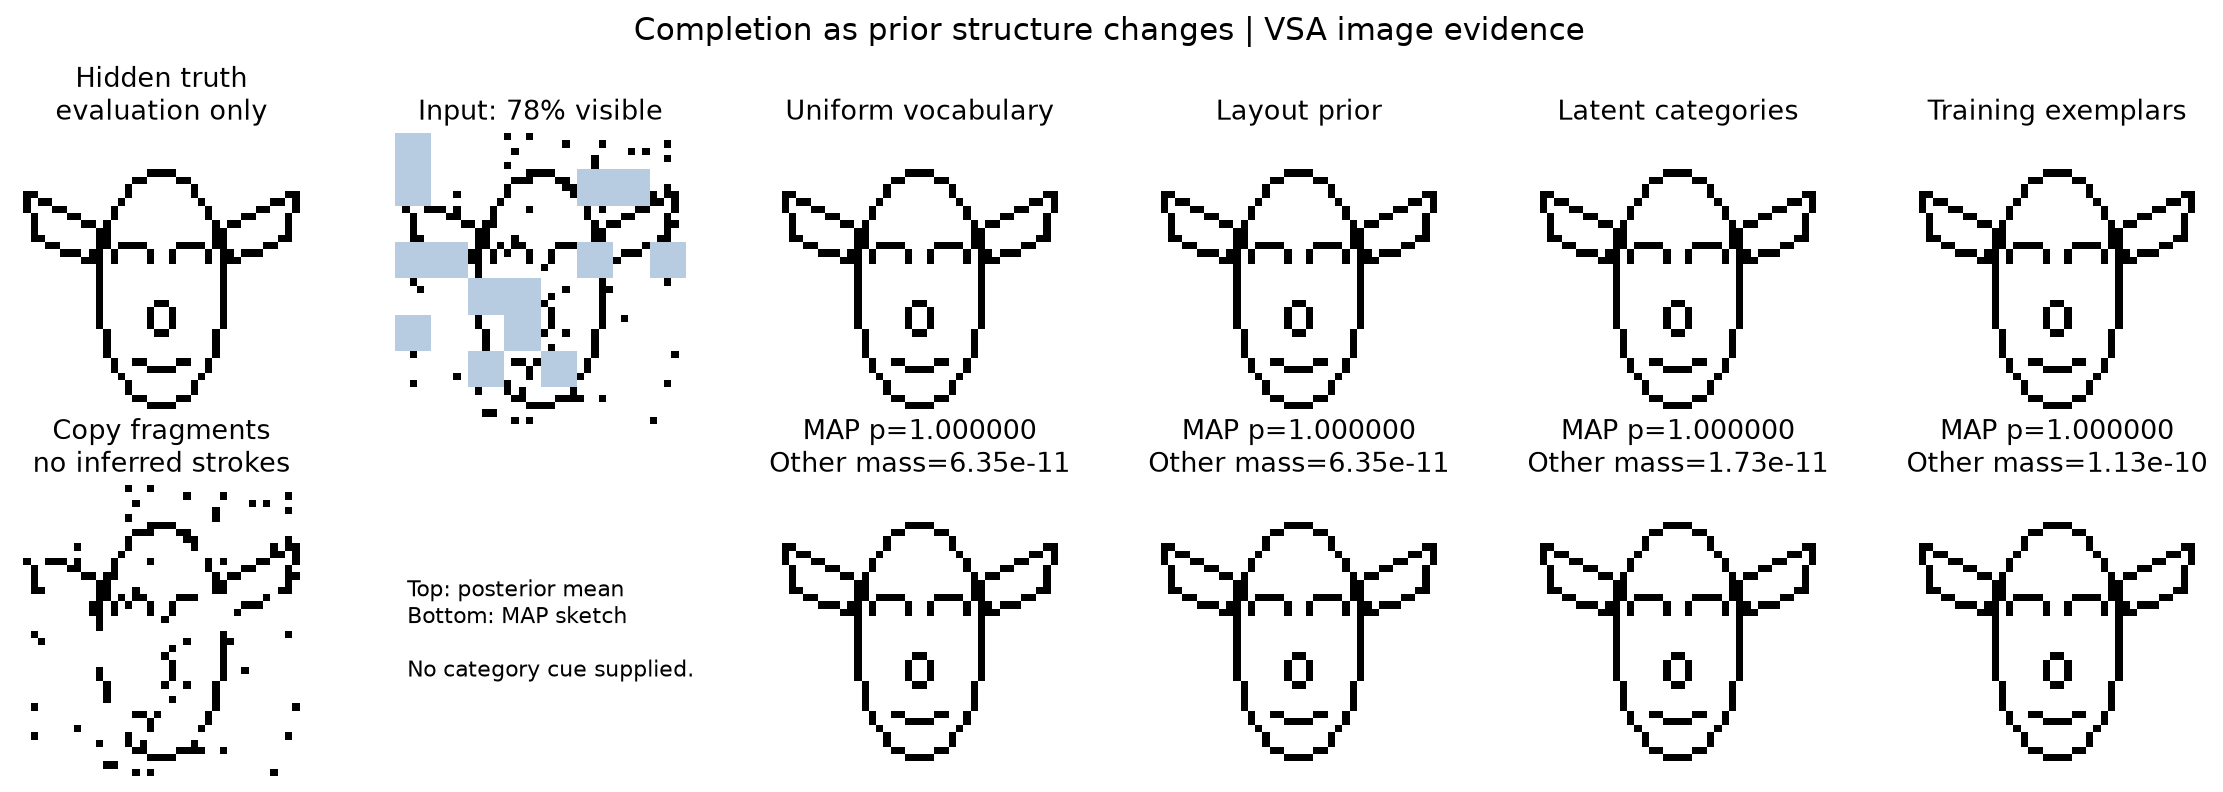

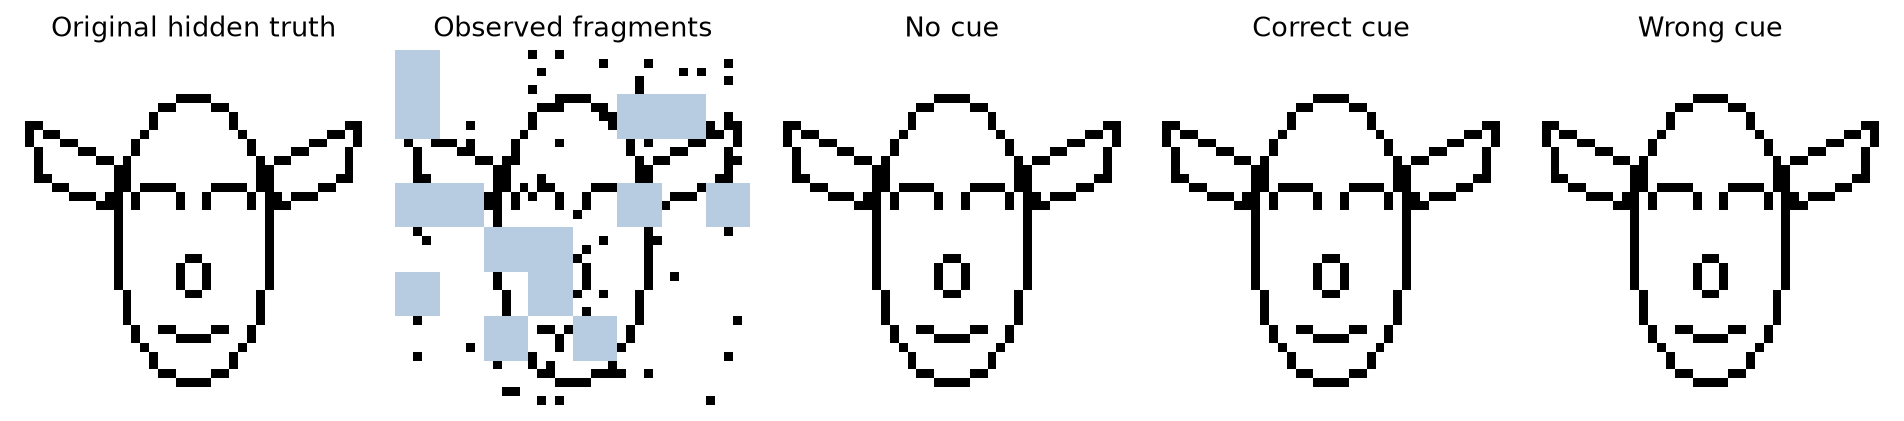

In [24]:
DEMO_CATEGORY = 2
DEMO_SEED = 17
DEMO_VISIBILITY = 0.65
CASE_STATE_ID = 658
OUT = OUT_ROOT / 'human-like_seed17_visible65'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## human-like · seed 37 · requested visibility 15%

Recipe: {'head shape': 'tall', 'ear shape': 'round', 'eye spacing': 'wide', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'arches'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.0720          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.049
Layout prior                       0.0000          1.000         0.000          0.049
Latent categories                  0.0000          1.000         0.000          0.049
Training exemplars                 0.0000          1.000         0.000          0.049
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.99997264 | 0.99997264 | wide / arches | 2.736e-05
  MAP recipe: {'head shape': 'tall', 'ear shape': 'round', 'eye spacing': 'wide', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'arches'}
Correct cue  | 0.99999796 | 0.9999979

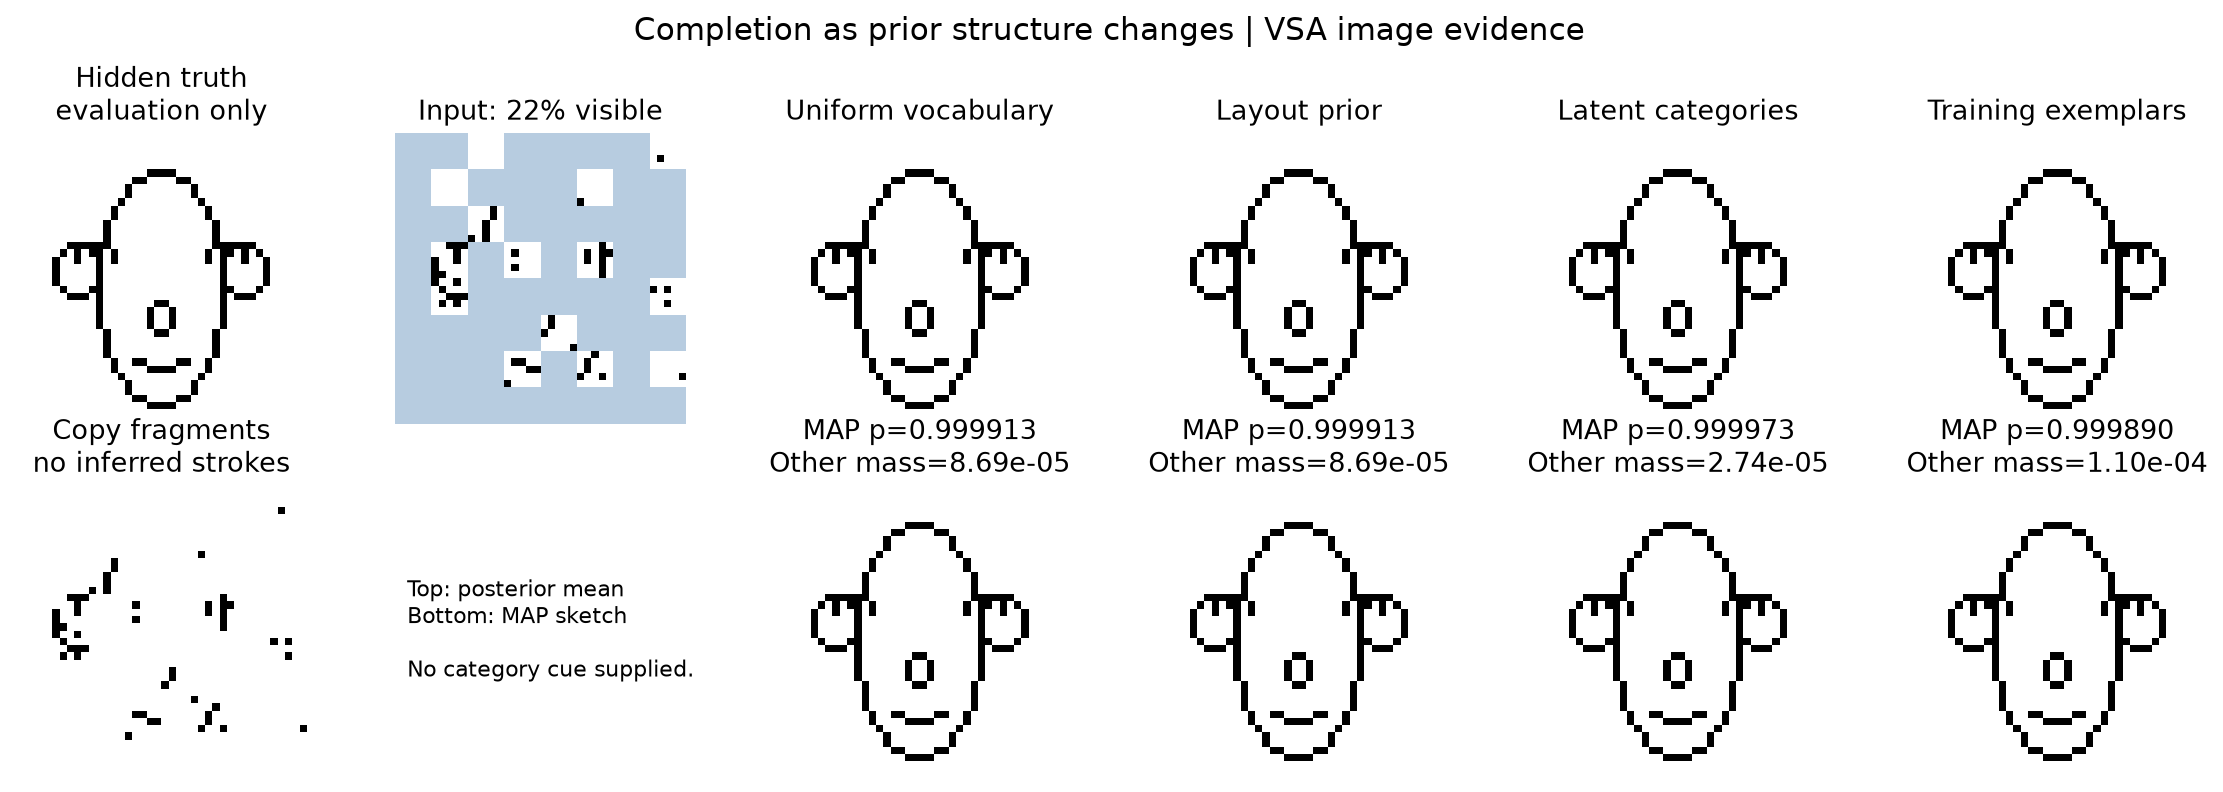

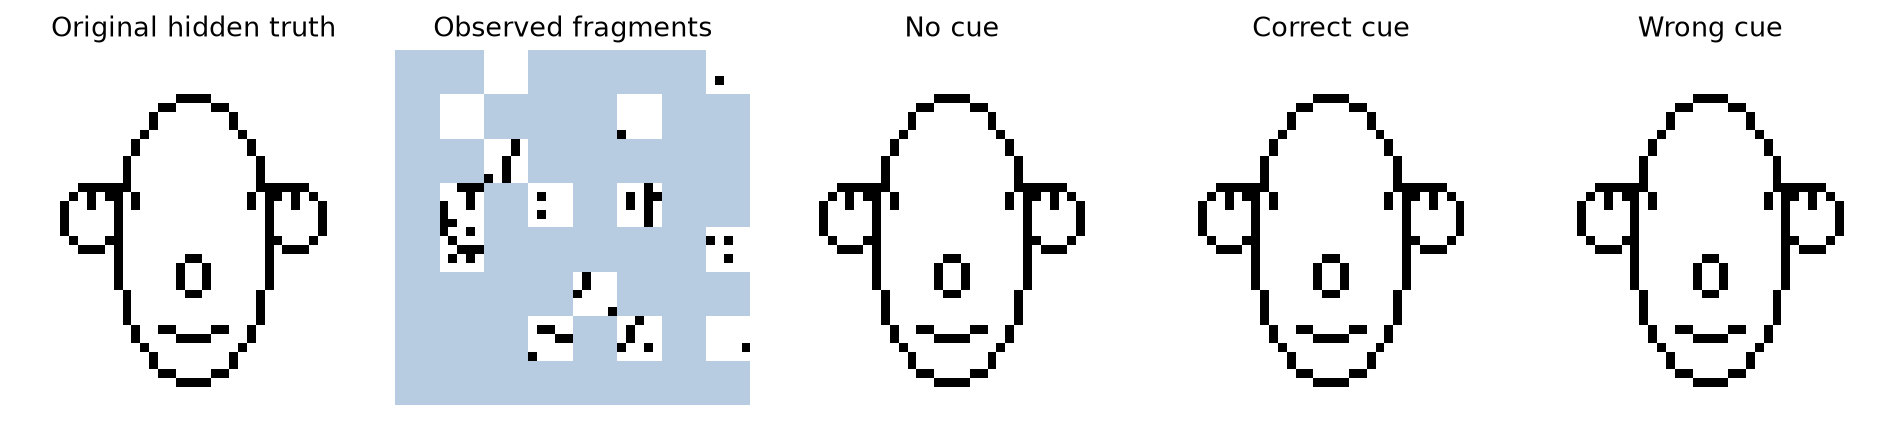

In [25]:
DEMO_CATEGORY = 2
DEMO_SEED = 37
DEMO_VISIBILITY = 0.15
CASE_STATE_ID = 550
OUT = OUT_ROOT / 'human-like_seed37_visible15'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## human-like · seed 37 · requested visibility 35%

Recipe: {'head shape': 'tall', 'ear shape': 'round', 'eye spacing': 'wide', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'arches'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.0627          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.041
Layout prior                       0.0000          1.000         0.000          0.041
Latent categories                  0.0000          1.000         0.000          0.041
Training exemplars                 0.0000          1.000         0.000          0.041
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.99999997 | 0.99999997 | wide / arches | 2.771e-08
  MAP recipe: {'head shape': 'tall', 'ear shape': 'round', 'eye spacing': 'wide', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'arches'}
Correct cue  | 1.00000000 | 1.0000000

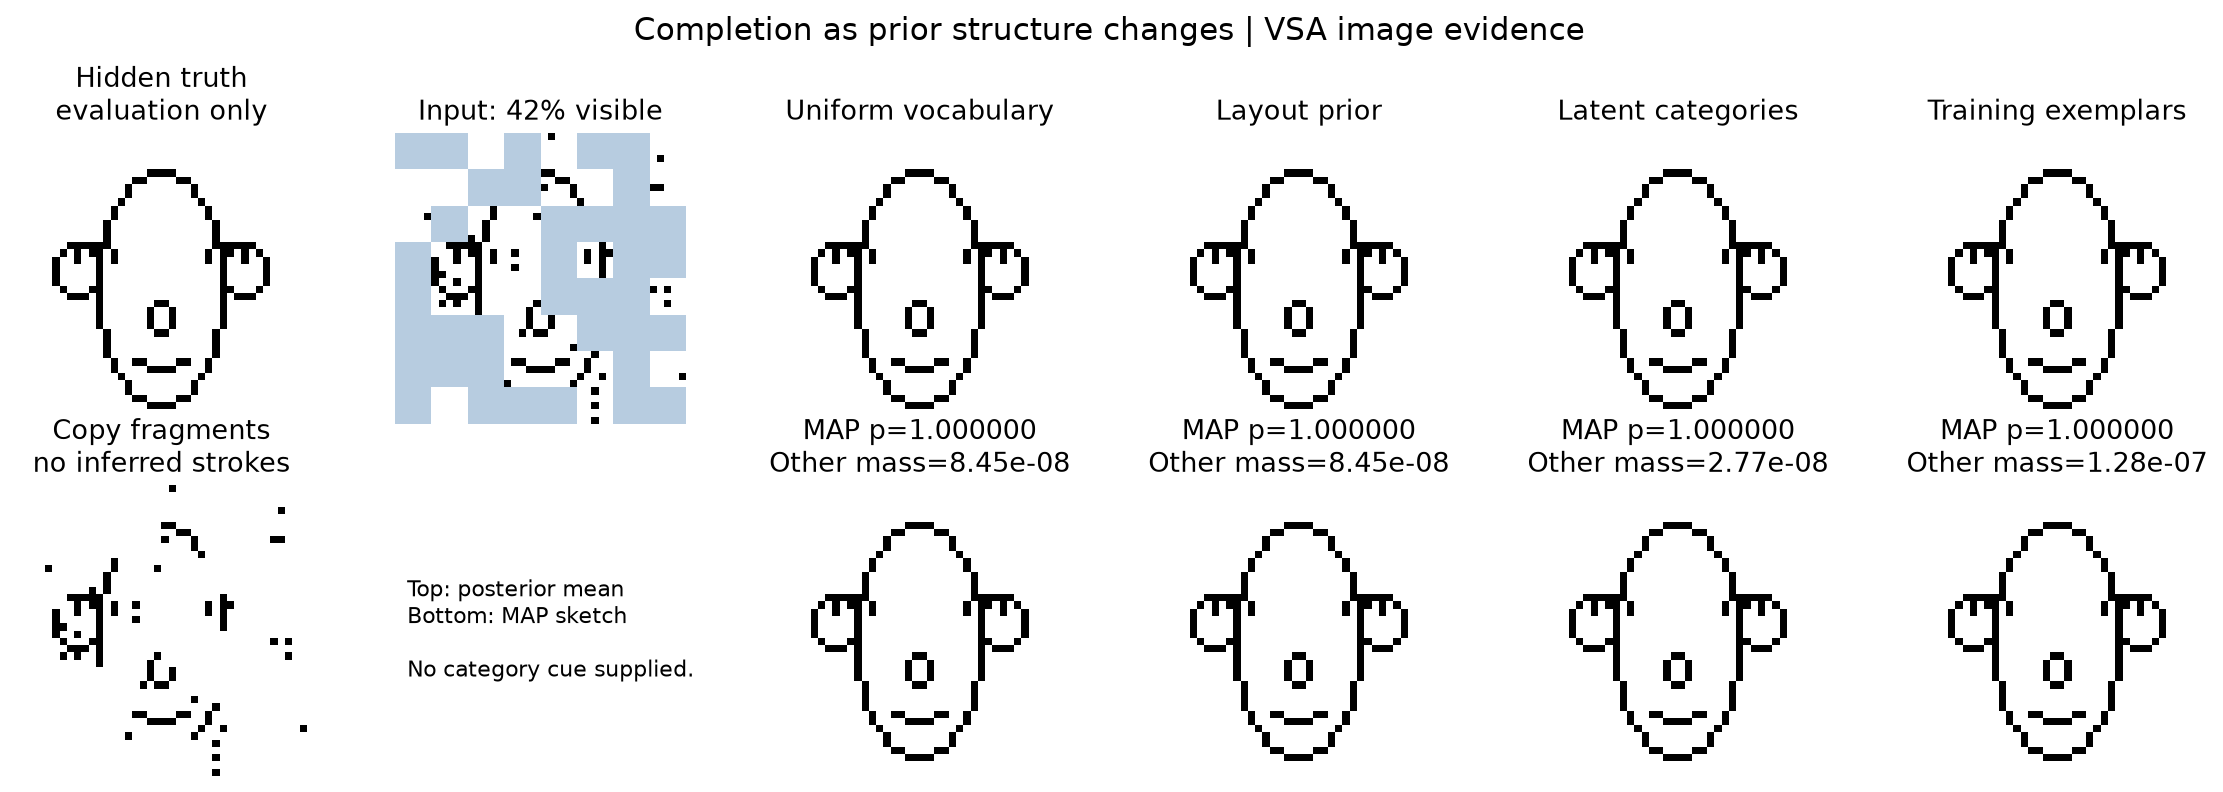

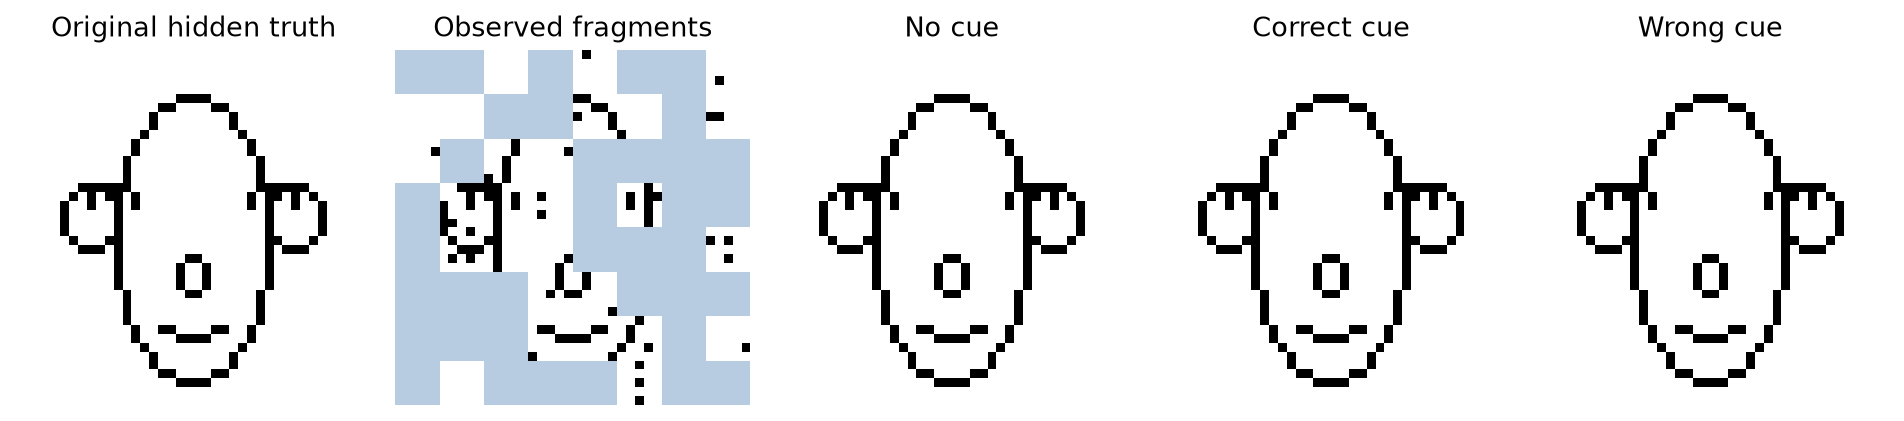

In [26]:
DEMO_CATEGORY = 2
DEMO_SEED = 37
DEMO_VISIBILITY = 0.35
CASE_STATE_ID = 550
OUT = OUT_ROOT / 'human-like_seed37_visible35'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## human-like · seed 37 · requested visibility 65%

Recipe: {'head shape': 'tall', 'ear shape': 'round', 'eye spacing': 'wide', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'arches'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.0491          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.048
Layout prior                       0.0000          1.000         0.000          0.048
Latent categories                  0.0000          1.000         0.000          0.048
Training exemplars                 0.0000          1.000         0.000          0.048
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 1.00000000 | 1.00000000 | wide / arches | 9.895e-11
  MAP recipe: {'head shape': 'tall', 'ear shape': 'round', 'eye spacing': 'wide', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'arches'}
Correct cue  | 1.00000000 | 1.0000000

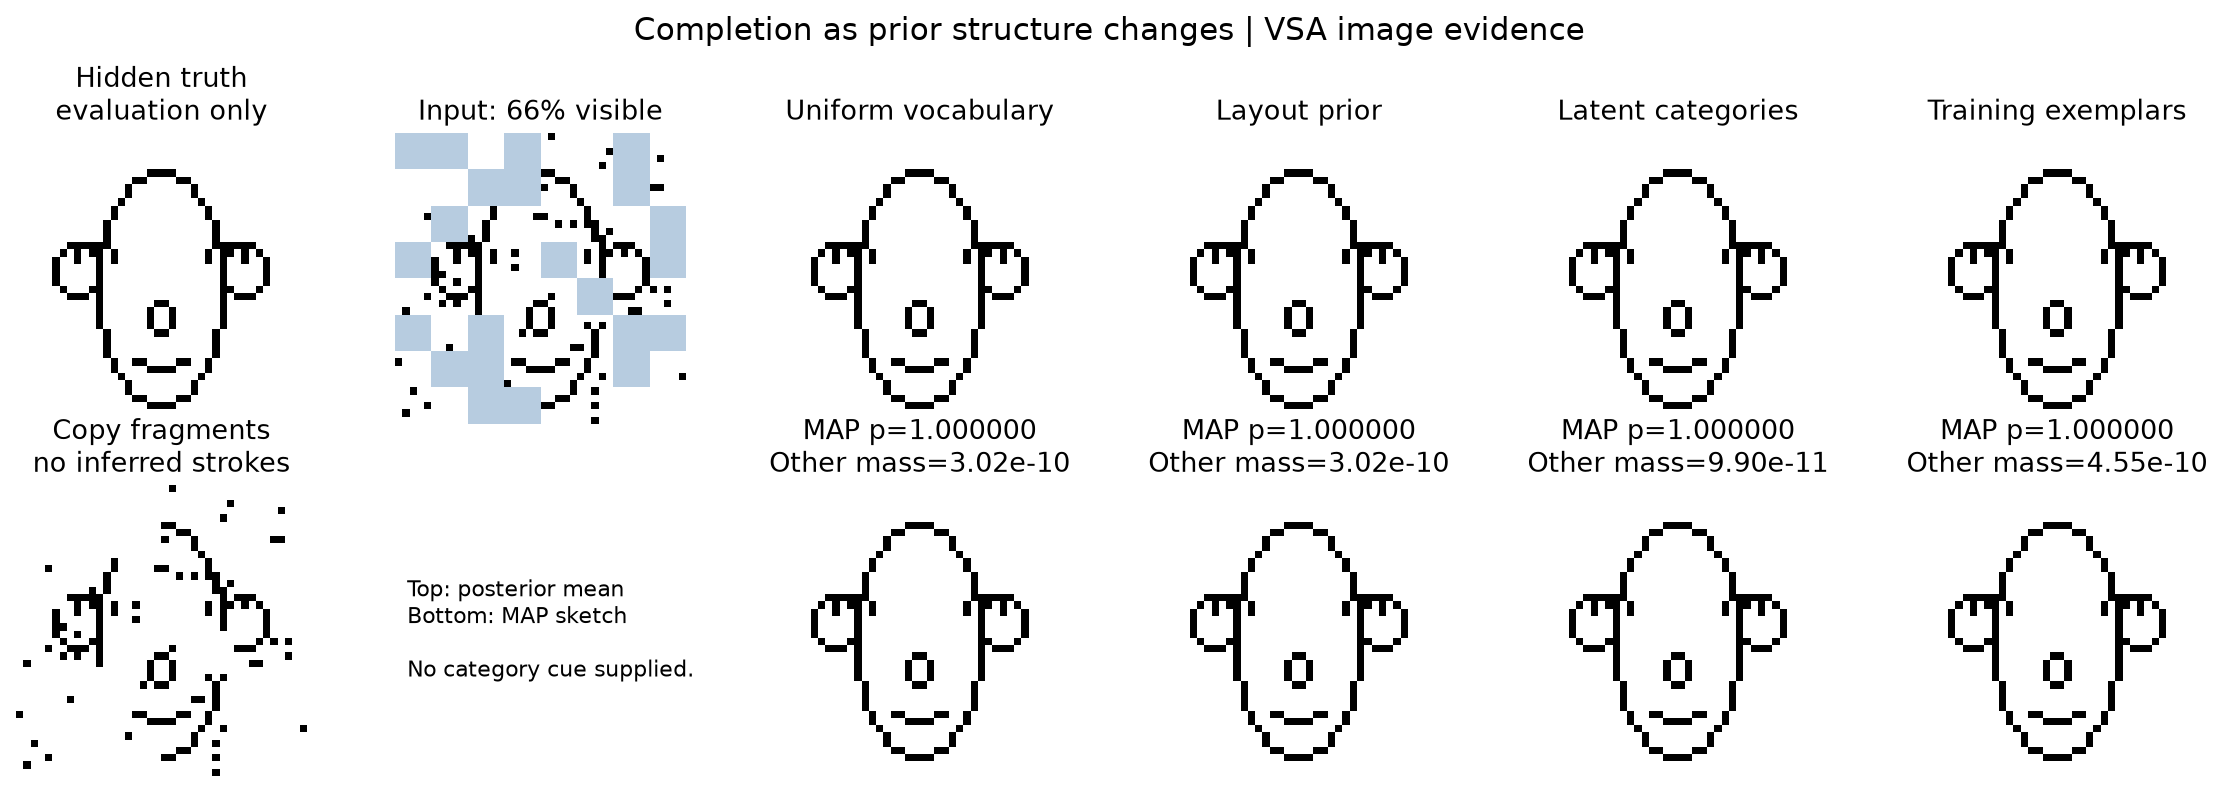

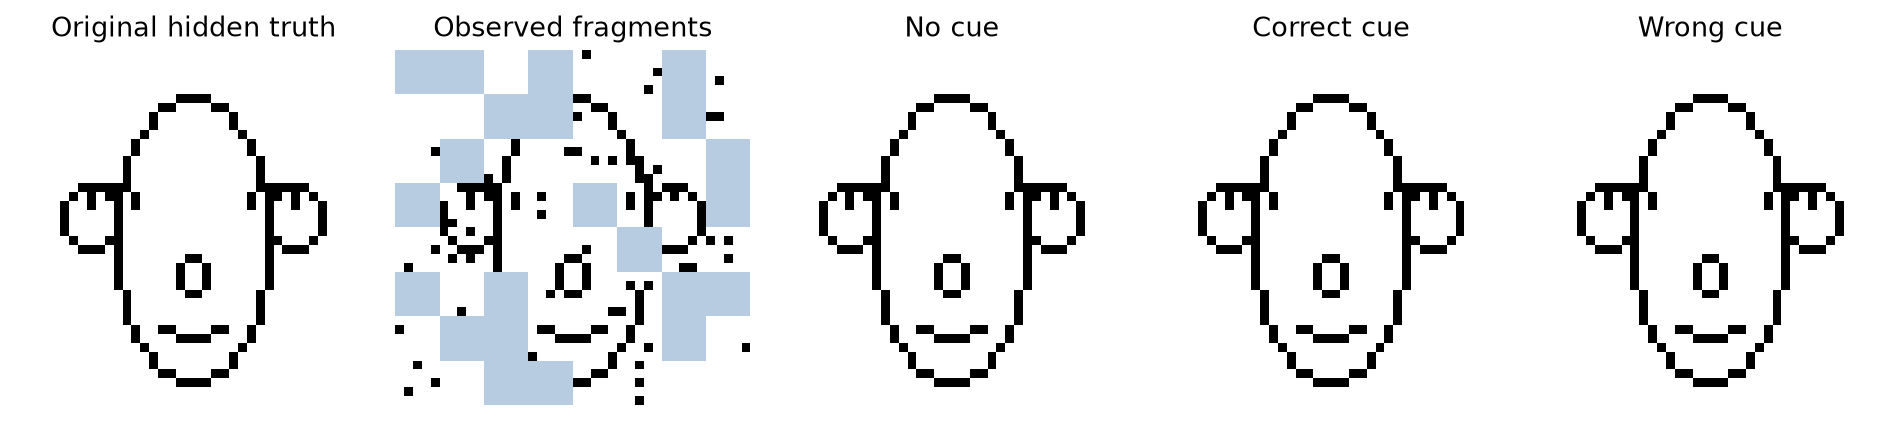

In [27]:
DEMO_CATEGORY = 2
DEMO_SEED = 37
DEMO_VISIBILITY = 0.65
CASE_STATE_ID = 550
OUT = OUT_ROOT / 'human-like_seed37_visible65'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## human-like · seed 67 · requested visibility 15%

Recipe: {'head shape': 'tall', 'ear shape': 'round', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'lowered', 'eye shape': 'arches'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.0837          0.000         0.000          0.000
Uniform vocabulary                 0.0026          0.965         0.000          0.036
Layout prior                       0.0026          0.965         0.000          0.036
Latent categories                  0.0004          1.000         0.000          0.036
Training exemplars                 0.0010          1.000         0.000          0.036
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.80057438 | 0.80057438 | narrow / arches | 1.994e-01
  MAP recipe: {'head shape': 'tall', 'ear shape': 'round', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'lowered', 'eye shape': 'arches'}
Correct cue  | 0.98560668 | 0.9

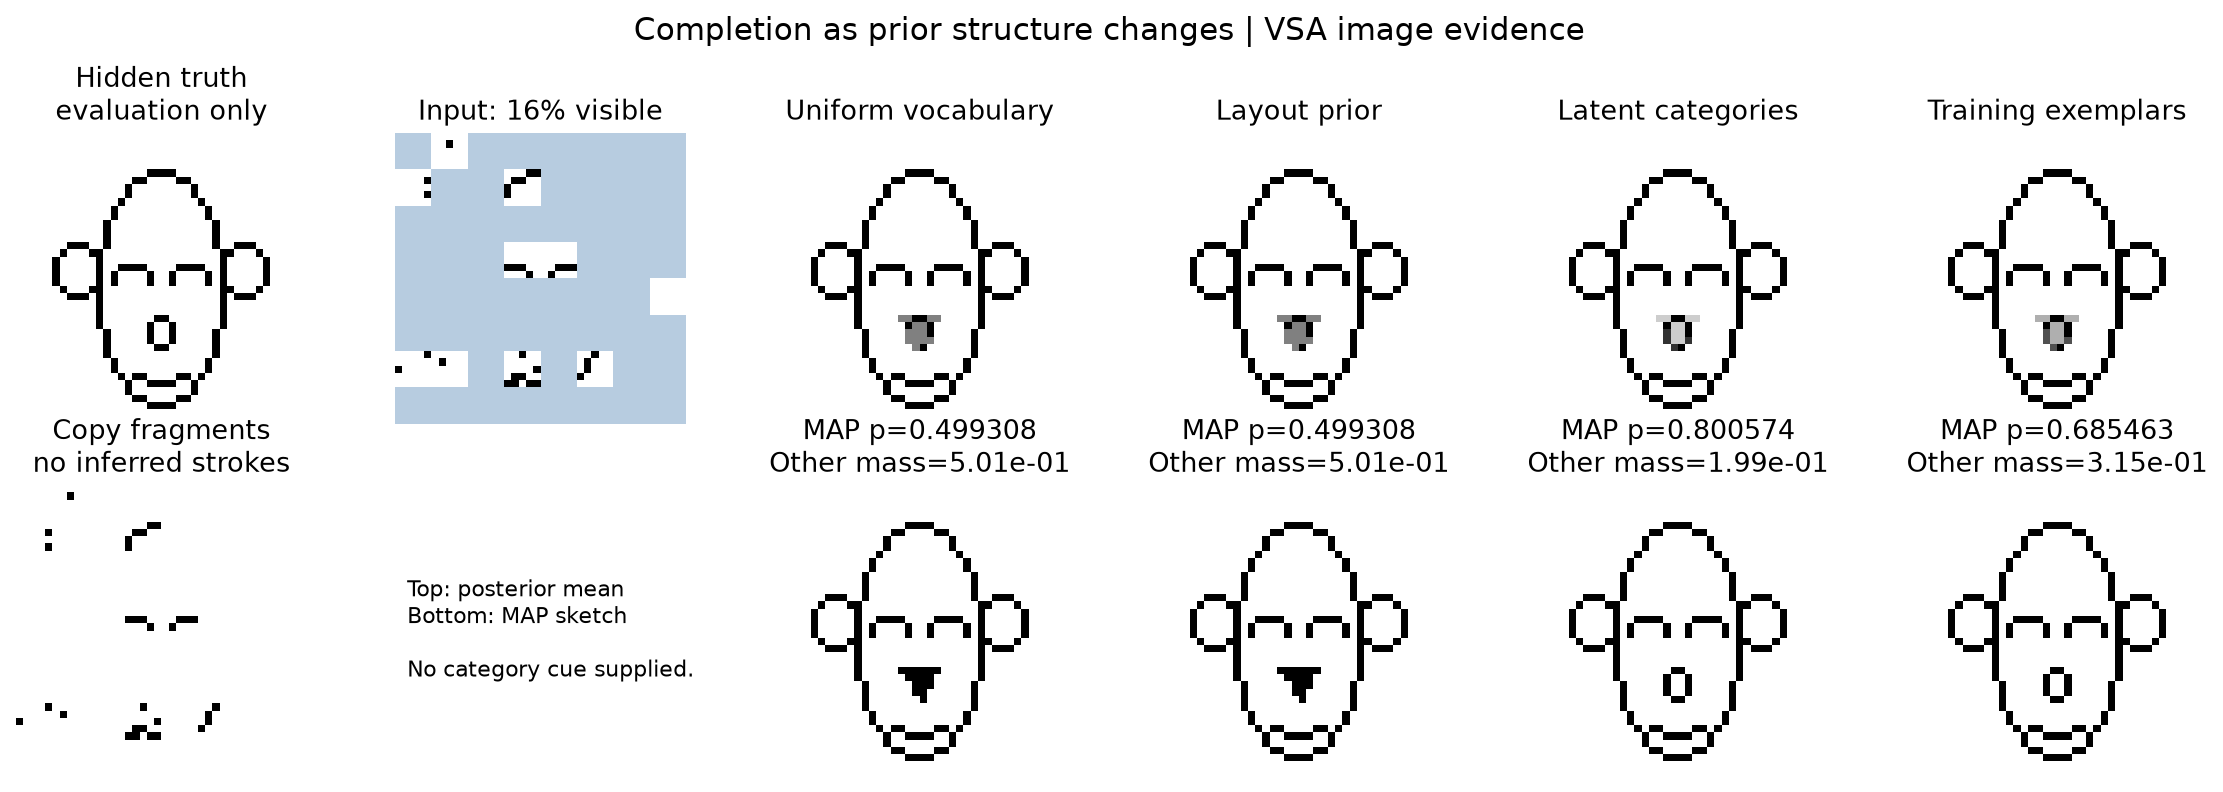

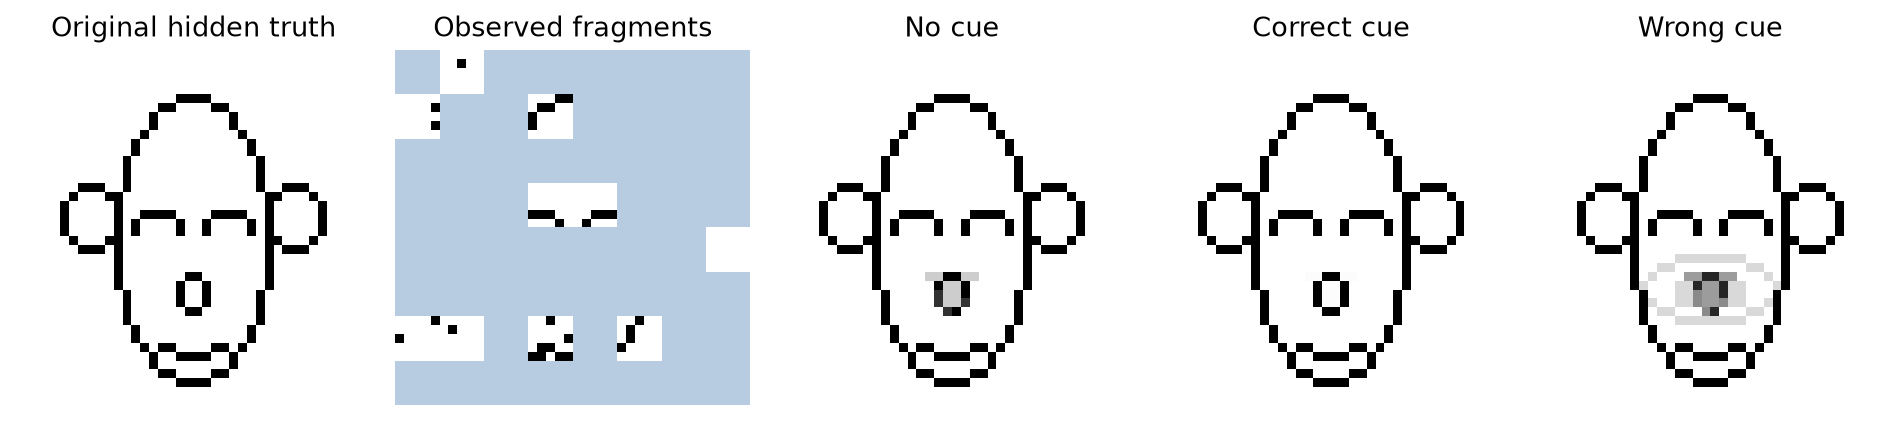

In [28]:
DEMO_CATEGORY = 2
DEMO_SEED = 67
DEMO_VISIBILITY = 0.15
CASE_STATE_ID = 499
OUT = OUT_ROOT / 'human-like_seed67_visible15'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## human-like · seed 67 · requested visibility 35%

Recipe: {'head shape': 'tall', 'ear shape': 'round', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'lowered', 'eye shape': 'arches'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.0970          0.000         0.000          0.000
Uniform vocabulary                 0.0042          0.950         0.000          0.041
Layout prior                       0.0042          0.950         0.000          0.041
Latent categories                  0.0007          1.000         0.000          0.041
Training exemplars                 0.0017          1.000         0.000          0.041
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.80125180 | 0.80125180 | narrow / arches | 1.987e-01
  MAP recipe: {'head shape': 'tall', 'ear shape': 'round', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'lowered', 'eye shape': 'arches'}
Correct cue  | 0.98575230 | 0.9

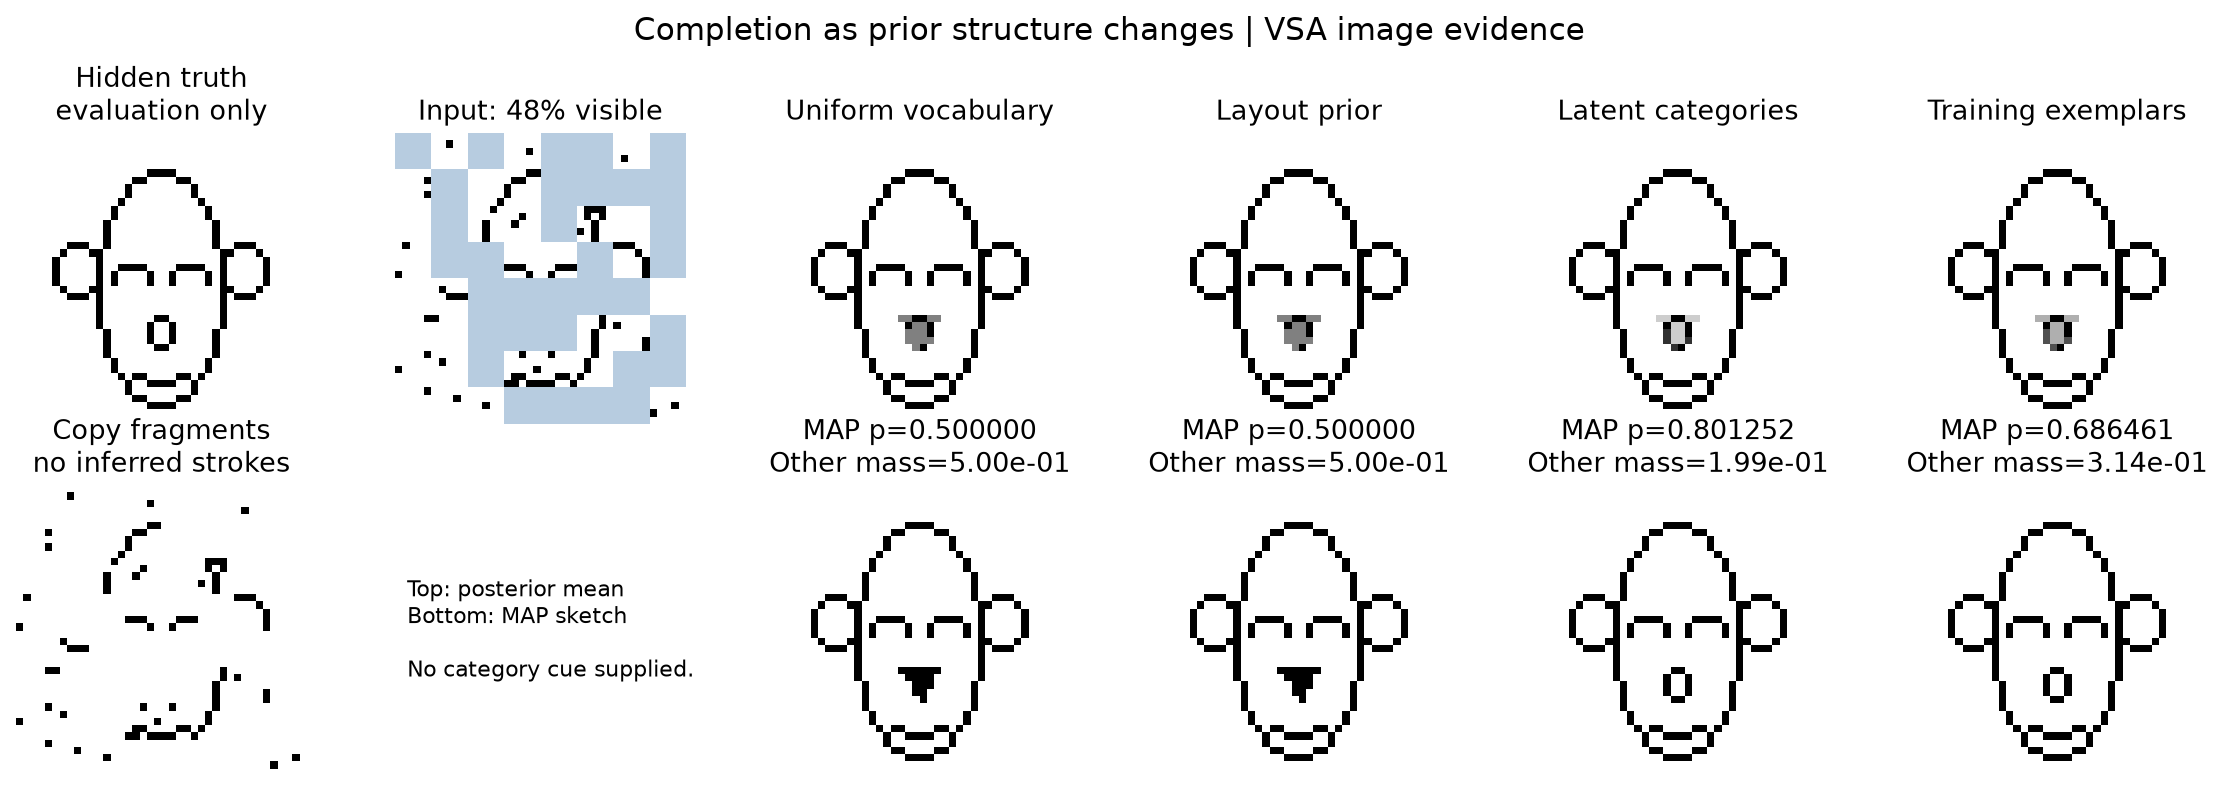

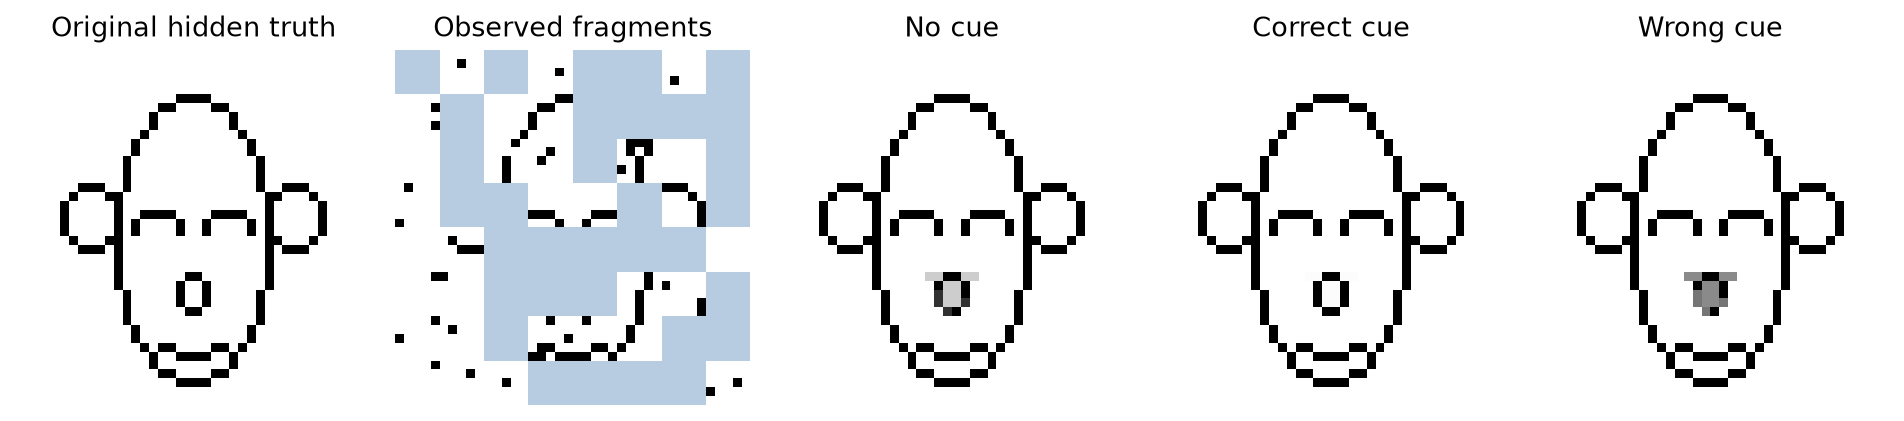

In [29]:
DEMO_CATEGORY = 2
DEMO_SEED = 67
DEMO_VISIBILITY = 0.35
CASE_STATE_ID = 499
OUT = OUT_ROOT / 'human-like_seed67_visible35'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")

## human-like · seed 67 · requested visibility 65%

Recipe: {'head shape': 'tall', 'ear shape': 'round', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'lowered', 'eye shape': 'arches'}
Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.0894          0.000         0.000          0.000
Uniform vocabulary                 0.0000          1.000         0.000          0.041
Layout prior                       0.0000          1.000         0.000          0.041
Latent categories                  0.0000          1.000         0.000          0.041
Training exemplars                 0.0000          1.000         0.000          0.041
Cue condition | P(original) | P(MAP) | MAP eye spacing / shape | Other probability mass
No cue       | 0.99989340 | 0.99989340 | narrow / arches | 1.066e-04
  MAP recipe: {'head shape': 'tall', 'ear shape': 'round', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'lowered', 'eye shape': 'arches'}
Correct cue  | 0.99999379 | 0.9

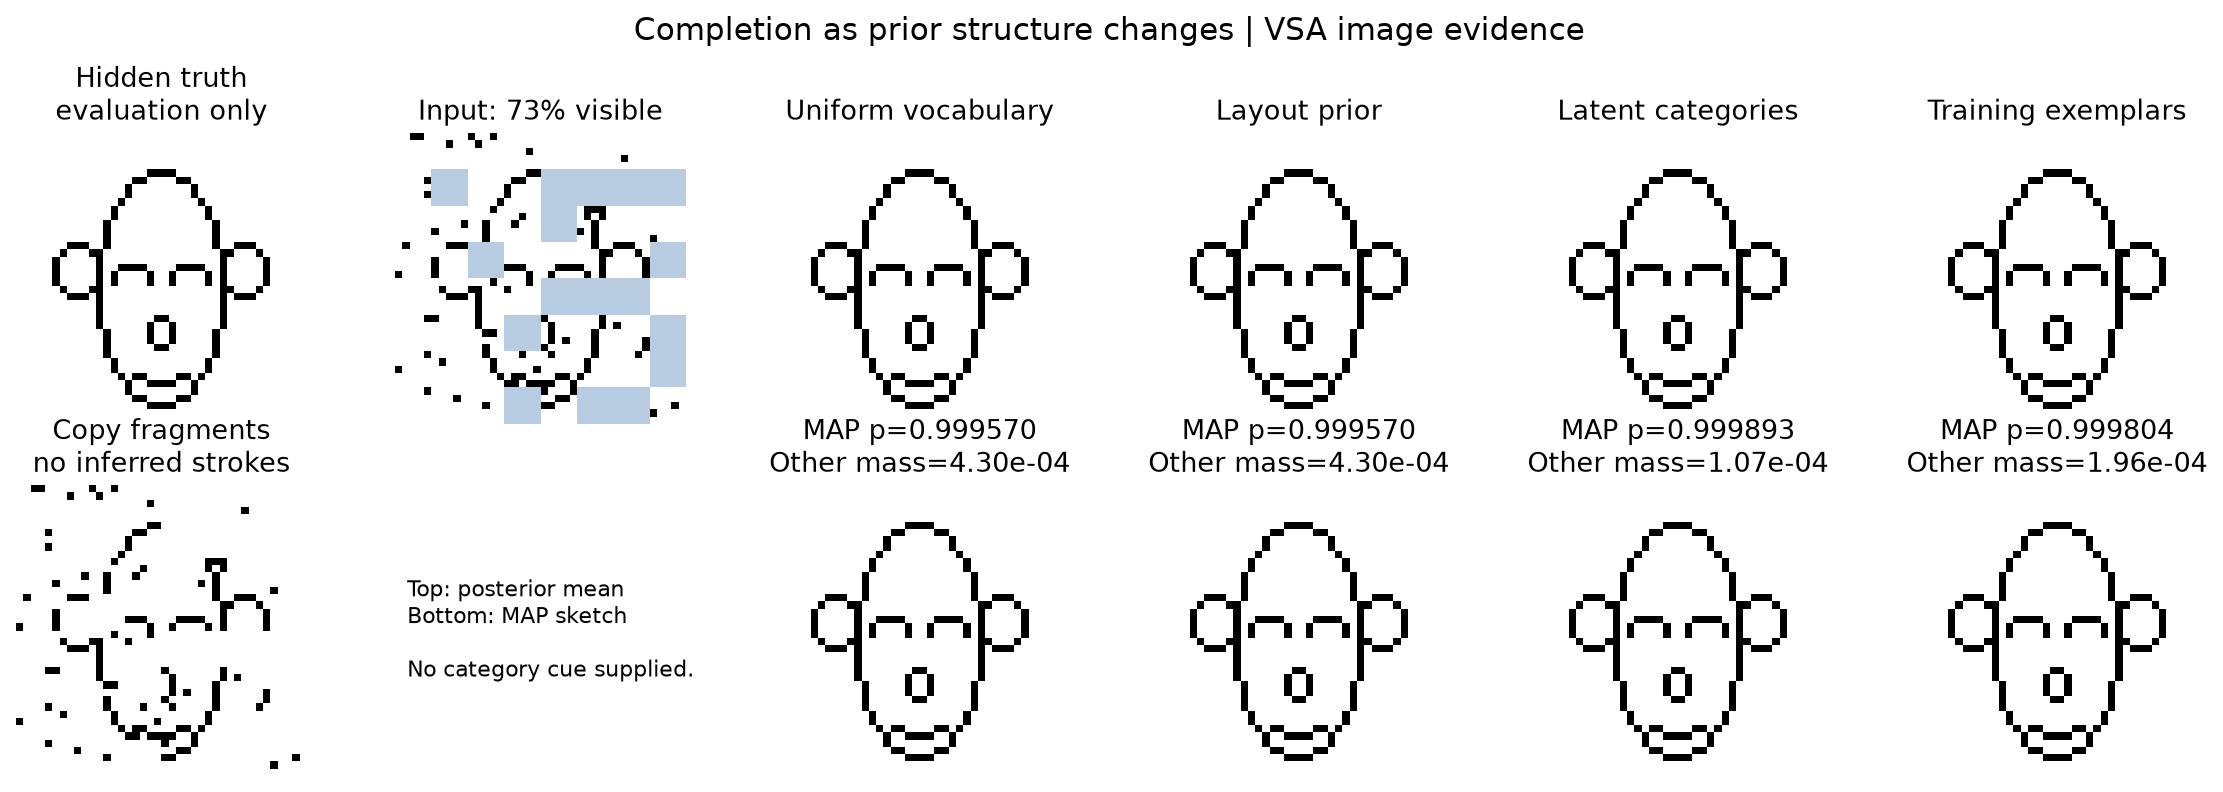

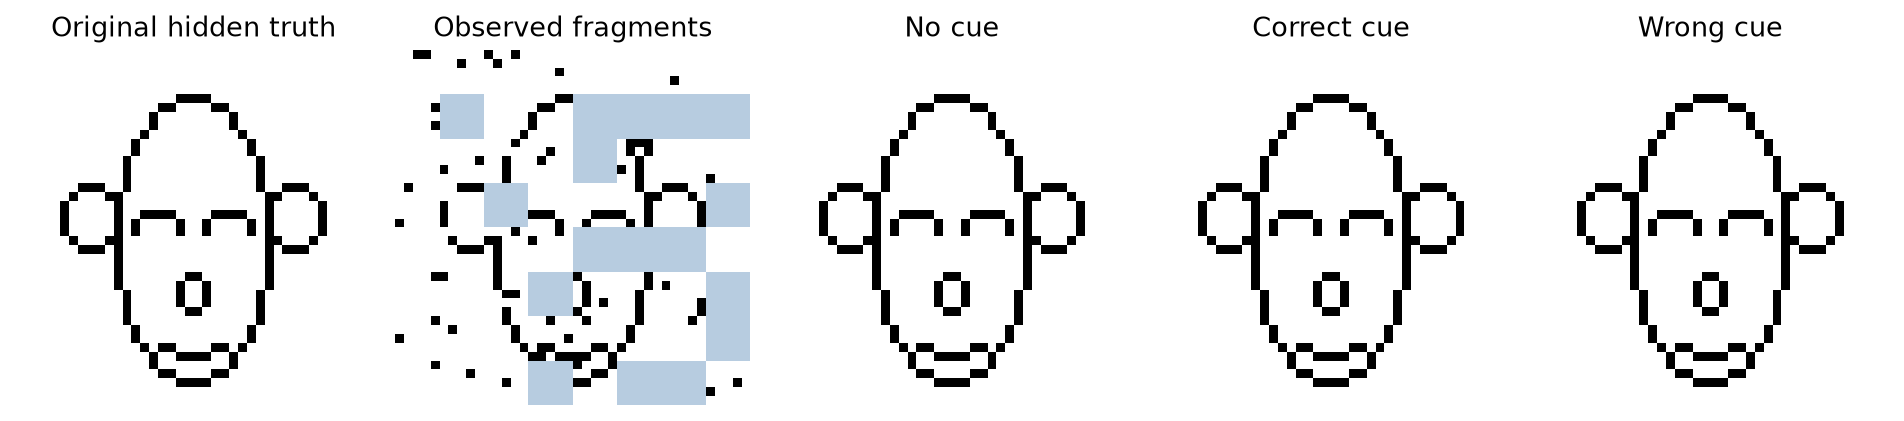

In [30]:
DEMO_CATEGORY = 2
DEMO_SEED = 67
DEMO_VISIBILITY = 0.65
CASE_STATE_ID = 499
OUT = OUT_ROOT / 'human-like_seed67_visible65'
OUT.mkdir(exist_ok=True)
print("Recipe:", describe_state(library.states[CASE_STATE_ID]))
exec(demo_source)
exec(cue_source)
plt.close("all")